# San Rafael Energy Community, PyPSA Scenario Model v18

## Study objective

The model evaluates how far the San Rafael community can reduce dependence on the EPM grid using shared PV and battery storage.

The operating priority remains:

1. serve demand directly from available PV,
2. charge the battery with surplus PV,
3. discharge the battery when PV is insufficient,
4. import from the grid only for the remaining deficit,
5. export only residual surplus after local demand and storage needs are satisfied.

The main change from v16 is the demand model.

The final HOMER XML contains **20% day-to-day variability** and **25% timestep-to-timestep variability** for the primary load. Those fields were not used in v16. In v17 they are applied to individual household profiles using the HOMER perturbation method. The individual profiles are then aggregated for the 4 to 8-house scenarios.

Each household is normalized to the same annual energy target, so the stochastic variation changes the timing and peak demand without changing the annual demand assumption.

Reference hardware:
- 4 households
- 12 × 435 W PV = 5.22 kWp DC
- 5 kW inverter
- 4 × Deye SE-G5.1 batteries
- 5 kVA local transformer
- annual 4-house demand = 7,592 kWh

The PV model and dispatch formulation are unchanged from v16.

## v18 robustness extension

This revision keeps the v17 reference realization unchanged and adds uncertainty and validation around it:

- Monte Carlo demand realizations for annual KPIs and coincident peaks
- percentile-based peak snapshots for downstream grid screening
- outage resilience across multiple start times using the battery SOC from the normal annual run
- NASA POWER GHI + Erbs hourly PV comparison against the HOMER-calibrated benchmark
- automated model diagnostics
- complete shared-versus-individual KPI aggregation
- visible notebook-level configuration and reproducible result exports

The fixed stochastic seed remains the reproducible reference case. Monte Carlo results quantify uncertainty within the HOMER stochastic-load formulation; they do not make independent hourly Gaussian noise a measured household-load model.


### v18 reporting conventions

The fixed seed `20250913` remains the reproducible reference realization, but it is not treated as the statistical centre of the stochastic-demand model. Where Monte Carlo results are available, report the median and P5–P95 interval first and use the fixed-seed result as the reproducible anchor.

Two solar representations are kept distinct:

- `HOMER_CALIBRATED_SHAPE` remains the original benchmark profile scaled to HOMER's 7,326.3 kWh/year.
- `NASA_GHI_ERBS` is the un-normalized weather-derived profile built directly from the raw NASA POWER hourly file when available. It uses GHI as the irradiance anchor, derives DNI/DHI with Erbs at the +30 minute hourly midpoint, and is the default physical handoff case for the grid study. A corrected pandapower preprocessing export is only a fallback.

The earlier normalized NASA shape-only case is retired because the corrected GHI-anchored profile already brings the weather-derived annual yield close to the HOMER benchmark without artificially scaling the instantaneous PV power.

The absence of inverter clipping in the annual PyPSA dispatch is not treated as proof that a real installation never clips. The optimized battery can absorb DC surplus when headroom is available, and a dedicated full-battery clipping stress case is outside the present energy-model scope.

Distributional outage starts are sampled on an explicit month × hour-of-day grid rather than by evenly spacing array indices. This keeps seasonal and time-of-day coverage transparent and stable if the sampling settings are edited.


### Reporting basis after the irradiance-component correction

The notebook keeps two roles separate:

- **HOMER-calibrated PV** remains the benchmark used for historical comparison with the original HOMER study.
- **NASA POWER GHI + Erbs** is the physical/reporting resource case. The PV and battery sweeps, self-sufficiency design search, shared-versus-individual comparison, outage studies, solved Monte Carlo KPI uncertainty and default pandapower handoff use this profile.

The 200–500 realization load-only peak Monte Carlo remains independent of the PV profile because it estimates coincident demand peaks only.


### Planning import and export values

The annual pandapower handoff remains the reproducible chronological NASA GHI + Erbs reference realization. It is not interpreted as a percentile planning envelope.

For network planning, v18 exports two separate percentile snapshots:

- `monte_carlo_p95_load_snapshots.csv` for high coincident demand / import stress.
- `monte_carlo_p95_export_snapshot.csv` for high reverse-flow stress from the solved NASA GHI + Erbs Monte Carlo ensemble.

The project-level self-sufficiency and design recommendations are taken from the NASA GHI + Erbs decision case. The HOMER-calibrated result is retained only as the benchmark comparison.


In [20]:
# ============================================================
# 1. GLOBAL CONFIGURATION - EDIT SCENARIOS HERE
# ============================================================

from pathlib import Path
import math
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pvlib

from IPython.display import display, Markdown

PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"

for folder in [
    DATA_DIR,
    RESULTS_DIR,
    FIGURES_DIR,
]:
    folder.mkdir(
        parents=True,
        exist_ok=True,
    )

print("Project root:", PROJECT_ROOT.resolve())
print("Data directory:", DATA_DIR.resolve())
print("Results directory:", RESULTS_DIR.resolve())
print("Figures directory:", FIGURES_DIR.resolve())

# ------------------------------------------------------------
# Input files
# ------------------------------------------------------------

HOMER_XML_CANDIDATES = [
    PROJECT_ROOT / "SimulacionTampico1k(1).xml",
    PROJECT_ROOT / "SimulacionTampico1k.xml",
    DATA_DIR / "SimulacionTampico1k(1).xml",
    DATA_DIR / "SimulacionTampico1k.xml",
]

NASA_CSV_CANDIDATES = [
    PROJECT_ROOT / "Nasa Data(2).csv",
    PROJECT_ROOT / "Nasa Data(1).csv",
    PROJECT_ROOT / "Nasa Data.csv",
    DATA_DIR / "Nasa Data(2).csv",
    DATA_DIR / "Nasa Data(1).csv",
    DATA_DIR / "Nasa Data.csv",
]

# Raw 2025 hourly NASA POWER file used for the corrected GHI + Erbs
# weather-derived PV profile. v18 builds this profile itself, so it
# no longer depends on running the pandapower notebook first.
NASA_HOURLY_CANDIDATES = [
    PROJECT_ROOT / "NASA_POWER_SanRafael_hourly_2025.csv",
    DATA_DIR / "NASA_POWER_SanRafael_hourly_2025.csv",
    PROJECT_ROOT / "NASA Data" / "NASA_POWER_SanRafael_hourly_2025.csv",
]

PV_PROFILE_COLUMN = "pv_available_kw_per_kwp"

# ------------------------------------------------------------
# Project / electrical reference
# ------------------------------------------------------------

MODEL_YEAR = 2025

# EPM local reference transformer
TRAFO_NUMBER = "94022"
TRAFO_NODE = "931076"
TRAFO_LAT = 6.246949759
TRAFO_LON = -75.006208238

PROJECT_REFERENCE_LAT = 6.247444
PROJECT_REFERENCE_LON = -75.007889

# NASA POWER hourly resource point and PV conversion assumptions.
NASA_SITE_LAT = 6.2523
NASA_SITE_LON = -75.0143
NASA_SITE_ALTITUDE_M = 1291.33
NASA_TIMEZONE_FOR_SOLAR_POSITION = "Etc/GMT+5"
SOLAR_POSITION_INTERVAL_MIDPOINT_MIN = 30

PV_SURFACE_TILT_DEG = 5.0
PV_SURFACE_AZIMUTH_DEG = 180.0
PV_DERATING_FACTOR = 0.80
PV_TEMP_COEFF_PER_C = -0.003
PV_NOCT_C = 45.0

POA_TO_GHI_ANNUAL_RATIO_MIN = 0.98
POA_TO_GHI_ANNUAL_RATIO_MAX = 1.05
COMPONENT_CLOSURE_MAX_REL_ERROR = 0.02

EPM_CIRCUIT = "221-12"
MV_VOLTAGE_KV = 7.621
LV_VOLTAGE_KV = 0.240
TRANSFORMER_KVA = 5.0

PRIMARY_CONDUCTOR = "#2 ACSR"
SECONDARY_CONDUCTOR = "1/0 AAC"
PRIMARY_LENGTH_M = 354.2
SECONDARY_LENGTH_M = 324.5

HOUSES_PER_LV_BRANCH = 2

# ------------------------------------------------------------
# Stochastic household demand
# ------------------------------------------------------------

USE_STOCHASTIC_HOUSEHOLD_LOADS = True
STOCHASTIC_LOAD_SEED = 20250913

# Generate enough individual profiles for the PyPSA 4-8 house study
# and the pandapower transformer-headroom sensitivity.
STOCHASTIC_PROFILE_HOUSE_COUNT = 20

# HOMER uses alpha = 1 + daily perturbation + timestep perturbation.
# Demand is constrained to remain non-negative.
STOCHASTIC_MIN_FACTOR = 0.0

# ------------------------------------------------------------
# Scenario sweeps
# ------------------------------------------------------------

HOUSE_GROUP_SIZE_SWEEP = [4, 5, 6, 7, 8]
PV_PANEL_COUNT_SWEEP = [4, 6, 8, 10, 12]
MAX_PV_PANEL_COUNT = 12
BESS_MODULE_COUNT_SWEEP = [0, 1, 2, 3, 4]
SS_TARGETS = [0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 1.00]

# ------------------------------------------------------------
# Accepted reference-system anchors
# ------------------------------------------------------------

# The quotation is the primary installed-cost reference.
QUOTED_REFERENCE_SUBTOTAL_USD = 11974.79
QUOTED_REFERENCE_TOTAL_WITH_VAT_USD = 14250.00

# The final HOMER report models the four-battery bank as 19.2 kWh nominal
# and 17.3 kWh usable, even though the product description says 5.12 kWh.
# PyPSA follows the HOMER-modelled capacities for benchmark consistency.
HOMER_REFERENCE_BATTERY_NOMINAL_KWH = 19.2
HOMER_REFERENCE_BATTERY_USABLE_KWH = 17.3
HOMER_REFERENCE_BATTERY_ENERGY_IN_KWH = 18.2
HOMER_REFERENCE_BATTERY_ENERGY_OUT_KWH = 17.3
HOMER_REFERENCE_BATTERY_WEAR_USD_PER_KWH = 0.052

# ------------------------------------------------------------
# Dispatch logic
# ------------------------------------------------------------

# Grid-last-resort priority coefficient.
# This is NOT an electricity tariff.
GRID_LAST_RESORT_PENALTY_USD_PER_KWH = 10.0

# Residual export is allowed, but local use and storage take priority.
RESIDUAL_EXPORT_PRIORITY_VALUE_USD_PER_KWH = 0.001

# Battery charging from the grid is not part of the community strategy.
ALLOW_GRID_BATTERY_CHARGING = False

# Optional zero-export sensitivity
RUN_ZERO_EXPORT_CASE = False

# ------------------------------------------------------------
# Outage / resilience
# ------------------------------------------------------------

OUTAGE_START_TIMESTAMP = "2025-09-15 18:00"
OUTAGE_DURATION_H = 12
OUTAGE_DURATION_SWEEP_H = [4, 8, 12, 24]
OUTAGE_START_SOC_PU = 0.80
UNSERVED_ENERGY_PENALTY_USD_PER_KWH = 10.0

# ------------------------------------------------------------
# Cost scaling for design comparison only
# ------------------------------------------------------------

LINEAR_PV_CAPEX_FOR_PANEL_SWEEP = True
LINEAR_BESS_CAPEX_FOR_MODULE_SWEEP = True
LINEAR_CONVERTER_CAPEX_FOR_POWER = True

# ------------------------------------------------------------
# Individual versus shared benchmark
# ------------------------------------------------------------

INDIVIDUAL_PANEL_COUNT_PER_HOUSE = 3
INDIVIDUAL_BESS_MODULES_PER_HOUSE = 1

# ------------------------------------------------------------
# Execution switches
# ------------------------------------------------------------

RUN_CORE_CASES = True
RUN_PV_SWEEP = True
RUN_BESS_SWEEP = True
RUN_SS_SEARCH = True
RUN_OUTAGE = True
RUN_OUTAGE_DURATION_SWEEP = True
RUN_INDIVIDUAL_VS_SHARED = True

# ------------------------------------------------------------
# v18 uncertainty / robustness
# ------------------------------------------------------------

MC_SOLVED_REALIZATIONS = 30
MC_PEAK_REALIZATIONS = 300
MC_PEAK_PERCENTILE = 95.0
MC_HOUSE_COUNTS = HOUSE_GROUP_SIZE_SWEEP.copy()
MC_BASE_SEED = 20260929

# Set False for a quicker reference-only run.
RUN_MONTE_CARLO_PEAK = True
RUN_MONTE_CARLO_KPI = True
RUN_DISTRIBUTIONAL_OUTAGE = True
RUN_NASA_PV_SHAPE_SENSITIVITY = True

# Distributional outage sample grid.
# One mid-month day in every month × four start hours = 48 starts.
# Coverage is therefore explicit rather than an artefact of linspace spacing.
OUTAGE_SAMPLE_DAY_OF_MONTH = 15
OUTAGE_SAMPLE_HOURS = [0, 3, 6, 9, 12, 15, 18, 21]

SAVE_FIGURES = True
SHOW_FIGURES_INLINE = True

SOLVER = "highs"

KW_TO_MW = 1e-3
KWH_TO_MWH = 1e-3
USD_PER_KWH_TO_USD_PER_MWH = 1e3


def explain(text):
    display(Markdown(f"**Interpretation.** {text}"))


def show_table(df, title, explanation):
    display(Markdown(f"### {title}"))
    display(df)
    explain(explanation)


print("Configuration loaded from notebook.")


Project root: D:\0. UoL\SEEDExchange\sanrafaelutility-main
Data directory: D:\0. UoL\SEEDExchange\sanrafaelutility-main\Data
Results directory: D:\0. UoL\SEEDExchange\sanrafaelutility-main\results
Figures directory: D:\0. UoL\SEEDExchange\sanrafaelutility-main\results\figures
Configuration loaded from notebook.


## 2. Read the final HOMER reference

The final HOMER file supplies the accepted component sizes, grid tariffs, converter efficiencies, battery parameters, annual PV production and primary-load variability settings.

For the primary load, the XML specifies:

- **20% day-to-day variability**
- **25% timestep-to-timestep variability**

HOMER applies a perturbation factor

\[
\alpha = 1 + \delta_d + \delta_{ts}
\]

where the daily perturbation is drawn once per day and the timestep perturbation is drawn every hour from zero-mean normal distributions with the configured standard deviations.

The random seed used by the original HOMER run is not available, so this notebook reproduces the method and variability settings, not HOMER's exact random realization.

HOMER remains reference context rather than a separate PyPSA dispatch objective.

In [21]:
# ============================================================
# 2. HOMER XML PARSER
# ============================================================

def find_first_existing(paths):
    for p in paths:
        if p.exists():
            return p
    raise FileNotFoundError(
        "Put SimulacionTampico1k(1).xml beside the notebook or under ./data"
    )

HOMER_XML_FILE = find_first_existing(HOMER_XML_CANDIDATES)

def _text(root, path, default=None):
    node = root.find(path)
    return default if node is None or node.text is None else node.text.strip()

def _float(root, path, default=np.nan):
    x = _text(root, path, None)
    return default if x is None else float(x)

def parse_homer_xml(path):
    root = ET.parse(path).getroot()
    sd = root.find("system_description")
    ref = {}

    # PV
    ref["pv_kwp"] = _float(sd, "pv/size")
    ref["pv_capex_usd"] = _float(sd, "pv/capital_cost")
    ref["pv_replacement_usd"] = _float(sd, "pv/replacement_cost")
    ref["pv_lifetime_y"] = _float(sd, "pv/lifetime")

    # Converter
    ref["inverter_kw"] = _float(sd, "converter/inverter_size")
    ref["rectifier_kw"] = _float(sd, "converter/rectifier_size")
    ref["converter_capex_usd"] = _float(sd, "converter/capital_cost")
    ref["converter_replacement_usd"] = _float(sd, "converter/replacement_cost")
    ref["inverter_efficiency"] = _float(
        sd, "converter/inverter_efficiency"
    ) / 100
    ref["rectifier_efficiency"] = _float(
        sd, "converter/rectifier_efficiency"
    ) / 100

    # Battery
    bat = sd.find("battery")
    ref["battery_description"] = _text(
        bat, "battery_properties/description"
    )
    ref["battery_modules"] = int(
        float(_text(bat, "cell_battery/quantity"))
    )
    ref["battery_bank_capex_usd"] = _float(
        bat, "cell_battery/capital_cost"
    )
    ref["battery_bank_replacement_usd"] = _float(
        bat, "cell_battery/replacement_cost"
    )
    ref["battery_nominal_ah"] = _float(
        bat, "battery_properties/nominal_capacity"
    )
    ref["battery_nominal_v"] = _float(
        bat, "battery_properties/nominal_voltage"
    )
    ref["battery_roundtrip_efficiency"] = _float(
        bat, "battery_properties/roundtrip_efficiency"
    ) / 100
    ref["battery_min_soc_pu"] = _float(
        bat, "battery_properties/min_state_of_charge"
    ) / 100
    ref["battery_max_charge_current_a"] = _float(
        bat, "battery_properties/max_charge_current"
    )
    ref["battery_lifetime_throughput_kwh_per_module"] = _float(
        bat, "battery_properties/lifetime_throughput"
    )
    ref["battery_float_life_y"] = _float(
        bat, "battery_properties/float_life"
    )

    # HOMER-modelled module energy from 100 Ah × 48 V.
    # This gives 4.8 kWh/module and 19.2 kWh for four modules,
    # matching the final HOMER system report.
    ref["battery_module_kwh"] = (
        ref["battery_nominal_ah"]
        * ref["battery_nominal_v"]
        / 1000
    )

    ref["battery_bank_nominal_kwh_reference"] = (
        HOMER_REFERENCE_BATTERY_NOMINAL_KWH
    )
    ref["battery_bank_usable_kwh_reference"] = (
        HOMER_REFERENCE_BATTERY_USABLE_KWH
    )

    total_lifetime_throughput = (
        ref["battery_modules"]
        * ref["battery_lifetime_throughput_kwh_per_module"]
    )
    ref["battery_lifetime_throughput_kwh"] = (
        total_lifetime_throughput
    )

    # Use the final HOMER report value directly.
    ref["battery_wear_cost_usd_per_kwh"] = (
        HOMER_REFERENCE_BATTERY_WEAR_USD_PER_KWH
    )

    # Grid
    ref["grid_buy_usd_per_kwh"] = _float(
        sd, "grid/grid_connection/rates/rate/grid_power_price"
    )
    ref["grid_sell_usd_per_kwh"] = _float(
        sd, "grid/grid_connection/rates/rate/sellback_rate"
    )
    ref["grid_purchase_capacity_kw"] = _float(
        sd, "grid/grid_connection/purchase_capacity"
    )
    ref["grid_sale_capacity_kw"] = _float(
        sd, "grid/grid_connection/sale_capacity"
    )

    # Economics
    ref["discount_rate"] = _float(
        sd, "economics/annual_real_interest_rate"
    ) / 100
    ref["project_lifetime_y"] = int(
        _float(sd, "economics/project_lifetime")
    )

    # Load
    ref["reference_houses"] = 4
    ref["daily_load_4hh_kwh"] = _float(
        sd, "primary_load/scaled_annual_average"
    )
    ref["annual_load_4hh_kwh"] = (
        ref["daily_load_4hh_kwh"] * 365
    )

    months = [
        "jan","feb","mar","apr","may","jun",
        "jul","aug","sep","oct","nov","dec"
    ]

    weekday_profiles = {}
    weekend_profiles = {}

    for month in months:
        for day_type, store in [
            ("weekday", weekday_profiles),
            ("weekend", weekend_profiles),
        ]:
            arr = _text(
                sd,
                f"primary_load/data/monthly/daily_profiles/"
                f"{month}/{day_type}/float_array"
            )

            vals = np.array(
                [float(v) for v in arr.split()],
                dtype=float
            )

            if len(vals) != 24:
                raise ValueError(
                    f"{month} {day_type}: expected 24 load values"
                )

            store[month] = vals

    ref["monthly_load_profiles_weekday_4hh_kw"] = weekday_profiles
    ref["monthly_load_profiles_weekend_4hh_kw"] = weekend_profiles

    # Backward-compatible alias for plotting.
    ref["monthly_load_profiles_4hh_kw"] = weekday_profiles

    ref["load_daily_variability_pu"] = (
        _float(
            sd,
            "primary_load/data/monthly/daily_noise"
        )
        / 100.0
    )

    ref["load_timestep_variability_pu"] = (
        _float(
            sd,
            "primary_load/data/monthly/hourly_noise"
        )
        / 100.0
    )

    # Solar
    rad = sd.find(
        "solar_resource/data/monthly/monthly_average_radiation"
    )
    ref["monthly_radiation_kwh_m2_day"] = np.array(
        [float(n.text) for n in rad.findall("float")]
    )

    # Locale
    lat_deg = _float(sd, "locale/latitude/degrees")
    lat_min = _float(sd, "locale/latitude/minutes")
    lon_deg = _float(sd, "locale/longitude/degrees")
    lon_min = _float(sd, "locale/longitude/minutes")

    ref["homer_lat"] = lat_deg + lat_min / 60
    ref["homer_lon"] = -(lon_deg + lon_min / 60)

    # Benchmark outputs
    sr = root.find("simulation_results")

    if sr is not None:
        ref["homer_npc_usd"] = _float(
            sr, "cost_summary/total_net_present_cost"
        )
        ref["homer_lcoe_usd_per_kwh"] = _float(
            sr, "cost_summary/levelized_coe"
        )
        ref["homer_pv_kwh"] = _float(
            sr, "annual_electric_production/pv"
        )
        ref["homer_grid_import_kwh"] = _float(
            sr, "annual_electric_production/grid_purchases"
        )
        ref["homer_load_served_kwh"] = _float(
            sr,
            "annual_electric_consumption/ac_primary_load_served"
        )
        ref["homer_grid_export_kwh"] = _float(
            sr, "annual_electric_consumption/grid_sales"
        )
        ref["homer_renewable_fraction"] = _float(
            sr, "annual_statistics/renewable_fraction"
        )
        ref["homer_battery_throughput_kwh"] = _float(
            sr, "battery/throughput"
        )

        ref["homer_battery_energy_in_kwh"] = (
            HOMER_REFERENCE_BATTERY_ENERGY_IN_KWH
        )
        ref["homer_battery_energy_out_kwh"] = (
            HOMER_REFERENCE_BATTERY_ENERGY_OUT_KWH
        )

    return ref

HOMER = parse_homer_xml(HOMER_XML_FILE)

summary = pd.DataFrame({
    "Value": {
        "Reference houses": HOMER["reference_houses"],
        "PV [kWp DC]": HOMER["pv_kwp"],
        "Inverter [kW]": HOMER["inverter_kw"],
        "Inverter efficiency": HOMER["inverter_efficiency"],
        "Rectifier efficiency": HOMER["rectifier_efficiency"],
        "Battery modules": HOMER["battery_modules"],
        "Battery bank [kWh nominal, HOMER model]":
            HOMER["battery_bank_nominal_kwh_reference"],
        "Battery bank [kWh usable, HOMER model]":
            HOMER["battery_bank_usable_kwh_reference"],
        "Battery round-trip efficiency":
            HOMER["battery_roundtrip_efficiency"],
        "Battery wear cost [USD/kWh throughput]":
            HOMER["battery_wear_cost_usd_per_kwh"],
        "Quoted reference subtotal [USD]":
            QUOTED_REFERENCE_SUBTOTAL_USD,
        "Quoted reference total incl. VAT [USD]":
            QUOTED_REFERENCE_TOTAL_WITH_VAT_USD,
        "4-house annual load [kWh]":
            HOMER["annual_load_4hh_kwh"],
        "HOMER day-to-day load variability":
            HOMER["load_daily_variability_pu"],
        "HOMER timestep load variability":
            HOMER["load_timestep_variability_pu"],
        "Grid buy [USD/kWh]":
            HOMER["grid_buy_usd_per_kwh"],
        "Grid sell [USD/kWh]":
            HOMER["grid_sell_usd_per_kwh"],
        "Project lifetime [y]":
            HOMER["project_lifetime_y"],
        "Real discount rate":
            HOMER["discount_rate"],
        "EPM transformer":
            TRAFO_NUMBER,
    }
})

show_table(
    summary,
    "Reference inputs",
    "The electrical reference follows the final HOMER model, while the installed-cost level is anchored to the actual quotation. "
    "PyPSA does not reproduce HOMER dispatch because the community strategy deliberately prioritizes self-sufficiency."
)


### Reference inputs

,Value
Reference houses,4
PV [kWp DC],5.22
Inverter [kW],5.0
Inverter efficiency,0.95
Rectifier efficiency,0.85
Battery modules,4
"Battery bank [kWh nominal, HOMER model]",19.2
"Battery bank [kWh usable, HOMER model]",17.3
Battery round-trip efficiency,0.95
Battery wear cost [USD/kWh throughput],0.052


**Interpretation.** The electrical reference follows the final HOMER model, while the installed-cost level is anchored to the actual quotation. PyPSA does not reproduce HOMER dispatch because the community strategy deliberately prioritizes self-sufficiency.

## 3. Build stochastic household demand profiles

The HOMER monthly weekday/weekend profiles provide the expected demand shape. The XML stochastic settings are then applied separately to each synthetic household.

For each household:

1. start from the HOMER monthly 24-hour profile divided by four,
2. draw one daily perturbation for each day,
3. draw one timestep perturbation for each hour,
4. apply `alpha = 1 + delta_day + delta_timestep`,
5. prevent negative demand,
6. normalize the household back to **1,898 kWh/year**.

The standard deviations are read directly from the final HOMER XML:

- day-to-day: **20%**
- timestep-to-timestep: **25%**

A fixed random seed makes the profiles reproducible.

The individual profiles are independent, so aggregation introduces household diversity. The 4-house annual demand remains exactly 7,592 kWh, while the hourly demand and peak are no longer deterministic.

The original deterministic profile is retained only for comparison.

In [22]:
# ============================================================
# 3. STOCHASTIC HOUSEHOLD LOAD PROFILES
# ============================================================

MONTH_KEY = {
    1: "jan", 2: "feb", 3: "mar", 4: "apr",
    5: "may", 6: "jun", 7: "jul", 8: "aug",
    9: "sep", 10: "oct", 11: "nov", 12: "dec",
}


def build_deterministic_reference_load(index):
    raw_4hh = np.empty(len(index), dtype=float)

    for i, ts in enumerate(index):
        month = MONTH_KEY[ts.month]

        profiles = (
            HOMER["monthly_load_profiles_weekend_4hh_kw"]
            if ts.weekday() >= 5
            else HOMER["monthly_load_profiles_weekday_4hh_kw"]
        )

        raw_4hh[i] = profiles[month][ts.hour]

    target_4hh_kwh = HOMER["annual_load_4hh_kwh"]
    raw_4hh *= target_4hh_kwh / raw_4hh.sum()

    return pd.Series(
        raw_4hh,
        index=index,
        name="deterministic_load_4hh_kw",
    )


def homer_stochastic_household_profile(
    deterministic_1hh_kw,
    rng,
    daily_sigma,
    timestep_sigma,
    annual_target_kwh,
    return_diagnostics=False,
):
    index = deterministic_1hh_kw.index

    day_codes = index.dayofyear.to_numpy() - 1
    n_days = int(index.dayofyear.max())

    daily_delta = rng.normal(
        loc=0.0,
        scale=daily_sigma,
        size=n_days,
    )

    timestep_delta = rng.normal(
        loc=0.0,
        scale=timestep_sigma,
        size=len(index),
    )

    alpha_raw = (
        1.0
        + daily_delta[day_codes]
        + timestep_delta
    )

    clipped_mask = alpha_raw < STOCHASTIC_MIN_FACTOR
    alpha = np.maximum(
        alpha_raw,
        STOCHASTIC_MIN_FACTOR,
    )

    varied = (
        deterministic_1hh_kw.to_numpy(dtype=float)
        * alpha
    )

    if varied.sum() <= 0:
        raise ValueError(
            "Stochastic profile has zero annual energy before normalization."
        )

    varied *= (
        annual_target_kwh
        / varied.sum()
    )

    series = pd.Series(
        varied,
        index=index,
        dtype=float,
    )

    if not return_diagnostics:
        return series

    return series, {
        "clipped_hours": int(clipped_mask.sum()),
        "clipped_share_pct": 100 * float(clipped_mask.mean()),
        "minimum_raw_factor": float(alpha_raw.min()),
        "maximum_raw_factor": float(alpha_raw.max()),
    }


def build_reference_load_8760(
    seed=STOCHASTIC_LOAD_SEED,
    profile_house_count=STOCHASTIC_PROFILE_HOUSE_COUNT,
):
    idx = pd.date_range(
        f"{MODEL_YEAR}-01-01 00:00",
        f"{MODEL_YEAR}-12-31 23:00",
        freq="h",
    )

    deterministic_4hh = (
        build_deterministic_reference_load(idx)
    )

    deterministic_1hh = (
        deterministic_4hh
        / HOMER["reference_houses"]
    )

    annual_1hh_kwh = (
        HOMER["annual_load_4hh_kwh"]
        / HOMER["reference_houses"]
    )

    df = pd.DataFrame(index=idx)
    df.index.name = "timestamp"

    df["deterministic_load_1hh_kw"] = deterministic_1hh
    df["deterministic_load_4hh_kw"] = deterministic_4hh

    clipped_total = 0

    if USE_STOCHASTIC_HOUSEHOLD_LOADS:
        seed_sequence = np.random.SeedSequence(
            int(seed)
        )

        child_seeds = seed_sequence.spawn(
            int(profile_house_count)
        )

        for house in range(
            1,
            int(profile_house_count) + 1,
        ):
            rng = np.random.default_rng(
                child_seeds[house - 1]
            )

            profile, diag = (
                homer_stochastic_household_profile(
                    deterministic_1hh_kw=deterministic_1hh,
                    rng=rng,
                    daily_sigma=HOMER[
                        "load_daily_variability_pu"
                    ],
                    timestep_sigma=HOMER[
                        "load_timestep_variability_pu"
                    ],
                    annual_target_kwh=annual_1hh_kwh,
                    return_diagnostics=True,
                )
            )

            df[f"house_{house}_kw"] = profile
            clipped_total += diag["clipped_hours"]
    else:
        for house in range(
            1,
            int(profile_house_count) + 1,
        ):
            df[f"house_{house}_kw"] = deterministic_1hh

    running = np.zeros(len(df), dtype=float)

    for houses in range(
        1,
        int(profile_house_count) + 1,
    ):
        running = (
            running
            + df[f"house_{houses}_kw"].to_numpy()
        )

        df[f"load_{houses}hh_kw"] = running.copy()

    df["load_1hh_kw"] = df["house_1_kw"]

    denominator = len(df) * int(profile_house_count)
    df.attrs["stochastic_seed"] = int(seed)
    df.attrs["clipped_household_hours"] = clipped_total
    df.attrs["clipped_household_hours_pct"] = (
        100 * clipped_total / denominator
        if denominator
        else 0.0
    )

    return df


def group_load_kw(ts, houses):
    col = f"load_{int(houses)}hh_kw"

    if col not in ts.columns:
        raise KeyError(
            f"{col} not available. "
            f"Generated profiles cover up to "
            f"{STOCHASTIC_PROFILE_HOUSE_COUNT} houses."
        )

    return ts[col]


TS = build_reference_load_8760()

print(
    "HOMER load variability:",
    f"{100 * HOMER['load_daily_variability_pu']:.0f}% day-to-day,",
    f"{100 * HOMER['load_timestep_variability_pu']:.0f}% timestep",
)
print("Reference stochastic seed:", STOCHASTIC_LOAD_SEED)
print(
    "Clipped stochastic household-hours:",
    TS.attrs["clipped_household_hours"],
    f"({TS.attrs['clipped_household_hours_pct']:.4f}%)",
)
print(
    "4-house annual load:",
    TS["load_4hh_kw"].sum(),
    "kWh",
)
print(
    "4-house stochastic peak:",
    TS["load_4hh_kw"].max(),
    "kW",
)
print(
    "4-house deterministic peak:",
    TS["deterministic_load_4hh_kw"].max(),
    "kW",
)

load_summary_rows = []

for houses in HOUSE_GROUP_SIZE_SWEEP:
    series = group_load_kw(TS, houses)

    load_summary_rows.append({
        "houses": houses,
        "annual_load_kwh": series.sum(),
        "average_load_kw": series.mean(),
        "peak_load_kw": series.max(),
        "load_factor":
            series.mean() / series.max(),
    })

stochastic_load_summary = pd.DataFrame(
    load_summary_rows
)

show_table(
    stochastic_load_summary.round(4),
    "Reference stochastic demand summary",
    "The fixed seed is retained as the reproducible reference realization. "
    "Monte Carlo analysis later in the notebook quantifies seed-to-seed uncertainty."
)

profile_columns = [
    "deterministic_load_1hh_kw",
    "deterministic_load_4hh_kw",
] + [
    f"house_{h}_kw"
    for h in range(
        1,
        STOCHASTIC_PROFILE_HOUSE_COUNT + 1,
    )
] + [
    f"load_{h}hh_kw"
    for h in range(
        1,
        STOCHASTIC_PROFILE_HOUSE_COUNT + 1,
    )
]

TS[profile_columns].to_csv(
    RESULTS_DIR / "stochastic_household_load_profiles.csv"
)

stochastic_load_summary.to_csv(
    RESULTS_DIR / "stochastic_load_summary.csv",
    index=False,
)


HOMER load variability: 20% day-to-day, 25% timestep
Reference stochastic seed: 20250913
Clipped stochastic household-hours: 168 (0.0959%)
4-house annual load: 7592.0 kWh
4-house stochastic peak: 2.166677435937405 kW
4-house deterministic peak: 1.4963834557023217 kW


### Reference stochastic demand summary

,houses,annual_load_kwh,average_load_kw,peak_load_kw,load_factor
0,4,7592.0,0.8667,2.1667,0.4000
1,5,9490.0,1.0833,2.5193,0.4300
2,6,11388.0,1.3000,2.9979,0.4336
3,7,13286.0,1.5167,3.7174,0.4080
4,8,15184.0,1.7333,4.1833,0.4143


**Interpretation.** The fixed seed is retained as the reproducible reference realization. Monte Carlo analysis later in the notebook quantifies seed-to-seed uncertainty.

## 4. Hourly PV availability

NASA POWER provides the monthly solar-resource pattern for the project area. A deterministic hourly daylight profile is constructed from solar geometry and the monthly NASA radiation values.

The resulting hourly series is calibrated so that the final HOMER reference array, 5.22 kWp, reproduces the accepted HOMER annual PV production. This provides a consistent hourly series for PyPSA while retaining the final HOMER annual energy result.


In [23]:
# ============================================================
# 4. NASA / HOMER-CALIBRATED PV PROFILE
# ============================================================

def find_optional_file(paths):
    for p in paths:
        if p.exists():
            return p
    return None

NASA_CSV_FILE = find_optional_file(NASA_CSV_CANDIDATES)

def load_nasa_monthly_radiation(path):
    """
    Returns long-term monthly mean ALLSKY_SFC_SW_DWN in kWh/m²/day.
    """
    raw = pd.read_csv(path, skiprows=13)
    solar = raw[raw["PARAMETER"] == "ALLSKY_SFC_SW_DWN"].copy()

    month_cols = ["JAN","FEB","MAR","APR","MAY","JUN",
                  "JUL","AUG","SEP","OCT","NOV","DEC"]

    if solar.empty:
        raise ValueError("ALLSKY_SFC_SW_DWN not found in NASA POWER file.")

    solar[month_cols] = solar[month_cols].apply(pd.to_numeric, errors="coerce")
    monthly = solar[month_cols].mean(axis=0).to_numpy(dtype=float)

    if np.isnan(monthly).any():
        raise ValueError("NASA monthly solar radiation contains missing values.")

    return monthly

if NASA_CSV_FILE is not None:
    MONTHLY_SOLAR_RADIATION = load_nasa_monthly_radiation(NASA_CSV_FILE)
    SOLAR_RESOURCE_SOURCE = f"NASA POWER: {NASA_CSV_FILE.name}"
else:
    MONTHLY_SOLAR_RADIATION = HOMER["monthly_radiation_kwh_m2_day"].copy()
    SOLAR_RESOURCE_SOURCE = "Monthly solar radiation stored in final HOMER XML"

print("Solar resource source:", SOLAR_RESOURCE_SOURCE)
print("Monthly mean solar radiation [kWh/m²/day]:")
show_table(
    pd.Series(
        MONTHLY_SOLAR_RADIATION,
        index=["Jan","Feb","Mar","Apr","May","Jun",
               "Jul","Aug","Sep","Oct","Nov","Dec"]
    ).to_frame("kWh/m²/day"),
    "Monthly solar resource",
    "The monthly values set the seasonal solar pattern. "
    "The hourly shape is reconstructed deterministically and then "
    "scaled to reproduce the accepted HOMER annual PV production."
)

def solar_day_shape(index, latitude_deg):
    lat = np.deg2rad(latitude_deg)
    doy = index.dayofyear.to_numpy()
    hour = index.hour.to_numpy() + 0.5

    decl = np.deg2rad(23.45) * np.sin(2*np.pi*(284 + doy)/365.0)
    cos_ws = np.clip(-np.tan(lat) * np.tan(decl), -1, 1)
    ws = np.arccos(cos_ws)

    daylength = 24 * ws / np.pi
    sunrise = 12 - daylength / 2
    sunset = 12 + daylength / 2

    x = (hour - sunrise) / np.maximum(daylength, 1e-6)

    return np.where(
        (hour >= sunrise) & (hour <= sunset),
        np.sin(np.pi * np.clip(x, 0, 1)),
        0.0
    )

def build_calibrated_pv_profile(index):
    daylight = solar_day_shape(index, HOMER["homer_lat"])

    monthly_weight = np.array([
        MONTHLY_SOLAR_RADIATION[m - 1] for m in index.month
    ])

    base = daylight * monthly_weight
    base = base / base.max()

    # HOMER reports PV production on the DC side. Scale the reconstructed
    # hourly profile so the annual DC energy matches that accepted result.
    target_kwh = HOMER["homer_pv_kwh"]
    reference_pv_kwp = HOMER["pv_kwp"]

    raw_energy_kwh = (
        reference_pv_kwp * base
    ).sum()

    scale = (
        target_kwh / raw_energy_kwh
    )

    calibrated = (
        base * scale
    )

    return pd.Series(
        calibrated,
        index=index,
        name=PV_PROFILE_COLUMN
    )

TS[PV_PROFILE_COLUMN] = build_calibrated_pv_profile(TS.index)
TS.attrs["pv_profile_source"] = "HOMER-calibrated benchmark"

reference_pv_dc_kw = (
    HOMER["pv_kwp"]
    * TS[PV_PROFILE_COLUMN]
)

print(
    f"Calibrated annual PV DC production: "
    f"{reference_pv_dc_kw.sum():.1f} kWh"
)
print(
    f"HOMER annual PV production:          "
    f"{HOMER['homer_pv_kwh']:.1f} kWh"
)


# ------------------------------------------------------------
# Optional NASA POWER GHI + Erbs hourly PV comparison
# ------------------------------------------------------------

NASA_PV_SHAPE_CANDIDATES = [
    PROJECT_ROOT / "pandapower_results_nasa" / "nasa_hourly_pv_and_load_inputs.csv",
    RESULTS_DIR / "nasa_hourly_pv_and_load_inputs.csv",
    DATA_DIR / "nasa_hourly_pv_and_load_inputs.csv",
    PROJECT_ROOT / "nasa_hourly_pv_and_load_inputs.csv",
]


def _load_corrected_preprocessed_nasa_pv(index):
    """Optional fallback: read a corrected NASA GHI+Erbs profile exported by pandapower v5."""
    path = find_optional_file(NASA_PV_SHAPE_CANDIDATES)
    if path is None:
        return None, None, None

    df = pd.read_csv(path, parse_dates=["timestamp"])
    required = {"timestamp", "nasa_pv_dc_kw", "pv_profile_method"}
    missing = required - set(df.columns)
    if missing:
        return None, path, f"stale preprocessed file missing {sorted(missing)}"

    methods = set(df["pv_profile_method"].dropna().astype(str).unique())
    if methods != {"NASA_GHI_ERBS_MIDPOINT"}:
        return None, path, f"unexpected method tag {sorted(methods)}"

    native_kw = df.set_index("timestamp")["nasa_pv_dc_kw"].reindex(index).astype(float)
    if native_kw.isna().any():
        return None, path, "timestamps do not align with the PyPSA model year"
    if native_kw.sum() <= 0:
        return None, path, "annual PV energy is zero"
    return native_kw, path, None


def _build_nasa_ghi_erbs_pv_from_raw(index):
    """Build corrected hourly PV directly from the raw 2025 NASA POWER hourly file."""
    path = find_optional_file(NASA_HOURLY_CANDIDATES)
    if path is None:
        return None, None, None

    raw = pd.read_csv(path, parse_dates=["timestamp_lst"])
    required = {"timestamp_lst", "ALLSKY_SFC_SW_DWN", "T2M"}
    missing = required - set(raw.columns)
    if missing:
        raise ValueError(f"{path.name} is missing required NASA hourly columns: {sorted(missing)}")

    work = raw.rename(columns={"timestamp_lst": "timestamp"}).copy()
    for col in ["ALLSKY_SFC_SW_DWN", "T2M"]:
        work[col] = pd.to_numeric(work[col], errors="coerce")
        work.loc[work[col] <= -900, col] = np.nan
    if work[["ALLSKY_SFC_SW_DWN", "T2M"]].isna().any().any():
        raise ValueError("NASA hourly GHI/T2M contains missing or fill values.")

    work = work.set_index("timestamp").reindex(index)
    if work[["ALLSKY_SFC_SW_DWN", "T2M"]].isna().any().any():
        raise ValueError("Raw NASA hourly timestamps do not align with the PyPSA model year.")

    solar_times = pd.DatetimeIndex(index).tz_localize(NASA_TIMEZONE_FOR_SOLAR_POSITION)
    solar_times_midpoint = solar_times + pd.Timedelta(minutes=SOLAR_POSITION_INTERVAL_MIDPOINT_MIN)
    solar_position = pvlib.solarposition.get_solarposition(
        time=solar_times_midpoint,
        latitude=NASA_SITE_LAT,
        longitude=NASA_SITE_LON,
        altitude=NASA_SITE_ALTITUDE_M,
    )

    ghi = work["ALLSKY_SFC_SW_DWN"].to_numpy(dtype=float)
    zenith = solar_position["zenith"].to_numpy(dtype=float)
    apparent_zenith = solar_position["apparent_zenith"].to_numpy(dtype=float)
    solar_azimuth = solar_position["azimuth"].to_numpy(dtype=float)
    cos_zenith = np.clip(np.cos(np.deg2rad(zenith)), 0.0, None)

    erbs = pvlib.irradiance.erbs(ghi=ghi, zenith=zenith, datetime_or_doy=solar_times_midpoint)
    dni = np.clip(np.asarray(erbs["dni"], dtype=float), 0.0, None)
    dhi = np.clip(np.asarray(erbs["dhi"], dtype=float), 0.0, None)
    horizontal_reconstructed = dni * cos_zenith + dhi

    poa = pvlib.irradiance.get_total_irradiance(
        surface_tilt=PV_SURFACE_TILT_DEG,
        surface_azimuth=PV_SURFACE_AZIMUTH_DEG,
        solar_zenith=apparent_zenith,
        solar_azimuth=solar_azimuth,
        dni=dni,
        ghi=ghi,
        dhi=dhi,
        albedo=0.20,
        model="isotropic",
    )
    poa_global = np.clip(np.asarray(poa["poa_global"], dtype=float), 0.0, None)

    cell_temperature = work["T2M"].to_numpy(dtype=float) + ((PV_NOCT_C - 20.0) / 800.0 * poa_global)
    temperature_factor = np.clip(1.0 + PV_TEMP_COEFF_PER_C * (cell_temperature - 25.0), 0.0, None)
    pv_dc_kw = HOMER["pv_kwp"] * poa_global / 1000.0 * PV_DERATING_FACTOR * temperature_factor

    annual_ghi = float(ghi.sum())
    annual_poa = float(poa_global.sum())
    poa_to_ghi = annual_poa / annual_ghi
    daylight = (ghi > 20.0) & (zenith < 87.0)
    relative_closure_error = np.abs(horizontal_reconstructed[daylight] - ghi[daylight]) / np.maximum(ghi[daylight], 1e-9)
    max_closure_error = float(relative_closure_error.max())

    diagnostics = {
        "source": path.name,
        "method": "NASA_GHI_ERBS_MIDPOINT",
        "annual_ghi_kwh_m2": annual_ghi / 1000.0,
        "annual_poa_kwh_m2": annual_poa / 1000.0,
        "poa_to_ghi_ratio": poa_to_ghi,
        "erbs_max_daylight_closure_error": max_closure_error,
        "annual_pv_dc_kwh": float(pv_dc_kw.sum()),
        "peak_pv_dc_kw": float(pv_dc_kw.max()),
    }

    if not (POA_TO_GHI_ANNUAL_RATIO_MIN <= poa_to_ghi <= POA_TO_GHI_ANNUAL_RATIO_MAX):
        raise ValueError(f"Corrected NASA PV profile failed POA/GHI diagnostic: {poa_to_ghi:.4f}")
    if max_closure_error > COMPONENT_CLOSURE_MAX_REL_ERROR:
        raise ValueError(f"Corrected NASA PV profile failed Erbs closure diagnostic: {max_closure_error:.4%}")

    return pd.Series(pv_dc_kw, index=index, name="nasa_pv_dc_kw"), path, diagnostics


def load_nasa_pv_profile_for_pypsa(index):
    """
    Load/build the corrected NASA POWER GHI + Erbs profile.

    Priority:
    1. build directly from the raw NASA hourly file, so v18 does not depend on v5 execution order;
    2. use a corrected preprocessed pandapower export only as a fallback.

    A stale old `nasa_hourly_pv_and_load_inputs.csv` is ignored rather than aborting the run.
    """
    native_kw, raw_path, diagnostics = _build_nasa_ghi_erbs_pv_from_raw(index)
    if native_kw is not None:
        return (native_kw / HOMER["pv_kwp"]).rename(PV_PROFILE_COLUMN), raw_path, diagnostics

    native_kw, preprocessed_path, stale_reason = _load_corrected_preprocessed_nasa_pv(index)
    if native_kw is not None:
        diagnostics = {
            "source": preprocessed_path.name,
            "method": "NASA_GHI_ERBS_MIDPOINT",
            "annual_pv_dc_kwh": float(native_kw.sum()),
            "peak_pv_dc_kw": float(native_kw.max()),
            "note": "Loaded corrected preprocessed pandapower export",
        }
        return (native_kw / HOMER["pv_kwp"]).rename(PV_PROFILE_COLUMN), preprocessed_path, diagnostics

    if preprocessed_path is not None:
        print("Ignoring stale NASA preprocessed file:", preprocessed_path.name, f"({stale_reason}).")

    return None, None, None


Solar resource source: NASA POWER: Nasa Data.csv
Monthly mean solar radiation [kWh/m²/day]:


### Monthly solar resource

,kWh/m²/day
Jan,4.739726
Feb,4.739986
Mar,4.655983
Apr,4.663443
May,4.917340
Jun,5.182098
Jul,5.491212
Aug,5.486729
Sep,5.273343
Oct,4.708148


**Interpretation.** The monthly values set the seasonal solar pattern. The hourly shape is reconstructed deterministically and then scaled to reproduce the accepted HOMER annual PV production.

Calibrated annual PV DC production: 7326.3 kWh
HOMER annual PV production:          7326.3 kWh


## 5. LV branch metadata

PyPSA remains an aggregated energy model at the transformer-group level.

For the electrical network model, the physical layout is retained as:

- transformer → 240/120 V LV bus,
- PV / inverter / battery connected at the LV bus,
- radial household branches,
- two houses per branch.

The branch assignment table below is metadata for pandapower, not a separate PyPSA electrical bus for every house.


In [24]:
# ============================================================
# 5. RADIAL METADATA
# ============================================================
def lv_branch_assignment(n_houses,houses_per_branch=HOUSES_PER_LV_BRANCH):
    rows=[]
    for h in range(1,n_houses+1):
        rows.append({'house_id_in_group':h,'lv_branch':math.ceil(h/houses_per_branch),'position_on_branch':((h-1)%houses_per_branch)+1})
    return pd.DataFrame(rows)

show_table(
    lv_branch_assignment(8),
    "Eight-house LV branch assignment",
    "With two houses per branch, an eight-house transformer group "
    "requires four radial LV branches. The same rule is applied "
    "automatically for the 4 to 8-house scenarios."
)

### Eight-house LV branch assignment

,house_id_in_group,lv_branch,position_on_branch
0,1,1,1
1,2,1,2
2,3,2,1
3,4,2,2
4,5,3,1
5,6,3,2
6,7,4,1
7,8,4,2


**Interpretation.** With two houses per branch, an eight-house transformer group requires four radial LV branches. The same rule is applied automatically for the 4 to 8-house scenarios.

## 6. PyPSA network builder

All normal community scenarios use the same local-first rule:

```text
PV → load
  ↘ surplus → battery

When PV < load:
battery → load

Only remaining deficit:
grid → load

Only remaining surplus:
community → grid
```

Grid charging of the battery is disabled.

The grid-import coefficient is used only inside the optimization to enforce this operating priority. Actual electricity costs are recalculated afterward using the real purchase and sellback tariffs.


In [25]:
# ============================================================
# 6. PYPSA NETWORK BUILDER
# ============================================================

def require_pypsa():
    try:
        import pypsa
        return pypsa
    except ImportError as exc:
        raise ImportError(
            "Install with: pip install pypsa highspy"
        ) from exc

def battery_bank_parameters(
    module_count,
    converter_kw
):
    if module_count <= 0:
        return {
            "nominal_kwh": 0.0,
            "usable_kwh": 0.0,
            "dc_power_kw": 0.0,
        }

    scale = (
        module_count
        / HOMER["battery_modules"]
    )

    nominal_kwh = (
        HOMER["battery_bank_nominal_kwh_reference"]
        * scale
    )

    usable_kwh = (
        HOMER["battery_bank_usable_kwh_reference"]
        * scale
    )

    per_module_dc_kw = (
        HOMER["battery_nominal_v"]
        * HOMER["battery_max_charge_current_a"]
        / 1000
    )

    bank_dc_limit_kw = (
        module_count
        * per_module_dc_kw
    )

    return {
        "nominal_kwh": nominal_kwh,
        "usable_kwh": usable_kwh,
        "dc_power_kw": min(
            converter_kw,
            bank_dc_limit_kw
        ),
    }

def capital_recovery_factor(rate, years):
    if rate == 0:
        return 1 / years

    return (
        rate * (1 + rate) ** years
        / ((1 + rate) ** years - 1)
    )

def case_capex_usd(
    panel_count,
    bess_modules,
    converter_kw
):
    reference_panels = round(
        HOMER["pv_kwp"] / 0.435
    )

    if panel_count == 0:
        pv_capex = 0.0
    elif panel_count == reference_panels:
        pv_capex = HOMER["pv_capex_usd"]
    elif LINEAR_PV_CAPEX_FOR_PANEL_SWEEP:
        pv_capex = (
            HOMER["pv_capex_usd"]
            * panel_count
            / reference_panels
        )
    else:
        pv_capex = np.nan

    if bess_modules == 0:
        battery_capex = 0.0
    elif bess_modules == HOMER["battery_modules"]:
        battery_capex = HOMER[
            "battery_bank_capex_usd"
        ]
    elif LINEAR_BESS_CAPEX_FOR_MODULE_SWEEP:
        battery_capex = (
            HOMER["battery_bank_capex_usd"]
            * bess_modules
            / HOMER["battery_modules"]
        )
    else:
        battery_capex = np.nan

    if converter_kw == 0:
        converter_capex = 0.0
    elif np.isclose(
        converter_kw,
        HOMER["inverter_kw"]
    ):
        converter_capex = HOMER[
            "converter_capex_usd"
        ]
    elif LINEAR_CONVERTER_CAPEX_FOR_POWER:
        converter_capex = (
            HOMER["converter_capex_usd"]
            * converter_kw
            / HOMER["inverter_kw"]
        )
    else:
        converter_capex = np.nan

    values = [
        pv_capex,
        battery_capex,
        converter_capex,
    ]

    if any(np.isnan(v) for v in values):
        return np.nan

    raw_homer_allocation = sum(values)

    if raw_homer_allocation == 0:
        return 0.0

    reference_homer_allocation = (
        HOMER["pv_capex_usd"]
        + HOMER["battery_bank_capex_usd"]
        + HOMER["converter_capex_usd"]
    )

    quote_scale = (
        QUOTED_REFERENCE_SUBTOTAL_USD
        / reference_homer_allocation
    )

    # The component split comes from HOMER, while the overall level is
    # anchored to the actual quotation subtotal. Alternative sizes are
    # screening extrapolations, not supplier quotations.
    return raw_homer_allocation * quote_scale


def build_group_network(
    ts,
    houses,
    panel_count=12,
    bess_modules=4,
    converter_kw=None,
    allow_grid_export=True,
    islanded=False,
    initial_actual_soc_pu=None,
    allow_load_shedding=False,
    load_series_kw=None,
):
    pypsa = require_pypsa()

    if converter_kw is None:
        converter_kw = HOMER["inverter_kw"]

    n = pypsa.Network()
    n.set_snapshots(ts.index)

    n.add(
        "Bus",
        "GRID_MV",
        x=TRAFO_LON,
        y=TRAFO_LAT,
        carrier="AC",
    )

    n.add(
        "Bus",
        "COMMUNITY_AC",
        x=TRAFO_LON,
        y=TRAFO_LAT,
        carrier="AC",
    )

    n.add(
        "Bus",
        "DC_BUS",
        x=TRAFO_LON,
        y=TRAFO_LAT,
        carrier="DC",
    )

    # Grid import is deliberately expensive in the dispatch objective.
    n.add(
        "Generator",
        "GRID_IMPORT",
        bus="GRID_MV",
        p_nom=HOMER["grid_purchase_capacity_kw"] * KW_TO_MW,
        marginal_cost=(
            GRID_LAST_RESORT_PENALTY_USD_PER_KWH
            * USD_PER_KWH_TO_USD_PER_MWH
        ),
    )

    # 5 kVA PCC active-power screening limit.
    n.add(
        "Link",
        "TRAFO_PCC",
        bus0="GRID_MV",
        bus1="COMMUNITY_AC",
        p_nom=TRANSFORMER_KVA * KW_TO_MW,
        p_min_pu=0.0 if islanded else -1.0,
        p_max_pu=0.0 if islanded else 1.0,
        efficiency=1.0,
    )

    export_capacity_kw = (
        0.0
        if islanded or not allow_grid_export
        else TRANSFORMER_KVA
    )

    n.add(
        "Generator",
        "GRID_EXPORT",
        bus="GRID_MV",
        p_nom=export_capacity_kw * KW_TO_MW,
        p_min_pu=-1.0 if export_capacity_kw > 0 else 0.0,
        p_max_pu=0.0,
        marginal_cost=(
            RESIDUAL_EXPORT_PRIORITY_VALUE_USD_PER_KWH
            * USD_PER_KWH_TO_USD_PER_MWH
        ),
    )

    # Community load
    if load_series_kw is None:
        load_kw = group_load_kw(
            ts,
            houses,
        )
    else:
        load_kw = pd.Series(
            np.asarray(load_series_kw, dtype=float),
            index=ts.index,
        )

        if len(load_kw) != len(ts):
            raise ValueError(
                "load_series_kw length must match ts"
            )

    n.add(
        "Load",
        "COMMUNITY_LOAD",
        bus="COMMUNITY_AC",
        p_set=load_kw * KW_TO_MW,
    )

    # PV on DC bus
    panel_kw = 0.435
    pv_kwp = panel_count * panel_kw

    if pv_kwp > 0:
        n.add(
            "Generator",
            "PV_DC",
            bus="DC_BUS",
            p_nom=pv_kwp * KW_TO_MW,
            p_max_pu=ts[PV_PROFILE_COLUMN],
            marginal_cost=0.0,
        )

    # DC to AC conversion
    if converter_kw > 0:
        n.add(
            "Link",
            "INVERTER",
            bus0="DC_BUS",
            bus1="COMMUNITY_AC",
            p_nom=converter_kw * KW_TO_MW,
            efficiency=HOMER["inverter_efficiency"],
        )

    # Battery on DC bus. There is no AC-to-DC grid charging path.
    bp = battery_bank_parameters(bess_modules, converter_kw)

    if bess_modules > 0:
        p_nom_mw = bp["dc_power_kw"] * KW_TO_MW
        usable_mwh = bp["usable_kwh"] * KWH_TO_MWH

        battery_eta = math.sqrt(
            HOMER["battery_roundtrip_efficiency"]
        )

        storage_kwargs = dict(
            bus="DC_BUS",
            p_nom=p_nom_mw,
            max_hours=usable_mwh / p_nom_mw,
            efficiency_store=battery_eta,
            efficiency_dispatch=battery_eta,
            marginal_cost=(
                HOMER["battery_wear_cost_usd_per_kwh"]
                * USD_PER_KWH_TO_USD_PER_MWH
            ),
        )

        if initial_actual_soc_pu is None:
            storage_kwargs["cyclic_state_of_charge"] = True
        else:
            min_soc = HOMER["battery_min_soc_pu"]

            if not (min_soc <= initial_actual_soc_pu <= 1):
                raise ValueError("Initial SOC out of range")

            usable_fraction = (
                initial_actual_soc_pu - min_soc
            ) / (1 - min_soc)

            storage_kwargs["cyclic_state_of_charge"] = False
            storage_kwargs["state_of_charge_initial"] = (
                usable_mwh * usable_fraction
            )

        n.add(
            "StorageUnit",
            "BESS",
            **storage_kwargs
        )

    if allow_load_shedding:
        n.add(
            "Generator",
            "LOAD_SHEDDING",
            bus="COMMUNITY_AC",
            p_nom=max(load_kw.max() * 2, 1.0) * KW_TO_MW,
            marginal_cost=(
                UNSERVED_ENERGY_PENALTY_USD_PER_KWH
                * USD_PER_KWH_TO_USD_PER_MWH
            ),
        )

    n.meta = {
        "houses": houses,
        "panel_count": panel_count,
        "pv_kwp": pv_kwp,
        "bess_modules": bess_modules,
        "converter_kw": converter_kw,
        "allow_grid_export": allow_grid_export,
        "grid_battery_charging_allowed": False,
        "islanded": islanded,
        "trafo_number": TRAFO_NUMBER,
        "trafo_node": TRAFO_NODE,
        "trafo_lat": TRAFO_LAT,
        "trafo_lon": TRAFO_LON,
        "houses_per_lv_branch": HOUSES_PER_LV_BRANCH,
        "stochastic_loads": USE_STOCHASTIC_HOUSEHOLD_LOADS,
        "stochastic_seed": int(ts.attrs.get("stochastic_seed", STOCHASTIC_LOAD_SEED)),
    }

    return n


## 7. Solve and calculate KPIs

Two complementary grid-dependence metrics are reported.

### 1. Operational self-sufficiency

\[
SS = 1 - \frac{E_{grid,import}}{E_{load}}
\]

This measures physical dependence on gross grid imports.

### 2. Net grid independence

First calculate the annual signed grid exchange:

\[
E_{grid,net}=E_{import}-E_{export}
\]

Then:

\[
NGI = \min\left(100,\ 100\left[1-\frac{E_{grid,net}}{E_{load}}\right]\right)
\]

Net grid independence is capped at 100%. If exports exceed imports, the system is instead identified separately as a **net annual exporter** and the signed net-grid exchange is reported.

The notebook also reports:

- **PV penetration** = annual PV generation / annual load. This may exceed 100%.
- **grid-independent hours** = share of hours with zero grid import.
- battery charge, discharge and HOMER-comparable annual throughput.
- annual gross grid-import cost and export credit separately.
- a simplified annual cost burden for screening, not a full NPC/LCOE replacement.

### Battery-throughput convention

For comparison with HOMER, annual battery throughput is calculated as:

\[
E_{throughput}=\frac{E_{charge}+E_{discharge}}{2}
\]

This matches the HOMER report convention closely: 18.2 kWh in and 17.3 kWh out correspond to about 17.75 kWh annual throughput.


In [26]:
# ============================================================
# 7. SOLVE / KPI FUNCTIONS
# ============================================================

def solve_network(n):
    return n.optimize(solver_name=SOLVER)

def energy_kwh(series_mw):
    return float(series_mw.sum() / KW_TO_MW)

def calculate_kpis(n, ts, case_name):
    houses = n.meta["houses"]

    total_load_kwh = energy_kwh(
        n.loads_t.p["COMMUNITY_LOAD"]
    )

    # PV
    if "PV_DC" in n.generators.index:
        pv_dc_kwh = energy_kwh(
            n.generators_t.p["PV_DC"]
        )
    else:
        pv_dc_kwh = 0.0

    # Inverter
    if "INVERTER" in n.links.index:
        inverter_dc_input_kwh = energy_kwh(
            n.links_t.p0["INVERTER"].clip(lower=0)
        )

        inverter_ac_output_kwh = energy_kwh(
            (-n.links_t.p1["INVERTER"]).clip(lower=0)
        )

        inverter_losses_kwh = (
            inverter_dc_input_kwh
            - inverter_ac_output_kwh
        )
    else:
        inverter_ac_output_kwh = 0.0
        inverter_losses_kwh = 0.0

    # Grid
    grid_import_series_mw = (
        n.generators_t.p["GRID_IMPORT"].clip(lower=0)
    )

    import_kwh = energy_kwh(grid_import_series_mw)

    export_kwh = energy_kwh(
        -n.generators_t.p["GRID_EXPORT"].clip(upper=0)
    )

    pcc_mw = n.links_t.p0["TRAFO_PCC"]

    peak_import_kw = float(
        pcc_mw.max() / KW_TO_MW
    )

    peak_export_kw = float(
        max(0.0, -pcc_mw.min() / KW_TO_MW)
    )

    grid_import_hours = int(
        (grid_import_series_mw > 1e-8).sum()
    )

    grid_independent_hours_pct = (
        100 * (1 - grid_import_hours / len(ts))
    )

    # Battery
    if "BESS" in n.storage_units.index:
        battery_power = n.storage_units_t.p["BESS"]

        battery_discharge_kwh = energy_kwh(
            battery_power.clip(lower=0)
        )

        battery_charge_kwh = energy_kwh(
            -battery_power.clip(upper=0)
        )
    else:
        battery_discharge_kwh = 0.0
        battery_charge_kwh = 0.0

    battery_cycle_energy_sum_kwh = (
        battery_charge_kwh
        + battery_discharge_kwh
    )

    # HOMER-comparable throughput convention.
    battery_throughput_kwh = (
        0.5
        * battery_cycle_energy_sum_kwh
    )

    # Reliability
    if "LOAD_SHEDDING" in n.generators.index:
        unserved_kwh = energy_kwh(
            n.generators_t.p[
                "LOAD_SHEDDING"
            ].clip(lower=0)
        )
    else:
        unserved_kwh = 0.0

    served_kwh = total_load_kwh - unserved_kwh

    self_sufficiency_pct = (
        100 * (1 - import_kwh / total_load_kwh)
        if total_load_kwh
        else np.nan
    )

    pv_penetration_pct = (
        100 * pv_dc_kwh / total_load_kwh
        if total_load_kwh
        else np.nan
    )

    net_grid_exchange_kwh = (
        import_kwh
        - export_kwh
    )

    net_grid_balance_pct = (
        100 * (
            1
            - net_grid_exchange_kwh
            / total_load_kwh
        )
        if total_load_kwh
        else np.nan
    )

    net_grid_independence_pct = (
        float(
            np.clip(
                net_grid_balance_pct,
                0,
                100
            )
        )
        if total_load_kwh
        else np.nan
    )

    net_annual_exporter = (
        net_grid_exchange_kwh < 0
    )

    # Actual economic consequences after dispatch
    grid_import_cost = (
        import_kwh
        * HOMER["grid_buy_usd_per_kwh"]
    )

    grid_export_credit = (
        export_kwh
        * HOMER["grid_sell_usd_per_kwh"]
    )

    net_grid_energy_cost = (
        grid_import_cost
        - grid_export_credit
    )

    battery_wear_cost = (
        battery_throughput_kwh
        * HOMER["battery_wear_cost_usd_per_kwh"]
    )

    capex = case_capex_usd(
        n.meta["panel_count"],
        n.meta["bess_modules"],
        n.meta["converter_kw"],
    )

    crf = capital_recovery_factor(
        HOMER["discount_rate"],
        HOMER["project_lifetime_y"],
    )

    annualized_capex = (
        capex * crf
        if not np.isnan(capex)
        else np.nan
    )

    annualized_total_cost = (
        annualized_capex
        + net_grid_energy_cost
        + battery_wear_cost
        if not np.isnan(annualized_capex)
        else np.nan
    )

    annualized_gross_cost_burden = (
        annualized_capex
        + grid_import_cost
        + battery_wear_cost
        if not np.isnan(annualized_capex)
        else np.nan
    )

    capex_plus_grid_import_cost = (
        capex
        + grid_import_cost
        if not np.isnan(capex)
        else np.nan
    )

    cost_per_load_kwh = (
        annualized_total_cost / served_kwh
        if served_kwh > 0
        else np.nan
    )

    return {
        "case": case_name,
        "pv_profile_source": ts.attrs.get(
            "pv_profile_source",
            "HOMER-calibrated benchmark"
        ),
        "houses": houses,
        "panel_count": n.meta["panel_count"],
        "pv_kwp": n.meta["pv_kwp"],
        "bess_modules": n.meta["bess_modules"],
        "converter_kw": n.meta["converter_kw"],
        "grid_export_allowed": n.meta["allow_grid_export"],
        "grid_battery_charging_allowed":
            n.meta["grid_battery_charging_allowed"],
        "islanded": n.meta["islanded"],

        "load_kwh": total_load_kwh,
        "served_load_kwh": served_kwh,
        "unserved_energy_kwh": unserved_kwh,
        "reliability_pct":
            100 * served_kwh / total_load_kwh
            if total_load_kwh else np.nan,

        "pv_dc_generation_kwh": pv_dc_kwh,
        "pv_penetration_pct": pv_penetration_pct,
        "inverter_ac_output_kwh": inverter_ac_output_kwh,
        "inverter_losses_kwh": inverter_losses_kwh,

        "grid_import_kwh": import_kwh,
        "grid_export_kwh": export_kwh,
        "net_grid_exchange_kwh": net_grid_exchange_kwh,
        "net_grid_balance_pct": net_grid_balance_pct,
        "net_grid_independence_pct": net_grid_independence_pct,
        "net_annual_exporter": net_annual_exporter,
        "net_grid_offset_pct": net_grid_independence_pct,
        "grid_import_hours": grid_import_hours,
        "grid_independent_hours_pct":
            grid_independent_hours_pct,

        "battery_charge_kwh": battery_charge_kwh,
        "battery_discharge_kwh": battery_discharge_kwh,
        "battery_cycle_energy_sum_kwh":
            battery_cycle_energy_sum_kwh,
        "battery_throughput_kwh": battery_throughput_kwh,

        "self_sufficiency_pct": self_sufficiency_pct,

        "peak_import_kw": peak_import_kw,
        "peak_export_kw": peak_export_kw,

        "capex_usd": capex,
        "capex_plus_grid_import_cost_usd":
            capex_plus_grid_import_cost,
        "annualized_capex_usd": annualized_capex,
        "annual_grid_import_cost_usd": grid_import_cost,
        "annual_grid_export_credit_usd": grid_export_credit,
        "annual_net_grid_cost_usd": net_grid_energy_cost,
        "annual_grid_energy_cost_usd": net_grid_energy_cost,
        "annual_battery_wear_cost_usd": battery_wear_cost,
        "annualized_gross_cost_burden_usd":
            annualized_gross_cost_burden,
        "annualized_total_cost_usd": annualized_total_cost,
        "cost_per_load_kwh_usd": cost_per_load_kwh,
    }

def run_case(
    ts,
    case_name,
    houses=4,
    panel_count=12,
    bess_modules=4,
    converter_kw=None,
    allow_grid_export=True,
    islanded=False,
    initial_actual_soc_pu=None,
    allow_load_shedding=False,
    load_series_kw=None,
):
    n = build_group_network(
        ts=ts,
        houses=houses,
        panel_count=panel_count,
        bess_modules=bess_modules,
        converter_kw=converter_kw,
        allow_grid_export=allow_grid_export,
        islanded=islanded,
        initial_actual_soc_pu=initial_actual_soc_pu,
        allow_load_shedding=allow_load_shedding,
        load_series_kw=load_series_kw,
    )

    status = solve_network(n)

    return (
        n,
        calculate_kpis(n, ts, case_name),
        status
    )


## 8. Automated model diagnostics

The diagnostic checks are reporting safeguards, not additional optimization constraints. They verify numerical balance, annual-energy calibration, battery state limits and whether the solved reference case exhibits simultaneous charge and discharge. For the cyclic annual battery case, separate charge/discharge powers are reconstructed from net battery power and the state-of-charge equation.


In [27]:
# ============================================================
# 8. MODEL DIAGNOSTICS
# ============================================================

def reconstruct_storage_charge_discharge(n, storage_name="BESS"):
    if storage_name not in n.storage_units.index:
        return pd.DataFrame(
            index=n.snapshots,
            data={
                "charge_mw": 0.0,
                "discharge_mw": 0.0,
            },
        )

    p = (
        n.storage_units_t.p[storage_name]
        .astype(float)
    )

    soc = (
        n.storage_units_t.state_of_charge[storage_name]
        .astype(float)
    )

    eta_store = float(
        n.storage_units.at[
            storage_name,
            "efficiency_store",
        ]
    )
    eta_dispatch = float(
        n.storage_units.at[
            storage_name,
            "efficiency_dispatch",
        ]
    )

    cyclic = bool(
        n.storage_units.at[
            storage_name,
            "cyclic_state_of_charge",
        ]
    )

    previous_soc = soc.shift(1)

    if cyclic:
        previous_soc.iloc[0] = soc.iloc[-1]
    else:
        previous_soc.iloc[0] = float(
            n.storage_units.at[
                storage_name,
                "state_of_charge_initial",
            ]
        )

    delta_soc = soc - previous_soc

    denominator = (
        eta_store
        - 1.0 / eta_dispatch
    )

    charge = (
        delta_soc
        + p / eta_dispatch
    ) / denominator

    discharge = p + charge

    # Remove floating-point noise only.
    charge = charge.where(charge > 0.0, 0.0)
    discharge = discharge.where(discharge > 0.0, 0.0)

    return pd.DataFrame({
        "charge_mw": charge,
        "discharge_mw": discharge,
    })


def model_diagnostics(
    n,
    ts,
    case_name,
    overlap_tolerance_kw=1e-6,
):
    rows = []

    def add(check, value, status, note=""):
        rows.append({
            "case": case_name,
            "check": check,
            "value": value,
            "status": status,
            "note": note,
        })

    add(
        "PV profile source",
        ts.attrs.get(
            "pv_profile_source",
            "not tagged",
        ),
        "INFO",
        "time-series input used for this solved case",
    )

    pv_diag = ts.attrs.get(
        "pv_profile_diagnostics",
        None,
    )

    if isinstance(pv_diag, dict):
        for key in [
            "annual_ghi_kwh_m2",
            "annual_poa_kwh_m2",
            "poa_to_ghi_ratio",
            "erbs_max_daylight_closure_error",
            "annual_pv_dc_kwh",
            "peak_pv_dc_kw",
        ]:
            if key in pv_diag:
                add(
                    f"PV resource diagnostic: {key}",
                    pv_diag[key],
                    "INFO",
                    "NASA GHI + Erbs preprocessing diagnostic",
                )

    # Network-wide nodal balance where available.
    try:
        bus_p = n.buses_t.p
        residual_mw = (
            bus_p.sum(axis=1)
            .abs()
            .max()
        )
        add(
            "maximum nodal balance residual",
            float(residual_mw / KW_TO_MW),
            "PASS" if residual_mw <= 1e-8 else "WARN",
            "kW; sum of solved bus active-power residuals",
        )
    except Exception:
        add(
            "maximum nodal balance residual",
            np.nan,
            "INFO",
            "not exposed by this PyPSA version",
        )

    # Load annual-energy check.
    solved_load = energy_kwh(
        n.loads_t.p["COMMUNITY_LOAD"]
    )
    target_load = float(
        group_load_kw(
            ts,
            int(n.meta["houses"]),
        ).sum()
    )
    load_error = solved_load - target_load
    add(
        "annual load-energy normalization error",
        load_error,
        "PASS" if abs(load_error) <= 1e-6 else "WARN",
        "kWh",
    )

    # PV calibration for the 12-panel reference profile.
    if (
        "PV_DC" in n.generators.index
        and int(n.meta["panel_count"]) == 12
    ):
        pv_energy = energy_kwh(
            n.generators_t.p["PV_DC"]
        )
        pv_error = (
            pv_energy
            - HOMER["homer_pv_kwh"]
        )
        add(
            "reference PV annual-energy difference",
            pv_error,
            "PASS" if abs(pv_error) <= 1e-3 else "INFO",
            "kWh; may differ in constrained or alternative-profile cases",
        )

    if "BESS" in n.storage_units.index:
        flows = reconstruct_storage_charge_discharge(n)

        charge_kw = flows["charge_mw"] / KW_TO_MW
        discharge_kw = flows["discharge_mw"] / KW_TO_MW

        overlap = (
            (charge_kw > overlap_tolerance_kw)
            & (discharge_kw > overlap_tolerance_kw)
        )

        add(
            "simultaneous battery charge/discharge hours",
            int(overlap.sum()),
            "PASS" if int(overlap.sum()) == 0 else "WARN",
            f"tolerance {overlap_tolerance_kw:g} kW",
        )

        soc = n.storage_units_t.state_of_charge["BESS"]
        max_hours = float(
            n.storage_units.at["BESS", "max_hours"]
        )
        p_nom = float(
            n.storage_units.at["BESS", "p_nom"]
        )
        usable_mwh = max_hours * p_nom

        add(
            "minimum usable battery SOC",
            float(soc.min() / KWH_TO_MWH),
            "PASS" if soc.min() >= -1e-9 else "WARN",
            "kWh above the modelled minimum SOC",
        )
        add(
            "maximum usable battery SOC",
            float(soc.max() / KWH_TO_MWH),
            "PASS" if soc.max() <= usable_mwh + 1e-9 else "WARN",
            f"kWh; usable capacity {usable_mwh / KWH_TO_MWH:.3f} kWh",
        )

        reconstructed_charge_kwh = float(
            charge_kw.sum()
        )
        reconstructed_discharge_kwh = float(
            discharge_kw.sum()
        )

        add(
            "reconstructed annual battery charge",
            reconstructed_charge_kwh,
            "INFO",
            "kWh",
        )
        add(
            "reconstructed annual battery discharge",
            reconstructed_discharge_kwh,
            "INFO",
            "kWh",
        )

    clipped_pct = float(
        ts.attrs.get(
            "clipped_household_hours_pct",
            np.nan,
        )
    )
    add(
        "clipped stochastic household-hours",
        clipped_pct,
        "INFO",
        "% of household-hours; clipping prevents negative demand",
    )

    return pd.DataFrame(rows)


## 8. Core community cases

All cases use the same local-first operating rule.

| Case | Purpose |
|---|---|
| **S0 Grid only** | Baseline with no local generation |
| **S1 PV only** | Direct effect of PV without storage |
| **S2 Reference PV + BESS** | Main four-house community system |
| **S3 Fixed hardware, 4–8 houses** | Tests how many houses the same shared system can support before grid dependence rises strongly |

There is no separate tariff-driven dispatch scenario. Cost is reported only as a consequence of the self-sufficiency-oriented operation.


In [28]:
# ============================================================
# 8. CORE COMMUNITY CASES
# ============================================================

def run_core_cases(ts=TS):
    """
    Benchmark-facing cases.

    S0/S1/S2 retain the HOMER-calibrated PV profile so the PyPSA/HOMER
    comparison remains apples-to-apples. The fixed-hardware household
    scaling study is run separately on the NASA GHI + Erbs decision
    profile.
    """
    specs = [
        {
            "name": "S0_GRID_ONLY",
            "houses": 4,
            "panels": 0,
            "bess": 0,
            "converter_kw": 0.0,
        },
        {
            "name": "S1_PV_ONLY",
            "houses": 4,
            "panels": 12,
            "bess": 0,
            "converter_kw": HOMER["inverter_kw"],
        },
        {
            "name": "S2_REFERENCE_PV_BESS",
            "houses": 4,
            "panels": 12,
            "bess": 4,
            "converter_kw": HOMER["inverter_kw"],
        },
    ]

    if RUN_ZERO_EXPORT_CASE:
        specs.append({
            "name": "S4_ZERO_EXPORT",
            "houses": 4,
            "panels": 12,
            "bess": 4,
            "converter_kw": HOMER["inverter_kw"],
            "allow_grid_export": False,
        })

    rows = []
    networks = {}

    for spec in specs:
        n, kpi, _ = run_case(
            ts=ts,
            case_name=spec["name"],
            houses=spec["houses"],
            panel_count=spec["panels"],
            bess_modules=spec["bess"],
            converter_kw=spec["converter_kw"],
            allow_grid_export=spec.get(
                "allow_grid_export",
                True
            ),
        )

        rows.append(kpi)
        networks[spec["name"]] = n

    return pd.DataFrame(rows), networks


def run_fixed_hardware_house_sweep(ts):
    """
    Decision-facing fixed-hardware community scaling study.

    The same 12-panel / 4-battery / 5 kW hardware is tested for each
    household count using the supplied decision PV profile.
    """
    rows = []
    networks = {}

    for houses in HOUSE_GROUP_SIZE_SWEEP:
        case_name = f"S3_FIXED_HW_{houses}HH"

        n, kpi, _ = run_case(
            ts=ts,
            case_name=case_name,
            houses=houses,
            panel_count=12,
            bess_modules=4,
            converter_kw=HOMER["inverter_kw"],
        )

        rows.append(kpi)
        networks[case_name] = n

    return pd.DataFrame(rows), networks


## 9. Parametric studies

Every design sweep uses the same grid-last-resort operating rule.

### PV panel sweep
Four houses and four battery modules are fixed while PV size is varied from 4 to **12 panels maximum**. Configurations above 12 panels are not part of the practical design space.

### Battery-module sweep
Four houses and the 12-panel PV array are fixed while storage changes from 0 to 4 battery modules.

### Self-sufficiency design search
Every practical PV/battery combination up to 12 panels is solved with local energy used before the grid.

The screening cost is:

\[
C_{screening}
=
C_{CAPEX}
+
C_{grid,imports}^{annual}
\]

The **Pareto plot includes every tested practical configuration** as a point. The Pareto frontier connects only the non-dominated configurations, meaning no other tested design has both lower screening cost and equal or higher operational self-sufficiency.

For each self-sufficiency target, the notebook also reports the lowest-screening-cost configuration that reaches the target.

Export revenue is reported separately and is not subtracted from this screening cost.


In [29]:
# ============================================================
# 9. PARAMETRIC STUDIES
# ============================================================

def run_pv_sweep(
    ts=TS,
    houses=4,
    bess_modules=4
):
    rows = []

    for panels in PV_PANEL_COUNT_SWEEP:
        if panels > MAX_PV_PANEL_COUNT:
            continue

        _, kpi, _ = run_case(
            ts=ts,
            case_name=f"PV_{panels}PANELS",
            houses=houses,
            panel_count=panels,
            bess_modules=bess_modules,
            converter_kw=HOMER["inverter_kw"],
        )

        rows.append(kpi)

    return pd.DataFrame(rows)

def run_bess_sweep(
    ts=TS,
    houses=4,
    panel_count=12
):
    rows = []

    for modules in BESS_MODULE_COUNT_SWEEP:
        _, kpi, _ = run_case(
            ts=ts,
            case_name=f"BESS_{modules}MODULES",
            houses=houses,
            panel_count=panel_count,
            bess_modules=modules,
            converter_kw=HOMER["inverter_kw"],
        )

        rows.append(kpi)

    return pd.DataFrame(rows)

def search_self_sufficiency(
    ts=TS,
    houses=4
):
    rows = []

    for panels in PV_PANEL_COUNT_SWEEP:
        if panels > MAX_PV_PANEL_COUNT:
            continue
        for modules in BESS_MODULE_COUNT_SWEEP:

            _, kpi, _ = run_case(
                ts=ts,
                case_name=f"SS_{panels}P_{modules}B",
                houses=houses,
                panel_count=panels,
                bess_modules=modules,
                converter_kw=HOMER["inverter_kw"],
            )

            rows.append(kpi)

    candidates = pd.DataFrame(rows)
    selected = []

    for target in SS_TARGETS:
        feasible = candidates[
            candidates["self_sufficiency_pct"] >= 100 * target
        ].copy()

        if feasible.empty:
            selected.append({
                "houses": houses,
                "target_self_sufficiency_pct": 100 * target,
                "feasible": False,
            })
            continue

        feasible = feasible.sort_values(
            [
                "capex_plus_grid_import_cost_usd",
                "capex_usd",
                "panel_count",
                "bess_modules",
            ]
        )

        best = feasible.iloc[0].to_dict()
        best["target_self_sufficiency_pct"] = 100 * target
        best["feasible"] = True
        selected.append(best)

    return candidates, pd.DataFrame(selected)

def pareto_frontier(
    df,
    cost_col="capex_plus_grid_import_cost_usd",
    benefit_col="self_sufficiency_pct"
):
    work = (
        df[
            df["panel_count"] <= MAX_PV_PANEL_COUNT
        ]
        .dropna(
            subset=[
                cost_col,
                benefit_col,
            ]
        )
        .sort_values(
            [cost_col, benefit_col],
            ascending=[True, False]
        )
        .copy()
    )

    frontier_rows = []
    best_benefit = -np.inf

    for _, row in work.iterrows():
        benefit = row[benefit_col]

        if benefit > best_benefit + 1e-9:
            frontier_rows.append(row)
            best_benefit = benefit

    return pd.DataFrame(frontier_rows)


def summarize_self_sufficiency_steps(
    selected,
    reference_capex_usd
):
    feasible = selected[
        selected["feasible"] == True
    ].copy()

    if feasible.empty:
        return (
            pd.DataFrame(),
            selected[
                selected["feasible"] == False
            ].copy()
        )

    feasible["configuration"] = (
        feasible["panel_count"]
        .astype(int)
        .astype(str)
        + "P / "
        + feasible["bess_modules"]
        .astype(int)
        .astype(str)
        + "B"
    )

    # If one configuration satisfies multiple targets, keep it once and
    # record the highest requested target that it satisfies.
    rows = []

    for configuration, group in feasible.groupby(
        "configuration",
        sort=False
    ):
        row = group.iloc[0].copy()

        row["lowest_target_pct"] = (
            group[
                "target_self_sufficiency_pct"
            ].min()
        )

        row["highest_target_pct"] = (
            group[
                "target_self_sufficiency_pct"
            ].max()
        )

        rows.append(row)

    steps = (
        pd.DataFrame(rows)
        .sort_values(
            [
                "self_sufficiency_pct",
                "capex_usd",
            ]
        )
        .reset_index(drop=True)
    )

    steps[
        "delta_capex_from_previous_usd"
    ] = steps["capex_usd"].diff()

    steps[
        "delta_self_sufficiency_pp"
    ] = steps[
        "self_sufficiency_pct"
    ].diff()

    steps[
        "usd_per_added_self_sufficiency_pp"
    ] = (
        steps[
            "delta_capex_from_previous_usd"
        ]
        / steps[
            "delta_self_sufficiency_pp"
        ]
    )

    steps[
        "delta_capex_vs_reference_usd"
    ] = (
        steps["capex_usd"]
        - reference_capex_usd
    )

    steps[
        "grid_import_cost_saving_from_previous_usd_per_year"
    ] = (
        -steps[
            "annual_grid_import_cost_usd"
        ].diff()
    )

    steps[
        "delta_capex_plus_grid_import_cost_usd"
    ] = steps[
        "capex_plus_grid_import_cost_usd"
    ].diff()

    steps[
        "usd_capex_per_added_self_sufficiency_pp"
    ] = (
        steps[
            "delta_capex_from_previous_usd"
        ]
        / steps[
            "delta_self_sufficiency_pp"
        ]
    )

    infeasible = selected[
        selected["feasible"] == False
    ].copy()

    return steps, infeasible


## 10. Grid-outage resilience case

The outage case extends the same local-first philosophy.

During the outage:
- the EPM grid is unavailable,
- PV remains available,
- the battery begins at the configured SOC,
- any unmet demand is recorded as energy not served.

The duration sweep tests 4, 8, 12 and 24-hour outages.


In [30]:
# ============================================================
# 10. OUTAGE / RESILIENCE
# ============================================================

def outage_timeseries(
    start_timestamp,
    duration_h,
    ts_source=TS,
):
    start = pd.Timestamp(start_timestamp)
    end = start + pd.Timedelta(hours=duration_h - 1)

    window = ts_source.loc[start:end].copy()

    if len(window) != duration_h:
        raise ValueError(
            f"Requested {duration_h} h, found {len(window)}"
        )

    return window


def actual_battery_soc_series(
    n,
    bess_modules=4,
    converter_kw=None,
):
    if "BESS" not in n.storage_units.index:
        raise KeyError("BESS not present in network")

    if converter_kw is None:
        converter_kw = HOMER["inverter_kw"]

    bp = battery_bank_parameters(
        bess_modules,
        converter_kw,
    )

    usable_mwh = (
        bp["usable_kwh"]
        * KWH_TO_MWH
    )
    min_soc = HOMER["battery_min_soc_pu"]

    model_soc = (
        n.storage_units_t
        .state_of_charge["BESS"]
        .astype(float)
    )

    actual_soc = (
        min_soc
        + (model_soc / usable_mwh)
        * (1 - min_soc)
    )

    return actual_soc.clip(
        lower=min_soc,
        upper=1.0,
    )


def pre_outage_actual_soc(
    annual_reference_network,
    start_timestamp,
):
    soc = actual_battery_soc_series(
        annual_reference_network,
        bess_modules=int(
            annual_reference_network.meta[
                "bess_modules"
            ]
        ),
        converter_kw=float(
            annual_reference_network.meta[
                "converter_kw"
            ]
        ),
    )

    start = pd.Timestamp(start_timestamp)

    if start not in soc.index:
        raise KeyError(
            f"Outage start not found in annual SOC series: {start}"
        )

    pos = soc.index.get_loc(start)
    previous_pos = (
        pos - 1
        if pos > 0
        else len(soc) - 1
    )

    return float(
        soc.iloc[previous_pos]
    )


def run_outage_case(
    start_timestamp=OUTAGE_START_TIMESTAMP,
    duration_h=OUTAGE_DURATION_H,
    houses=4,
    panel_count=12,
    bess_modules=4,
    start_soc_pu=OUTAGE_START_SOC_PU,
    ts_source=TS,
):
    ts = outage_timeseries(
        start_timestamp,
        duration_h,
        ts_source=ts_source,
    )

    # Preserve the PV profile from the parent annual series.
    if PV_PROFILE_COLUMN not in ts.columns:
        ts[PV_PROFILE_COLUMN] = (
            build_calibrated_pv_profile(
                ts.index
            )
        )

    n, kpi, status = run_case(
        ts=ts,
        case_name=f"OUTAGE_{duration_h}H",
        houses=houses,
        panel_count=panel_count,
        bess_modules=bess_modules,
        converter_kw=HOMER["inverter_kw"],
        allow_grid_export=False,
        islanded=True,
        initial_actual_soc_pu=start_soc_pu,
        allow_load_shedding=True,
    )

    load_kw = group_load_kw(ts, houses)

    shed_kw = (
        n.generators_t.p["LOAD_SHEDDING"]
        / KW_TO_MW
    )

    served_kw = load_kw - shed_kw

    kpi.update({
        "outage_start": str(ts.index[0]),
        "outage_duration_h": duration_h,
        "outage_start_soc_pct": 100 * start_soc_pu,
        "outage_energy_demand_kwh": float(load_kw.sum()),
        "outage_energy_served_kwh": float(served_kw.sum()),
        "outage_energy_not_served_kwh": float(shed_kw.sum()),
        "outage_load_served_pct":
            100 * served_kw.sum() / load_kw.sum(),
    })

    dispatch = pd.DataFrame(index=ts.index)

    dispatch["load_kw"] = load_kw

    if "PV_DC" in n.generators.index:
        dispatch["pv_dc_kw"] = (
            n.generators_t.p["PV_DC"]
            / KW_TO_MW
        )
    else:
        dispatch["pv_dc_kw"] = 0.0

    dispatch["inverter_ac_kw"] = (
        -n.links_t.p1["INVERTER"]
        / KW_TO_MW
    )

    if "BESS" in n.storage_units.index:
        dispatch["battery_dc_kw"] = (
            n.storage_units_t.p["BESS"]
            / KW_TO_MW
        )
    else:
        dispatch["battery_dc_kw"] = 0.0

    dispatch["load_shed_kw"] = shed_kw
    dispatch["served_load_kw"] = served_kw

    if "BESS" in n.storage_units.index:
        actual_soc = actual_battery_soc_series(
            n,
            bess_modules=bess_modules,
            converter_kw=HOMER["inverter_kw"],
        )

        dispatch["battery_actual_soc_pct"] = (
            100 * actual_soc
        )

        kpi["minimum_actual_soc_pct"] = (
            100 * float(actual_soc.min())
        )

        kpi["ending_actual_soc_pct"] = (
            100 * float(actual_soc.iloc[-1])
        )

    return n, kpi, dispatch, status


def run_outage_duration_sweep(
    ts_source=TS,
):
    rows = []

    for duration in OUTAGE_DURATION_SWEEP_H:
        _, kpi, _, _ = run_outage_case(
            duration_h=duration,
            ts_source=ts_source,
        )

        rows.append(kpi)

    return pd.DataFrame(rows)


def run_distributional_outage_study(
    annual_reference_network,
    ts_source=TS,
    durations=OUTAGE_DURATION_SWEEP_H,
    sample_day_of_month=OUTAGE_SAMPLE_DAY_OF_MONTH,
    sample_hours=OUTAGE_SAMPLE_HOURS,
):
    """
    Evaluate outage resilience on an explicit month × hour-of-day grid.

    Each islanded run starts from the battery SOC immediately before the
    selected timestamp in the solved normal annual reference case. The
    default grid uses the 15th day of every month at 00:00, 06:00, 12:00
    and 18:00, giving 48 starts with transparent seasonal and intraday
    coverage.
    """
    max_duration = int(max(durations))
    first_valid = ts_source.index[0]
    last_valid = (
        ts_source.index[-1]
        - pd.Timedelta(hours=max_duration - 1)
    )

    candidate_starts = pd.DatetimeIndex([
        pd.Timestamp(
            year=int(MODEL_YEAR),
            month=month,
            day=int(sample_day_of_month),
            hour=int(hour),
        )
        for month in range(1, 13)
        for hour in sample_hours
    ])

    starts = candidate_starts[
        (candidate_starts >= first_valid)
        & (candidate_starts <= last_valid)
        & candidate_starts.isin(ts_source.index)
    ]

    if len(starts) == 0:
        raise ValueError(
            "No valid outage start timestamps were generated. "
            "Check MODEL_YEAR, sample_day_of_month and sample_hours."
        )

    rows = []

    for start in starts:
        start_soc = pre_outage_actual_soc(
            annual_reference_network,
            start,
        )

        for duration in durations:
            _, kpi, _, _ = run_outage_case(
                start_timestamp=start,
                duration_h=int(duration),
                houses=4,
                panel_count=12,
                bess_modules=4,
                start_soc_pu=start_soc,
                ts_source=ts_source,
            )

            kpi["sample_month"] = int(start.month)
            kpi["sample_hour"] = int(start.hour)
            rows.append(kpi)

    raw = pd.DataFrame(rows)

    summary_rows = []

    for duration, group in raw.groupby(
        "outage_duration_h"
    ):
        served = group[
            "outage_load_served_pct"
        ].astype(float)

        unserved = group[
            "outage_energy_not_served_kwh"
        ].astype(float)

        summary_rows.append({
            "outage_duration_h": int(duration),
            "sample_count": int(len(group)),
            "fully_served_share_pct":
                100 * float(
                    (served >= 99.999).mean()
                ),
            "median_load_served_pct":
                float(served.median()),
            "p05_load_served_pct":
                float(served.quantile(0.05)),
            "minimum_load_served_pct":
                float(served.min()),
            "median_start_soc_pct":
                float(
                    group[
                        "outage_start_soc_pct"
                    ].median()
                ),
            "median_unserved_energy_kwh":
                float(unserved.median()),
            "p95_unserved_energy_kwh":
                float(unserved.quantile(0.95)),
            "maximum_unserved_energy_kwh":
                float(unserved.max()),
        })

    summary = pd.DataFrame(
        summary_rows
    ).sort_values("outage_duration_h")

    return raw, summary


## 11. Figures and table interpretation

All figures are saved under `results/figures/` and displayed inline.

Each table and plot is followed by a short interpretation so that it can be understood independently during the workshop presentation.


In [31]:
# ============================================================
# 11. FIGURE HELPERS
# ============================================================

def finish_figure(fig, filename, explanation):
    if SAVE_FIGURES:
        path = FIGURES_DIR / filename
        fig.savefig(
            path,
            dpi=200,
            bbox_inches="tight"
        )
        print("Saved:", path)

    if SHOW_FIGURES_INLINE:
        plt.show()
    else:
        plt.close(fig)

    explain(explanation)

def plot_input_profiles():
    fig, ax = plt.subplots(figsize=(10, 5))

    for month in range(1, 13):
        key = MONTH_KEY[month]
        profile = HOMER["monthly_load_profiles_4hh_kw"][key]

        ax.plot(
            np.arange(24),
            profile,
            label=pd.Timestamp(
                2025,
                month,
                1
            ).strftime("%b")
        )

    ax.set_xlabel("Hour")
    ax.set_ylabel("4-house load [kW]")
    ax.set_title("HOMER mean monthly demand profiles before stochastic variation")
    ax.grid(True, alpha=0.3)
    ax.legend(ncol=4)

    fig.tight_layout()

    finish_figure(
        fig,
        "input_monthly_load_profiles.png",
        "These are the mean monthly profiles from the HOMER input. "
        "The simulations use stochastic household realizations around these profiles."
    )

    fig, ax = plt.subplots(figsize=(9, 4.5))

    months = [
        "Jan","Feb","Mar","Apr","May","Jun",
        "Jul","Aug","Sep","Oct","Nov","Dec"
    ]

    bars = ax.bar(
        months,
        MONTHLY_SOLAR_RADIATION
    )

    ax.set_ylabel("Solar radiation [kWh/m²/day]")
    ax.set_title("Monthly solar resource")
    ax.grid(True, axis="y", alpha=0.3)

    ax.bar_label(
        bars,
        fmt="%.2f",
        fontsize=8,
        padding=2
    )

    fig.tight_layout()

    finish_figure(
        fig,
        "input_monthly_solar_resource.png",
        "The monthly solar-resource pattern drives the reconstructed hourly PV series. "
        "The annual PV energy is calibrated to the accepted HOMER reference production."
    )

def plot_homer_reference_energy(reference_table):
    metrics = [
        "AC primary load [kWh/yr]",
        "PV production [kWh/yr]",
        "Grid purchases [kWh/yr]",
        "Grid sales [kWh/yr]",
        "Net grid import [kWh/yr]",
    ]

    values = (
        reference_table
        .loc[metrics, "HOMER reference"]
    )

    fig, ax = plt.subplots(figsize=(9, 5))

    bars = ax.bar(
        metrics,
        values
    )

    ax.set_ylabel("Annual energy [kWh/year]")
    ax.set_title("HOMER reference annual energy quantities")
    ax.grid(True, axis="y", alpha=0.3)
    ax.tick_params(axis="x", rotation=18)

    ax.bar_label(
        bars,
        fmt="%.0f",
        padding=3,
        fontsize=8
    )

    fig.tight_layout()

    finish_figure(
        fig,
        "homer_reference_energy_context.png",
        "HOMER's 96.5% PV penetration is annual PV production divided by annual load. "
        "It does not mean that 96.5% of load was supplied locally at matching hours. "
        "The same simulation purchased 4,667 kWh from the grid and sold 4,031 kWh back."
    )

def plot_all_core_cases(core_results):
    work = core_results[
        core_results["case"] != "S3_FIXED_HW_4HH"
    ].copy()

    labels = {
        "S0_GRID_ONLY": "Grid only",
        "S1_PV_ONLY": "PV only",
        "S2_REFERENCE_PV_BESS": "PV+BESS\n4 HH",
        "S3_FIXED_HW_5HH": "PV+BESS\n5 HH",
        "S3_FIXED_HW_6HH": "PV+BESS\n6 HH",
        "S3_FIXED_HW_7HH": "PV+BESS\n7 HH",
        "S3_FIXED_HW_8HH": "PV+BESS\n8 HH",
        "S4_ZERO_EXPORT": "Zero export\n4 HH",
    }

    work["label"] = (
        work["case"]
        .map(labels)
        .fillna(work["case"])
    )

    fig, ax = plt.subplots(figsize=(10, 5))

    bars = ax.bar(
        work["label"],
        work["self_sufficiency_pct"]
    )

    ax.set_ylabel("Operational self-sufficiency [%]")
    ax.set_ylim(0, 100)
    ax.set_title("Comparison of the main community cases")
    ax.grid(True, axis="y", alpha=0.3)

    ax.bar_label(
        bars,
        fmt="%.1f%%",
        padding=3,
        fontsize=8
    )

    fig.tight_layout()

    finish_figure(
        fig,
        "all_core_cases_self_sufficiency.png",
        "The benchmark chart compares the grid-only, PV-only and reference PV+BESS cases on the HOMER-calibrated PV basis. "
        "The decision-facing fixed-hardware household sweep is plotted separately on the NASA GHI + Erbs profile."
    )

def plot_house_sweep(house_results):
    work = (
        house_results
        .sort_values("houses")
        .copy()
    )

    work["grid_dependence_pct"] = (
        100 - work["self_sufficiency_pct"]
    )

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.bar(
        work["houses"],
        work["self_sufficiency_pct"],
        label="Self-supplied"
    )

    ax.bar(
        work["houses"],
        work["grid_dependence_pct"],
        bottom=work["self_sufficiency_pct"],
        label="Grid-dependent"
    )

    ax.set_xlabel("Houses per 5 kVA transformer group")
    ax.set_ylabel("Share of annual demand [%]")
    ax.set_ylim(0, 100)
    ax.set_title("Fixed-hardware community scaling")
    ax.legend()
    ax.grid(True, axis="y", alpha=0.3)

    for _, row in work.iterrows():
        ax.text(
            row["houses"],
            row["self_sufficiency_pct"] / 2,
            f"{row['self_sufficiency_pct']:.1f}%",
            ha="center",
            va="center",
            fontsize=9
        )

    fig.tight_layout()

    finish_figure(
        fig,
        "house_sweep_energy_share.png",
        "The same PV, battery bank and inverter are shared by progressively more houses. "
        "The green portion is the annual demand served without grid imports; the remaining portion is residual grid dependence."
    )

def plot_pv_sweep_pareto(df):
    work = df.sort_values("panel_count").copy()

    fig, ax = plt.subplots(figsize=(8, 5.5))

    ax.plot(
        work["capex_plus_grid_import_cost_usd"],
        work["self_sufficiency_pct"],
        marker="o"
    )

    for _, row in work.iterrows():
        ax.annotate(
            f"{int(row['panel_count'])} panels",
            (
                row["capex_plus_grid_import_cost_usd"],
                row["self_sufficiency_pct"]
            ),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8
        )

    ax.set_xlabel(
        "CAPEX + grid import cost [USD]"
    )
    ax.set_ylabel(
        "Operational self-sufficiency [%]"
    )
    ax.set_title(
        "PV-size cost and self-sufficiency trade-off"
    )
    ax.grid(True, alpha=0.3)

    fig.tight_layout()

    finish_figure(
        fig,
        "pv_sweep_capex_plus_grid_cost_vs_self_sufficiency.png",
        "The x-axis is the installed CAPEX plus one year of gross grid-import cost. "
        "This keeps the continuing cost of grid dependence visible when comparing PV sizes."
    )

def plot_bess_sweep_tradeoff(df):
    work = df.sort_values("bess_modules").copy()

    fig, ax = plt.subplots(figsize=(8, 5.5))

    ax.plot(
        work["capex_plus_grid_import_cost_usd"],
        work["self_sufficiency_pct"],
        marker="o"
    )

    for _, row in work.iterrows():
        ax.annotate(
            f"{int(row['bess_modules'])} BESS",
            (
                row["capex_plus_grid_import_cost_usd"],
                row["self_sufficiency_pct"]
            ),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8
        )

    ax.set_xlabel(
        "CAPEX + grid import cost [USD]"
    )
    ax.set_ylabel(
        "Operational self-sufficiency [%]"
    )
    ax.set_title(
        "Battery-size cost and self-sufficiency trade-off"
    )
    ax.grid(True, alpha=0.3)

    fig.tight_layout()

    finish_figure(
        fig,
        "bess_sweep_capex_plus_grid_cost_vs_self_sufficiency.png",
        "The x-axis is the installed CAPEX plus one year of gross grid-import cost. "
        "Additional storage is therefore assessed together with the grid purchases it avoids."
    )

def plot_candidate_pareto(
    candidates
):
    work = candidates[
        candidates["panel_count"]
        <= MAX_PV_PANEL_COUNT
    ].copy()

    frontier = pareto_frontier(
        work,
        cost_col="capex_plus_grid_import_cost_usd",
        benefit_col="self_sufficiency_pct"
    )

    fig, ax = plt.subplots(
        figsize=(10, 6.5)
    )

    ax.scatter(
        work["capex_plus_grid_import_cost_usd"],
        work["self_sufficiency_pct"],
        alpha=0.45,
        label="All tested configurations"
    )

    ax.plot(
        frontier["capex_plus_grid_import_cost_usd"],
        frontier["self_sufficiency_pct"],
        marker="o",
        linewidth=2,
        label="Pareto frontier"
    )

    for _, row in frontier.iterrows():
        ax.annotate(
            f"{int(row['panel_count'])}P/{int(row['bess_modules'])}B",
            (
                row["capex_plus_grid_import_cost_usd"],
                row["self_sufficiency_pct"]
            ),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8
        )

    ax.set_xlabel(
        "CAPEX + grid import cost [USD]"
    )
    ax.set_ylabel(
        "Operational self-sufficiency [%]"
    )
    ax.set_title(
        "PV-BESS Pareto frontier"
    )
    ax.grid(
        True,
        alpha=0.3
    )
    ax.legend()

    fig.tight_layout()

    finish_figure(
        fig,
        "self_sufficiency_pareto_frontier.png",
        "Every tested practical PV/BESS configuration up to 12 panels is shown. "
        "The line connects only non-dominated configurations for the screening metric CAPEX + annual gross grid-import cost versus operational self-sufficiency."
    )


def plot_grid_import_cost_tradeoff(
    steps
):
    if steps.empty:
        return

    fig, ax = plt.subplots(
        figsize=(8.5, 5.5)
    )

    ax.plot(
        steps["self_sufficiency_pct"],
        steps["annual_grid_import_cost_usd"],
        marker="o",
        linewidth=2
    )

    for _, row in steps.iterrows():
        ax.annotate(
            row["configuration"],
            (
                row["self_sufficiency_pct"],
                row["annual_grid_import_cost_usd"]
            ),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8
        )

    ax.set_xlabel(
        "Operational self-sufficiency [%]"
    )
    ax.set_ylabel(
        "Annual gross grid-import cost [USD/year]"
    )
    ax.set_title(
        "Residual grid cost as self-sufficiency increases"
    )
    ax.grid(
        True,
        alpha=0.3
    )

    fig.tight_layout()

    finish_figure(
        fig,
        "self_sufficiency_vs_grid_import_cost.png",
        "Higher self-sufficiency directly reduces the annual cost of imported electricity. "
        "Export revenue is intentionally shown separately in tables rather than netted into this plot, because the study objective is reduced grid dependence."
    )


def plot_incremental_design_steps(
    steps
):
    work = steps.dropna(
        subset=[
            "delta_capex_plus_grid_import_cost_usd"
        ]
    ).copy()

    if work.empty:
        return

    fig, ax = plt.subplots(
        figsize=(8.5, 5)
    )

    bars = ax.bar(
        work["configuration"],
        work[
            "delta_capex_plus_grid_import_cost_usd"
        ]
    )

    ax.set_ylabel(
        "Change in CAPEX + grid import cost [USD]"
    )
    ax.set_title(
        "Incremental combined cost between selected designs"
    )
    ax.grid(
        True,
        axis="y",
        alpha=0.3
    )

    ax.bar_label(
        bars,
        fmt="%.0f",
        padding=3
    )

    fig.tight_layout()

    finish_figure(
        fig,
        "self_sufficiency_incremental_combined_cost.png",
        "Each bar is the change in the simple screening sum of installed CAPEX plus one year of gross grid-import cost when moving to the next selected design."
    )

def plot_metric_alignment(
    alignment_table
):
    plot_data = alignment_table[
        ["HOMER", "PyPSA"]
    ].copy()

    fig, ax = plt.subplots(
        figsize=(9, 5.5)
    )

    x = np.arange(
        len(plot_data.index)
    )
    width = 0.36

    homer_bars = ax.bar(
        x - width / 2,
        plot_data["HOMER"],
        width,
        label="HOMER"
    )

    pypsa_bars = ax.bar(
        x + width / 2,
        plot_data["PyPSA"],
        width,
        label="PyPSA"
    )

    ax.set_xticks(
        x,
        [
            "PV\npenetration",
            "Operational\nself-sufficiency",
            "Net grid\nindependence",
        ]
    )

    ax.set_ylabel("Percent [%]")
    ax.set_ylim(0, 105)
    ax.set_title(
        "Equivalent HOMER and PyPSA metrics"
    )
    ax.grid(
        True,
        axis="y",
        alpha=0.3
    )
    ax.legend()

    ax.bar_label(
        homer_bars,
        fmt="%.1f%%",
        padding=3,
        fontsize=8
    )

    ax.bar_label(
        pypsa_bars,
        fmt="%.1f%%",
        padding=3,
        fontsize=8
    )

    fig.tight_layout()

    finish_figure(
        fig,
        "homer_pypsa_metric_alignment.png",
        "Compare bars only within the same metric. "
        "PV penetration describes annual energy availability, while operational self-sufficiency describes how much demand is served without gross grid imports. "
        "The approximately 96.5% PV-penetration value is therefore not the quantity being compared with the approximately 84–85% PyPSA self-sufficiency value."
    )


def plot_grid_independence_comparison(
    alignment_table
):
    metrics = [
        "Operational self-sufficiency [%]",
        "Net grid independence [%]",
    ]

    data = alignment_table.loc[
        metrics,
        ["HOMER", "PyPSA"]
    ].copy()

    fig, ax = plt.subplots(
        figsize=(8.5, 5)
    )

    x = np.arange(len(metrics))
    width = 0.36

    homer_bars = ax.bar(
        x - width / 2,
        data["HOMER"],
        width,
        label="HOMER"
    )

    pypsa_bars = ax.bar(
        x + width / 2,
        data["PyPSA"],
        width,
        label="PyPSA"
    )

    ax.set_xticks(
        x,
        [
            "Operational\nself-sufficiency",
            "Net grid\nindependence",
        ]
    )

    ax.set_ylabel("Percent [%]")
    ax.set_ylim(0, 105)
    ax.set_title(
        "Gross-import and net-grid dependence metrics"
    )
    ax.grid(
        True,
        axis="y",
        alpha=0.3
    )
    ax.legend()

    ax.bar_label(
        homer_bars,
        fmt="%.1f%%",
        padding=3
    )

    ax.bar_label(
        pypsa_bars,
        fmt="%.1f%%",
        padding=3
    )

    fig.tight_layout()

    finish_figure(
        fig,
        "gross_vs_net_grid_independence.png",
        "Operational self-sufficiency is based on gross grid imports and therefore measures physical dependence on the grid. "
        "Net grid independence subtracts exports from imports and shows how closely annual local generation balances annual consumption."
    )

def plot_reference_energy_flows(
    energy_table
):
    plot_data = energy_table.loc[
        [
            "PV DC generation [kWh/yr]",
            "Grid imports [kWh/yr]",
            "Grid exports [kWh/yr]",
        ]
    ].copy()

    fig, ax = plt.subplots(
        figsize=(9, 5.5)
    )

    x = np.arange(
        len(plot_data.index)
    )
    width = 0.36

    homer_bars = ax.bar(
        x - width / 2,
        plot_data["HOMER"],
        width,
        label="HOMER"
    )

    pypsa_bars = ax.bar(
        x + width / 2,
        plot_data["PyPSA"],
        width,
        label="PyPSA"
    )

    ax.set_xticks(
        x,
        [
            "PV DC\ngeneration",
            "Grid\nimports",
            "Grid\nexports",
        ]
    )

    ax.set_ylabel(
        "Annual energy [kWh/year]"
    )
    ax.set_title(
        "Reference-system annual energy flows"
    )
    ax.grid(
        True,
        axis="y",
        alpha=0.3
    )
    ax.legend()

    fig.tight_layout()

    finish_figure(
        fig,
        "homer_pypsa_reference_energy_flows.png",
        "Annual PV energy is calibrated to the same reference value. "
        "The main difference is dispatch: PyPSA shifts far more local PV through storage, which reduces gross grid imports and exports."
    )

def plot_battery_cycling_comparison(
    energy_table
):
    rows = [
        "Battery energy in [kWh/yr]",
        "Battery energy out [kWh/yr]",
        "Battery throughput [kWh/yr]",
    ]

    data = energy_table.loc[
        rows,
        ["HOMER", "PyPSA"]
    ].copy()

    fig, ax = plt.subplots(
        figsize=(8.5, 5)
    )

    x = np.arange(len(rows))
    width = 0.36

    homer_bars = ax.bar(
        x - width / 2,
        data["HOMER"],
        width,
        label="HOMER"
    )

    pypsa_bars = ax.bar(
        x + width / 2,
        data["PyPSA"],
        width,
        label="PyPSA"
    )

    ax.set_xticks(
        x,
        [
            "Energy in",
            "Energy out",
            "Annual throughput",
        ]
    )

    ax.set_ylabel(
        "Battery energy [kWh/year]"
    )
    ax.set_title(
        "Battery utilization: HOMER vs PyPSA"
    )
    ax.grid(
        True,
        axis="y",
        alpha=0.3
    )
    ax.legend()

    fig.tight_layout()

    finish_figure(
        fig,
        "homer_pypsa_battery_cycling.png",
        "HOMER barely cycles the battery, whereas the PyPSA community strategy actively shifts daytime PV into later demand. "
        "Throughput uses the same comparison convention on both sides: approximately the average of annual energy charged and discharged."
    )

def plot_outage_dispatch(dispatch):
    fig, ax = plt.subplots(
        figsize=(11, 5)
    )

    # Plot supply first. Demand is plotted last as a dashed line so that
    # it remains visible even when AC supply exactly follows demand.
    ax.plot(
        dispatch.index,
        dispatch["inverter_ac_kw"],
        label="AC supply from inverter",
        linewidth=2.0,
        zorder=2
    )

    ax.plot(
        dispatch.index,
        dispatch["battery_dc_kw"],
        label="Battery (+ discharge)",
        linewidth=1.7,
        zorder=1
    )

    ax.fill_between(
        dispatch.index,
        0,
        dispatch["load_shed_kw"],
        alpha=0.25,
        label="Unserved load",
        zorder=1
    )

    ax.plot(
        dispatch.index,
        dispatch["load_kw"],
        label="Demand",
        linestyle="--",
        linewidth=2.6,
        zorder=5
    )

    ax.set_ylabel("Power [kW]")
    ax.set_title("Grid-outage demand and local supply")
    ax.grid(True, alpha=0.3)
    ax.legend()

    fig.autofmt_xdate()
    fig.tight_layout()

    finish_figure(
        fig,
        "outage_dispatch.png",
        "Demand is the dashed line and is drawn on top so it remains visible. "
        "When the inverter supplies the full load, the AC-supply curve lies directly underneath the demand curve. "
        "Any gap between demand and AC supply appears as unserved load."
    )

def plot_outage_soc(dispatch):
    fig, ax = plt.subplots(figsize=(11, 4))

    ax.plot(
        dispatch.index,
        dispatch["battery_actual_soc_pct"],
        label="Battery SOC"
    )

    ax.axhline(
        100 * HOMER["battery_min_soc_pu"],
        linestyle="--",
        label="Minimum SOC"
    )

    ax.set_ylabel("Battery SOC [%]")
    ax.set_title("Battery SOC during grid outage")
    ax.grid(True, alpha=0.3)
    ax.legend()

    fig.autofmt_xdate()
    fig.tight_layout()

    finish_figure(
        fig,
        "outage_battery_soc.png",
        "The SOC trajectory shows how much backup energy remains as the outage progresses."
    )

def plot_outage_duration_results(df):
    work = df.sort_values("outage_duration_h").copy()

    fig, ax = plt.subplots(figsize=(8, 5))

    bars = ax.bar(
        work["outage_duration_h"].astype(str),
        work["outage_load_served_pct"]
    )

    ax.set_xlabel("Outage duration [h]")
    ax.set_ylabel("Demand served [%]")
    ax.set_ylim(0, 105)
    ax.set_title("Resilience versus outage duration")
    ax.grid(True, axis="y", alpha=0.3)

    ax.bar_label(
        bars,
        fmt="%.1f%%",
        padding=3
    )

    fig.tight_layout()

    finish_figure(
        fig,
        "outage_duration_load_served.png",
        "The first duration below 100% marks the point at which the available PV and battery energy can no longer cover the entire outage."
    )

def plot_architecture_comparison(df):
    fig, ax = plt.subplots(figsize=(7, 4.5))

    bars = ax.bar(
        df["architecture"],
        df["self_sufficiency_pct"]
    )

    ax.set_ylabel("Operational self-sufficiency [%]")
    ax.set_ylim(0, 100)
    ax.set_title("Shared versus individual architecture")
    ax.grid(True, axis="y", alpha=0.3)

    ax.bar_label(
        bars,
        fmt="%.1f%%",
        padding=3
    )

    fig.tight_layout()

    finish_figure(
        fig,
        "shared_vs_individual_self_sufficiency.png",
        "Both architectures use the same total PV, battery energy and converter capacity. "
        "Because separate measured household profiles are unavailable, this is a hardware-normalized architecture comparison."
    )



def plot_stochastic_load_profiles():
    week = TS.iloc[:24 * 7]

    fig, ax = plt.subplots(figsize=(11, 4.8))

    ax.plot(
        week.index,
        week["deterministic_load_4hh_kw"],
        label="Deterministic mean profile",
        linewidth=1.4,
    )

    ax.plot(
        week.index,
        week["load_4hh_kw"],
        label="Stochastic 4-house aggregate",
        linewidth=1.0,
    )

    ax.set_ylabel("Demand [kW]")
    ax.set_title(
        "Four-house demand: mean profile and stochastic realization"
    )
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.autofmt_xdate()
    fig.tight_layout()

    finish_figure(
        fig,
        "stochastic_vs_deterministic_load_first_week.png",
        "The stochastic series retains the underlying daily pattern while changing "
        "day-to-day magnitude and individual hourly values."
    )

    peak_day = TS["load_4hh_kw"].idxmax().normalize()

    one_day = TS.loc[
        peak_day:
        peak_day + pd.Timedelta(hours=23)
    ]

    fig, ax = plt.subplots(figsize=(10, 4.8))

    for house in range(1, 5):
        ax.plot(
            one_day.index,
            one_day[f"house_{house}_kw"],
            marker="o",
            markersize=3,
            linewidth=1.0,
            label=f"House {house}",
        )

    ax.set_ylabel("Demand [kW]")
    ax.set_title(
        f"Individual household demand on 4-house peak day, "
        f"{peak_day:%d %b %Y}"
    )
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.autofmt_xdate()
    fig.tight_layout()

    finish_figure(
        fig,
        "stochastic_individual_households_peak_day.png",
        "Each household uses an independent stochastic realization of the same "
        "underlying seasonal demand model."
    )


## 12. HOMER reference context and metric alignment

The accepted HOMER model reports the underlying annual energy quantities, but it does not directly print a KPI called self-sufficiency.

HOMER reports:
- PV production = 7,326.3 kWh/year
- AC primary load = 7,592 kWh/year
- grid purchases = 4,667.4 kWh/year
- grid sales = 4,030.9 kWh/year
- battery throughput = 17.745 kWh/year
- PV penetration = 96.5%

From those reported energy quantities, this notebook derives two complementary indicators using the same definitions applied to PyPSA:

### Derived operational self-sufficiency

\[
1 - \frac{4667.4}{7592}
\approx 38.5\%
\]

This measures how much of annual demand was served without gross grid imports.

### Derived net grid independence

\[
1 - \frac{4667.4-4030.9}{7592}
\approx 91.6\%
\]

This credits annual exports against annual imports. It therefore measures annual net exchange with the grid, not hourly physical independence.

Both are useful and are shown separately throughout the notebook.


In [32]:
# ============================================================
# 12. HOMER REFERENCE CONTEXT
# ============================================================

def homer_reference_table():
    pv = HOMER.get("homer_pv_kwh", np.nan)
    load = HOMER.get("homer_load_served_kwh", np.nan)
    imports = HOMER.get("homer_grid_import_kwh", np.nan)
    exports = HOMER.get("homer_grid_export_kwh", np.nan)

    net_import = imports - exports

    pv_penetration = (
        100 * pv / load
        if load else np.nan
    )

    gross_import_ss = (
        100 * (1 - imports / load)
        if load else np.nan
    )

    net_grid_independence = (
        100 * (1 - net_import / load)
        if load else np.nan
    )

    rows = {
        "AC primary load [kWh/yr]": load,
        "PV production [kWh/yr]": pv,
        "PV penetration [%]": pv_penetration,
        "Grid purchases [kWh/yr]": imports,
        "Grid sales [kWh/yr]": exports,
        "Net grid import [kWh/yr]": net_import,
        "Derived operational self-sufficiency [%]": gross_import_ss,
        "Derived net grid independence [%]": net_grid_independence,
        "HOMER renewable fraction [%]":
            100 * HOMER.get(
                "homer_renewable_fraction",
                np.nan
            ),
        "Battery energy in [kWh/yr]":
            HOMER.get(
                "homer_battery_energy_in_kwh",
                np.nan
            ),
        "Battery energy out [kWh/yr]":
            HOMER.get(
                "homer_battery_energy_out_kwh",
                np.nan
            ),
        "Battery throughput [kWh/yr]":
            HOMER.get(
                "homer_battery_throughput_kwh",
                np.nan
            ),
    }

    return pd.DataFrame({
        "HOMER reference": pd.Series(rows)
    })

def build_metric_alignment_table(
    homer_context,
    pypsa_reference_kpi
):
    table = pd.DataFrame(
        {
            "HOMER": [
                float(
                    homer_context.loc[
                        "PV penetration [%]",
                        "HOMER reference"
                    ]
                ),
                float(
                    homer_context.loc[
                        "Derived operational self-sufficiency [%]",
                        "HOMER reference"
                    ]
                ),
                float(
                    homer_context.loc[
                        "Derived net grid independence [%]",
                        "HOMER reference"
                    ]
                ),
            ],
            "PyPSA": [
                pypsa_reference_kpi[
                    "pv_penetration_pct"
                ],
                pypsa_reference_kpi[
                    "self_sufficiency_pct"
                ],
                pypsa_reference_kpi[
                    "net_grid_independence_pct"
                ],
            ],
        },
        index=[
            "PV penetration [%]",
            "Operational self-sufficiency [%]",
            "Net grid independence [%]",
        ],
    )

    table["Difference [percentage points]"] = (
        table["PyPSA"]
        - table["HOMER"]
    )

    return table


def build_energy_flow_alignment_table(
    homer_context,
    pypsa_reference_kpi
):
    return pd.DataFrame(
        {
            "HOMER": [
                float(
                    homer_context.loc[
                        "AC primary load [kWh/yr]",
                        "HOMER reference"
                    ]
                ),
                float(
                    homer_context.loc[
                        "PV production [kWh/yr]",
                        "HOMER reference"
                    ]
                ),
                float(
                    homer_context.loc[
                        "Grid purchases [kWh/yr]",
                        "HOMER reference"
                    ]
                ),
                float(
                    homer_context.loc[
                        "Grid sales [kWh/yr]",
                        "HOMER reference"
                    ]
                ),
                float(
                    homer_context.loc[
                        "Battery energy in [kWh/yr]",
                        "HOMER reference"
                    ]
                ),
                float(
                    homer_context.loc[
                        "Battery energy out [kWh/yr]",
                        "HOMER reference"
                    ]
                ),
                float(
                    homer_context.loc[
                        "Battery throughput [kWh/yr]",
                        "HOMER reference"
                    ]
                ),
            ],
            "PyPSA": [
                pypsa_reference_kpi[
                    "load_kwh"
                ],
                pypsa_reference_kpi[
                    "pv_dc_generation_kwh"
                ],
                pypsa_reference_kpi[
                    "grid_import_kwh"
                ],
                pypsa_reference_kpi[
                    "grid_export_kwh"
                ],
                pypsa_reference_kpi[
                    "battery_charge_kwh"
                ],
                pypsa_reference_kpi[
                    "battery_discharge_kwh"
                ],
                pypsa_reference_kpi[
                    "battery_throughput_kwh"
                ],
            ],
        },
        index=[
            "Load [kWh/yr]",
            "PV DC generation [kWh/yr]",
            "Grid imports [kWh/yr]",
            "Grid exports [kWh/yr]",
            "Battery energy in [kWh/yr]",
            "Battery energy out [kWh/yr]",
            "Battery throughput [kWh/yr]",
        ],
    )


## 13. Individual versus shared architecture

The stochastic household profiles make this comparison informative.

The shared case uses the aggregate of the first four stochastic households. The individual case uses the same four household profiles separately, with the total PV, battery energy and inverter capacity divided equally between houses.

The result is still a synthetic sensitivity because measured household-level annual profiles are not available.

In [33]:
# ============================================================
# 13. INDIVIDUAL VS SHARED
# ============================================================

def aggregate_individual_architecture(
    networks,
    kpis,
    ts,
    houses,
):
    """
    Aggregate the four independently solved household systems on a coincident
    hourly basis. This avoids NaNs and avoids summing non-coincident peak values.
    """
    individual = pd.DataFrame(kpis)

    load_mw = sum(
        n.loads_t.p["COMMUNITY_LOAD"]
        for n in networks
    )

    pv_mw = sum(
        n.generators_t.p["PV_DC"]
        if "PV_DC" in n.generators.index
        else pd.Series(0.0, index=n.snapshots)
        for n in networks
    )

    grid_import_mw = sum(
        n.generators_t.p["GRID_IMPORT"].clip(lower=0)
        for n in networks
    )

    grid_export_mw = sum(
        -n.generators_t.p["GRID_EXPORT"].clip(upper=0)
        for n in networks
    )

    pcc_mw = sum(
        n.links_t.p0["TRAFO_PCC"]
        for n in networks
    )

    inverter_dc_mw = sum(
        n.links_t.p0["INVERTER"].clip(lower=0)
        if "INVERTER" in n.links.index
        else pd.Series(0.0, index=n.snapshots)
        for n in networks
    )

    inverter_ac_mw = sum(
        (-n.links_t.p1["INVERTER"]).clip(lower=0)
        if "INVERTER" in n.links.index
        else pd.Series(0.0, index=n.snapshots)
        for n in networks
    )

    battery_signed_mw = sum(
        n.storage_units_t.p["BESS"]
        if "BESS" in n.storage_units.index
        else pd.Series(0.0, index=n.snapshots)
        for n in networks
    )

    load_kwh = energy_kwh(load_mw)
    pv_kwh = energy_kwh(pv_mw)
    import_kwh = energy_kwh(grid_import_mw)
    export_kwh = energy_kwh(grid_export_mw)
    inverter_dc_kwh = energy_kwh(inverter_dc_mw)
    inverter_ac_kwh = energy_kwh(inverter_ac_mw)

    # Battery energy is additive across the individual systems.
    battery_charge_kwh = float(
        individual["battery_charge_kwh"].sum()
    )
    battery_discharge_kwh = float(
        individual["battery_discharge_kwh"].sum()
    )
    battery_throughput_kwh = float(
        individual["battery_throughput_kwh"].sum()
    )

    net_exchange_kwh = (
        import_kwh - export_kwh
    )

    self_sufficiency_pct = (
        100 * (1 - import_kwh / load_kwh)
    )
    pv_penetration_pct = (
        100 * pv_kwh / load_kwh
    )

    net_balance_pct = (
        100 * (
            1 - net_exchange_kwh / load_kwh
        )
    )
    net_independence_pct = float(
        np.clip(net_balance_pct, 0, 100)
    )

    grid_import_hours = int(
        (grid_import_mw > 1e-8).sum()
    )

    capex = float(
        individual["capex_usd"].sum()
    )
    annualized_capex = float(
        individual["annualized_capex_usd"].sum()
    )

    grid_import_cost = (
        import_kwh
        * HOMER["grid_buy_usd_per_kwh"]
    )
    grid_export_credit = (
        export_kwh
        * HOMER["grid_sell_usd_per_kwh"]
    )
    battery_wear_cost = (
        battery_throughput_kwh
        * HOMER["battery_wear_cost_usd_per_kwh"]
    )
    annual_net_grid_cost = (
        grid_import_cost
        - grid_export_credit
    )
    annualized_total_cost = (
        annualized_capex
        + annual_net_grid_cost
        + battery_wear_cost
    )
    annualized_gross_cost_burden = (
        annualized_capex
        + grid_import_cost
        + battery_wear_cost
    )

    return {
        "case": "INDIVIDUAL_AGGREGATED",
        "architecture": "Individual",
        "houses": houses,
        "panel_count":
            int(individual["panel_count"].sum()),
        "pv_kwp":
            float(individual["pv_kwp"].sum()),
        "bess_modules":
            int(individual["bess_modules"].sum()),
        "converter_kw":
            float(individual["converter_kw"].sum()),
        "grid_export_allowed": True,
        "grid_battery_charging_allowed": False,
        "islanded": False,

        "load_kwh": load_kwh,
        "served_load_kwh": load_kwh,
        "unserved_energy_kwh": 0.0,
        "reliability_pct": 100.0,

        "pv_dc_generation_kwh": pv_kwh,
        "pv_penetration_pct":
            pv_penetration_pct,
        "inverter_ac_output_kwh":
            inverter_ac_kwh,
        "inverter_losses_kwh":
            inverter_dc_kwh
            - inverter_ac_kwh,

        "grid_import_kwh": import_kwh,
        "grid_export_kwh": export_kwh,
        "net_grid_exchange_kwh":
            net_exchange_kwh,
        "net_grid_balance_pct":
            net_balance_pct,
        "net_grid_independence_pct":
            net_independence_pct,
        "net_annual_exporter":
            bool(net_exchange_kwh < 0),
        "net_grid_offset_pct":
            net_independence_pct,
        "grid_import_hours":
            grid_import_hours,
        "grid_independent_hours_pct":
            100 * (
                1
                - grid_import_hours / len(ts)
            ),

        "battery_charge_kwh":
            battery_charge_kwh,
        "battery_discharge_kwh":
            battery_discharge_kwh,
        "battery_cycle_energy_sum_kwh":
            battery_charge_kwh
            + battery_discharge_kwh,
        "battery_throughput_kwh":
            battery_throughput_kwh,

        "self_sufficiency_pct":
            self_sufficiency_pct,

        # Coincident aggregate peaks, not the sum of each home's separate peak.
        "peak_import_kw":
            float(
                pcc_mw.max()
                / KW_TO_MW
            ),
        "peak_export_kw":
            float(
                max(
                    0.0,
                    -pcc_mw.min()
                    / KW_TO_MW,
                )
            ),

        "capex_usd": capex,
        "capex_plus_grid_import_cost_usd":
            capex + grid_import_cost,
        "annualized_capex_usd":
            annualized_capex,
        "annual_grid_import_cost_usd":
            grid_import_cost,
        "annual_grid_export_credit_usd":
            grid_export_credit,
        "annual_net_grid_cost_usd":
            annual_net_grid_cost,
        "annual_grid_energy_cost_usd":
            annual_net_grid_cost,
        "annual_battery_wear_cost_usd":
            battery_wear_cost,
        "annualized_gross_cost_burden_usd":
            annualized_gross_cost_burden,
        "annualized_total_cost_usd":
            annualized_total_cost,
        "cost_per_load_kwh_usd":
            annualized_total_cost
            / load_kwh,
    }


def run_individual_vs_shared(
    ts=TS,
    houses=4
):
    shared_network, shared, _ = run_case(
        ts=ts,
        case_name="SHARED",
        houses=houses,
        panel_count=12,
        bess_modules=4,
        converter_kw=HOMER["inverter_kw"],
    )

    shared["architecture"] = "Shared"

    converter_per_house_kw = (
        HOMER["inverter_kw"]
        / houses
    )

    individual_networks = []
    individual_kpis = []

    for house in range(houses):
        house_column = f"house_{house + 1}_kw"

        n, kpi, _ = run_case(
            ts=ts,
            case_name=f"INDIVIDUAL_H{house + 1}",
            houses=1,
            panel_count=INDIVIDUAL_PANEL_COUNT_PER_HOUSE,
            bess_modules=INDIVIDUAL_BESS_MODULES_PER_HOUSE,
            converter_kw=converter_per_house_kw,
            load_series_kw=ts[house_column],
        )

        individual_networks.append(n)
        individual_kpis.append(kpi)

    aggregate = aggregate_individual_architecture(
        individual_networks,
        individual_kpis,
        ts,
        houses,
    )

    comparison = pd.DataFrame([
        shared,
        aggregate,
    ])

    return comparison


## 14. Result-file helpers

Every scenario table shown inline is also written to `results/` so that the numerical outputs remain available for the report, presentation and pandapower handoff.


In [34]:
# ============================================================
# 14. RESULT-FILE HELPERS
# ============================================================

def save_results(
    df,
    filename
):
    path = (
        RESULTS_DIR
        / filename
    )

    df.to_csv(
        path,
        index=False
    )

    print(
        "Saved:",
        path
    )

    return path


## 15. Uncertainty and robustness extensions

The fixed seed remains the reference realization. The Monte Carlo layer answers a different question: how much do the reported annual KPIs and coincident peaks vary when the HOMER stochastic-load process is redrawn?

Two loops are separated deliberately:

- **Solved Monte Carlo:** a smaller set of complete annual PyPSA runs for self-sufficiency, imports, battery cycling and cost indicators.
- **Load-only Monte Carlo:** a larger, inexpensive set used to estimate the distribution of annual coincident demand peaks.

The selected downstream peak is the actual realization and timestamp nearest the requested percentile of annual maxima. Individual household powers from that same snapshot are retained.


In [35]:
# ============================================================
# 15. MONTE CARLO + PV-SHAPE ROBUSTNESS
# ============================================================

def monte_carlo_seeds(count, base_seed=MC_BASE_SEED):
    children = np.random.SeedSequence(
        int(base_seed)
    ).spawn(int(count))

    return [
        int(
            child.generate_state(
                1,
                dtype=np.uint32,
            )[0]
        )
        for child in children
    ]


def build_ts_for_seed(
    seed,
    profile_house_count=None,
    pv_profile="homer",
):
    if profile_house_count is None:
        profile_house_count = (
            STOCHASTIC_PROFILE_HOUSE_COUNT
        )

    ts = build_reference_load_8760(
        seed=int(seed),
        profile_house_count=int(
            profile_house_count
        ),
    )

    if pv_profile == "homer":
        ts[PV_PROFILE_COLUMN] = (
            build_calibrated_pv_profile(
                ts.index
            )
        )
        ts.attrs["pv_profile_source"] = (
            "HOMER-calibrated synthetic hourly shape"
        )

    elif pv_profile == "nasa_erbs":
        (
            nasa_profile,
            path,
            nasa_diagnostics,
        ) = load_nasa_pv_profile_for_pypsa(
            ts.index
        )

        if nasa_profile is None:
            raise FileNotFoundError(
                "Corrected NASA GHI + Erbs hourly PV input not found."
            )

        ts[PV_PROFILE_COLUMN] = (
            nasa_profile
        )

        ts.attrs[
            "pv_profile_source"
        ] = (
            "NASA POWER GHI + Erbs at hourly midpoint; "
            f"source={path.name}"
        )
        ts.attrs[
            "pv_profile_diagnostics"
        ] = nasa_diagnostics
    else:
        raise ValueError(
            f"Unknown pv_profile: {pv_profile}"
        )

    return ts

def run_monte_carlo_reference_kpis(
    realization_count=MC_SOLVED_REALIZATIONS,
    reference_kpi=None,
    pv_profile="nasa_erbs",
):
    rows = []

    seeds = monte_carlo_seeds(
        realization_count
    )

    for realization, seed in enumerate(
        seeds,
        start=1,
    ):
        ts_mc = build_ts_for_seed(
            seed,
            profile_house_count=4,
            pv_profile=pv_profile,
        )

        _, kpi, status = run_case(
            ts=ts_mc,
            case_name=f"S2_MC_REFERENCE_{pv_profile.upper()}",
            houses=4,
            panel_count=12,
            bess_modules=4,
            converter_kw=HOMER["inverter_kw"],
        )

        kpi["realization"] = realization
        kpi["stochastic_seed"] = seed
        kpi["solver_status"] = str(status)

        rows.append(kpi)

    raw = pd.DataFrame(rows)

    metrics = [
        "self_sufficiency_pct",
        "grid_import_kwh",
        "grid_export_kwh",
        "battery_throughput_kwh",
        "peak_import_kw",
        "peak_export_kw",
        "annualized_total_cost_usd",
    ]

    summary_rows = []

    for metric in metrics:
        s = raw[metric].astype(float)

        reference_value = np.nan
        reference_percentile_rank_pct = np.nan

        if (
            reference_kpi is not None
            and metric in reference_kpi
            and pd.notna(reference_kpi[metric])
        ):
            reference_value = float(
                reference_kpi[metric]
            )
            reference_percentile_rank_pct = (
                100
                * float(
                    (
                        s
                        < reference_value
                    ).mean()
                )
            )

        summary_rows.append({
            "metric": metric,
            "pv_profile": pv_profile,
            "mean": float(s.mean()),
            "std": float(s.std(ddof=1)),
            "p05": float(s.quantile(0.05)),
            "p50": float(s.quantile(0.50)),
            "p95": float(s.quantile(0.95)),
            "min": float(s.min()),
            "max": float(s.max()),
            "reference_value": reference_value,
            "reference_percentile_rank_pct":
                reference_percentile_rank_pct,
            "realizations": int(len(s)),
        })

    summary = pd.DataFrame(
        summary_rows
    )

    return raw, summary



def select_monte_carlo_p95_export_snapshot(
    mc_raw,
    percentile=MC_PEAK_PERCENTILE,
    pv_profile="nasa_erbs",
):
    """
    Select and reconstruct the solved Monte Carlo realization whose
    annual maximum PCC export is closest to the requested percentile.

    This preserves the actual household vector and dispatch state at the
    selected export-critical timestamp for downstream network planning.
    """
    if mc_raw is None or mc_raw.empty:
        return pd.DataFrame()

    exports = (
        mc_raw["peak_export_kw"]
        .astype(float)
    )

    target = float(
        exports.quantile(
            float(percentile) / 100.0
        )
    )

    selected_index = (
        (exports - target)
        .abs()
        .idxmin()
    )

    selected_mc = mc_raw.loc[
        selected_index
    ]

    selected_seed = int(
        selected_mc[
            "stochastic_seed"
        ]
    )

    selected_realization = int(
        selected_mc[
            "realization"
        ]
    )

    ts_mc = build_ts_for_seed(
        selected_seed,
        profile_house_count=4,
        pv_profile=pv_profile,
    )

    (
        n,
        kpi,
        status,
    ) = run_case(
        ts=ts_mc,
        case_name="S2_MC_P95_EXPORT_PLANNING",
        houses=4,
        panel_count=12,
        bess_modules=4,
        converter_kw=HOMER["inverter_kw"],
    )

    pcc_import_kw = (
        n.links_t.p0[
            "TRAFO_PCC"
        ]
        / KW_TO_MW
    )

    export_kw = (
        -pcc_import_kw
    ).clip(lower=0.0)

    selected_timestamp = (
        export_kw.idxmax()
    )

    selected_export_kw = float(
        export_kw.loc[
            selected_timestamp
        ]
    )

    row = {
        "percentile":
            float(percentile),
        "target_percentile_export_kw":
            target,
        "selected_peak_export_kw":
            selected_export_kw,
        "selected_realization":
            selected_realization,
        "selected_seed":
            selected_seed,
        "selected_timestamp":
            selected_timestamp,
        "pv_profile":
            pv_profile,
        "pv_profile_source":
            ts_mc.attrs.get(
                "pv_profile_source",
                pv_profile,
            ),
        "solver_status":
            str(status),
        "load_kw":
            float(
                group_load_kw(
                    ts_mc,
                    4,
                ).loc[
                    selected_timestamp
                ]
            ),
        "pcc_import_positive_kw":
            float(
                pcc_import_kw.loc[
                    selected_timestamp
                ]
            ),
        "pcc_export_kw":
            selected_export_kw,
        "pcc_export_pct_of_transformer_kva":
            (
                100.0
                * selected_export_kw
                / TRANSFORMER_KVA
            ),
        "reference_case_peak_export_kw":
            float(
                kpi[
                    "peak_export_kw"
                ]
            ),
    }

    for house in range(1, 5):
        row[
            f"house_{house}_kw"
        ] = float(
            ts_mc.loc[
                selected_timestamp,
                f"house_{house}_kw",
            ]
        )

    if PV_PROFILE_COLUMN in ts_mc.columns:
        row[
            "pv_dc_available_kw"
        ] = float(
            HOMER["pv_kwp"]
            * ts_mc.loc[
                selected_timestamp,
                PV_PROFILE_COLUMN,
            ]
        )

    if "PV_DC" in n.generators.index:
        row[
            "pv_dc_dispatched_kw"
        ] = float(
            n.generators_t.p.loc[
                selected_timestamp,
                "PV_DC",
            ]
            / KW_TO_MW
        )

    row[
        "inverter_ac_output_kw"
    ] = float(
        -n.links_t.p1.loc[
            selected_timestamp,
            "INVERTER",
        ]
        / KW_TO_MW
    )

    if "BESS" in n.storage_units.index:
        row[
            "battery_dc_kw"
        ] = float(
            n.storage_units_t.p.loc[
                selected_timestamp,
                "BESS",
            ]
            / KW_TO_MW
        )

        row[
            "battery_soc_mwh"
        ] = float(
            n.storage_units_t
            .state_of_charge.loc[
                selected_timestamp,
                "BESS",
            ]
        )

    return pd.DataFrame(
        [row]
    )

def run_monte_carlo_peak_screening(
    realization_count=MC_PEAK_REALIZATIONS,
    house_counts=MC_HOUSE_COUNTS,
    percentile=MC_PEAK_PERCENTILE,
):
    """
    No PyPSA optimization is required here. The output is the distribution of
    annual coincident load maxima produced by the HOMER stochastic-load model.
    """
    house_counts = [
        int(x) for x in house_counts
    ]
    max_houses = max(house_counts)

    seeds = monte_carlo_seeds(
        realization_count
    )

    rows = []

    for realization, seed in enumerate(
        seeds,
        start=1,
    ):
        ts_mc = build_reference_load_8760(
            seed=seed,
            profile_house_count=max_houses,
        )

        for houses in house_counts:
            load = group_load_kw(
                ts_mc,
                houses,
            )
            peak_timestamp = load.idxmax()

            rows.append({
                "realization": realization,
                "stochastic_seed": seed,
                "houses": houses,
                "annual_peak_kw":
                    float(load.loc[peak_timestamp]),
                "peak_timestamp":
                    peak_timestamp,
                "annual_load_kwh":
                    float(load.sum()),
                "load_factor":
                    float(
                        load.mean()
                        / load.max()
                    ),
            })

    distribution = pd.DataFrame(rows)

    summary_rows = []
    snapshot_rows = []

    for houses, group in distribution.groupby(
        "houses",
        sort=True,
    ):
        target_peak = float(
            np.percentile(
                group["annual_peak_kw"],
                percentile,
            )
        )

        selected_index = (
            group["annual_peak_kw"]
            .sub(target_peak)
            .abs()
            .idxmin()
        )

        selected = group.loc[
            selected_index
        ]

        selected_seed = int(
            selected["stochastic_seed"]
        )

        selected_ts = (
            build_reference_load_8760(
                seed=selected_seed,
                profile_house_count=max_houses,
            )
        )

        timestamp = pd.Timestamp(
            selected["peak_timestamp"]
        )

        row = {
            "houses": int(houses),
            "percentile": float(percentile),
            "target_percentile_peak_kw":
                target_peak,
            "selected_peak_kw":
                float(
                    selected_ts.loc[
                        timestamp,
                        f"load_{int(houses)}hh_kw",
                    ]
                ),
            "selected_seed":
                selected_seed,
            "selected_realization":
                int(selected["realization"]),
            "selected_timestamp":
                timestamp,
        }

        for h in range(
            1,
            max_houses + 1,
        ):
            row[f"house_{h}_kw"] = float(
                selected_ts.loc[
                    timestamp,
                    f"house_{h}_kw",
                ]
            )

        snapshot_rows.append(row)

        summary_rows.append({
            "houses": int(houses),
            "realizations": int(
                len(group)
            ),
            "mean_annual_peak_kw":
                float(
                    group[
                        "annual_peak_kw"
                    ].mean()
                ),
            "p05_annual_peak_kw":
                float(
                    group[
                        "annual_peak_kw"
                    ].quantile(0.05)
                ),
            "p50_annual_peak_kw":
                float(
                    group[
                        "annual_peak_kw"
                    ].quantile(0.50)
                ),
            f"p{int(percentile):02d}_annual_peak_kw":
                target_peak,
            "max_annual_peak_kw":
                float(
                    group[
                        "annual_peak_kw"
                    ].max()
                ),
        })

    return (
        distribution,
        pd.DataFrame(summary_rows),
        pd.DataFrame(snapshot_rows),
    )


def run_nasa_pv_comparison(
    reference_kpi=None,
    return_details=False,
):
    (
        nasa_profile,
        path,
        nasa_diagnostics,
    ) = load_nasa_pv_profile_for_pypsa(
        TS.index
    )

    if nasa_profile is None:
        print(
            "Corrected NASA GHI + Erbs hourly PV profile not found. "
            "PV comparison skipped."
        )
        if return_details:
            return (
                pd.DataFrame(),
                None,
                None,
            )
        return pd.DataFrame()

    if reference_kpi is None:
        _, reference_kpi, _ = run_case(
            ts=TS,
            case_name="HOMER_SHAPE",
            houses=4,
            panel_count=12,
            bess_modules=4,
            converter_kw=HOMER["inverter_kw"],
        )

    ts_nasa = TS.copy()
    ts_nasa.attrs = TS.attrs.copy()

    ts_nasa[
        PV_PROFILE_COLUMN
    ] = nasa_profile

    ts_nasa.attrs[
        "pv_profile_source"
    ] = (
        "NASA POWER GHI + Erbs at hourly midpoint; "
        f"source={path.name}"
    )
    ts_nasa.attrs[
        "pv_profile_diagnostics"
    ] = nasa_diagnostics

    (
        nasa_network,
        nasa_kpi,
        _,
    ) = run_case(
        ts=ts_nasa,
        case_name="NASA_GHI_ERBS",
        houses=4,
        panel_count=12,
        bess_modules=4,
        converter_kw=HOMER["inverter_kw"],
    )

    columns = [
        "case",
        "profile_role",
        "pv_dc_generation_kwh",
        "self_sufficiency_pct",
        "grid_import_kwh",
        "grid_export_kwh",
        "battery_throughput_kwh",
        "peak_import_kw",
        "peak_export_kw",
        "annualized_total_cost_usd",
        "source_file",
    ]

    comparison = pd.DataFrame([
        {
            **reference_kpi,
            "case":
                "HOMER_CALIBRATED_SHAPE",
            "profile_role":
                "benchmark annual-energy reference",
            "source_file":
                "",
        },
        {
            **nasa_kpi,
            "case":
                "NASA_GHI_ERBS",
            "profile_role":
                "GHI-anchored weather-derived physical case and default grid handoff",
            "source_file":
                path.name,
        },
    ])[columns]

    if return_details:
        return (
            comparison,
            nasa_network,
            ts_nasa,
        )

    return comparison

def model_run_manifest():
    return pd.DataFrame([{
        "model_version": "PyPSA v18",
        "model_year": MODEL_YEAR,
        "reference_seed":
            STOCHASTIC_LOAD_SEED,
        "configuration_source":
            "notebook global configuration cell",
        "homer_daily_variability_pct":
            100
            * HOMER[
                "load_daily_variability_pu"
            ],
        "homer_timestep_variability_pct":
            100
            * HOMER[
                "load_timestep_variability_pu"
            ],
        "mc_solved_realizations":
            MC_SOLVED_REALIZATIONS,
        "mc_peak_realizations":
            MC_PEAK_REALIZATIONS,
        "mc_peak_percentile":
            MC_PEAK_PERCENTILE,
        "default_pandapower_handoff_case":
            "S2_REFERENCE_PV_BESS_NASA_GHI_ERBS",
        "default_pandapower_handoff_profile":
            "NASA_GHI_ERBS",
        "default_pandapower_handoff_file":
            "pandapower_handoff_S2_REFERENCE_PV_BESS.csv",
        "benchmark_pv_profile":
            "HOMER_CALIBRATED_SHAPE",
        "decision_pv_profile":
            "NASA_GHI_ERBS",
        "design_sweeps_pv_profile":
            "NASA_GHI_ERBS",
        "outage_study_pv_profile":
            "NASA_GHI_ERBS",
        "solved_monte_carlo_pv_profile":
            "NASA_GHI_ERBS",
        "load_only_peak_monte_carlo":
            "load model only; independent of PV profile",
        "planning_import_basis":
            "P95 annual coincident-load snapshot from load-only Monte Carlo",
        "planning_export_basis":
            "P95 annual peak PCC export from solved NASA_GHI_ERBS Monte Carlo",
        "planning_export_snapshot_file":
            "monte_carlo_p95_export_snapshot.csv",
        "chronological_handoff_role":
            "reference-realization annual time series; not the planning P95 export",
    }])


## 15. PyPSA topology schematic

This is the energy-model topology, not a geographic network diagram.

For the community cases, the battery is charged from local PV and discharged to reduce residual grid imports. The grid is the final balancing resource.

The satellite-image overlay is reserved for pandapower, where actual LV branches, line impedances, bus voltages and conductor loading are represented explicitly.


In [36]:
# ============================================================
# 15. PYPSA TOPOLOGY SCHEMATIC
# ============================================================

def plot_pypsa_topology(
    houses=4
):
    branches = math.ceil(
        houses
        / HOUSES_PER_LV_BRANCH
    )

    fig, ax = plt.subplots(
        figsize=(11, 6)
    )

    # Main nodes
    grid = (0.6, 3.0)
    trafo = (2.2, 3.0)
    ac_bus = (4.0, 3.0)
    dc_bus = (4.0, 4.5)
    pv = (2.3, 4.5)
    bess = (5.8, 4.5)

    ax.plot(
        [grid[0], trafo[0]],
        [grid[1], trafo[1]],
        linewidth=2
    )

    ax.plot(
        [trafo[0], ac_bus[0]],
        [trafo[1], ac_bus[1]],
        linewidth=2
    )

    ax.plot(
        [dc_bus[0], ac_bus[0]],
        [dc_bus[1], ac_bus[1]],
        linewidth=2
    )

    ax.plot(
        [pv[0], dc_bus[0]],
        [pv[1], dc_bus[1]],
        linewidth=1.5
    )

    ax.plot(
        [bess[0], dc_bus[0]],
        [bess[1], dc_bus[1]],
        linewidth=1.5
    )

    ax.scatter(*grid, s=140)
    ax.scatter(*trafo, s=140, marker="s")
    ax.scatter(*ac_bus, s=140)
    ax.scatter(*dc_bus, s=140)
    ax.scatter(*pv, s=120, marker="^")
    ax.scatter(*bess, s=120, marker="D")

    ax.text(
        grid[0],
        grid[1] - 0.35,
        "EPM grid\n7.621 kV",
        ha="center"
    )

    ax.text(
        trafo[0],
        trafo[1] - 0.48,
        (
            f"Transformer {TRAFO_NUMBER}\n"
            "5 kVA\n240/120 V"
        ),
        ha="center"
    )

    ax.text(
        ac_bus[0],
        ac_bus[1] - 0.35,
        "Community AC bus",
        ha="center"
    )

    ax.text(
        dc_bus[0],
        dc_bus[1] + 0.22,
        "DC bus",
        ha="center"
    )

    ax.text(
        4.15,
        3.75,
        (
            f"Inverter η={HOMER['inverter_efficiency']:.0%}\n"
            f"Rectifier η={HOMER['rectifier_efficiency']:.0%}"
        ),
        fontsize=8
    )

    ax.text(
        pv[0],
        pv[1] + 0.25,
        "PV array",
        ha="center"
    )

    ax.text(
        bess[0],
        bess[1] + 0.25,
        "Battery bank",
        ha="center"
    )

    # LV branches
    branch_y = np.linspace(
        1.0,
        2.5,
        branches
    )

    house_id = 1

    for branch, y in enumerate(
        branch_y,
        start=1
    ):
        x_branch = 6.0

        ax.plot(
            [ac_bus[0], x_branch],
            [ac_bus[1], y],
            linewidth=1.5
        )

        for position in range(
            HOUSES_PER_LV_BRANCH
        ):
            if house_id > houses:
                break

            x_house = (
                x_branch
                + 0.8 * position
            )

            ax.scatter(
                x_house,
                y,
                s=90
            )

            ax.text(
                x_house,
                y - 0.28,
                f"H{house_id}",
                ha="center"
            )

            if position > 0:
                ax.plot(
                    [x_branch, x_house],
                    [y, y],
                    linewidth=1.2
                )

            house_id += 1

        ax.text(
            5.1,
            y + 0.15,
            f"Branch {branch}",
            ha="center",
            fontsize=9
        )

    ax.set_title(
        f"PyPSA topology, {houses} houses"
    )

    ax.set_xlim(0, 8)
    ax.set_ylim(0.5, 5.3)
    ax.set_axis_off()

    fig.tight_layout()

    finish_figure(
        fig,
        f"pypsa_topology_{houses}hh.png",
        "PyPSA represents the energy conversion chain and aggregate household demand. "
        "The two-house radial branch structure is shown for continuity with the later pandapower model."
    )


## 20. Supplementary pandapower handoff

PyPSA remains the annual energy-balance and dispatch model. The supplementary pandapower study does not simply replay the PyPSA dispatch as a power-flow study. It uses the same stochastic household-demand basis, while its solar stress cases are built independently from NASA POWER / pvlib and its battery-idle envelope is intentionally conservative.

The reference hourly handoff is still exported for traceability. In v18, `monte_carlo_p95_load_snapshots.csv` additionally provides percentile-based coincident-demand snapshots for the network-screening notebook.


In [37]:
# ============================================================
# 16. PANDAPOWER HANDOFF
# ============================================================

def export_pandapower_handoff(
    n,
    case_name,
    ts_source=TS,
    pv_profile_label=None,
    pv_profile_role=None,
):
    df = pd.DataFrame(
        index=n.snapshots
    )

    df.index.name = "timestamp"

    df[
        "pcc_import_positive_kw"
    ] = (
        n.links_t.p0[
            "TRAFO_PCC"
        ]
        / KW_TO_MW
    )

    if "PV_DC" in n.generators.index:
        df["pv_dc_kw"] = (
            n.generators_t.p[
                "PV_DC"
            ]
            / KW_TO_MW
        )

        if PV_PROFILE_COLUMN in ts_source.columns:
            df["pv_dc_available_kw"] = (
                float(n.meta["pv_kwp"])
                * ts_source.loc[
                    n.snapshots,
                    PV_PROFILE_COLUMN,
                ].to_numpy(dtype=float)
            )

    df[
        "inverter_ac_output_kw"
    ] = (
        -n.links_t.p1[
            "INVERTER"
        ]
        / KW_TO_MW
    )

    df[
        "load_kw"
    ] = (
        n.loads_t.p[
            "COMMUNITY_LOAD"
        ]
        / KW_TO_MW
    )

    for house in range(
        1,
        int(n.meta["houses"]) + 1,
    ):
        col = f"house_{house}_kw"

        if col in ts_source.columns:
            df[col] = ts_source.loc[
                n.snapshots,
                col
            ].to_numpy()

    if "BESS" in n.storage_units.index:
        df["battery_dc_kw"] = (
            n.storage_units_t.p[
                "BESS"
            ]
            / KW_TO_MW
        )

        df["battery_soc_mwh"] = (
            n.storage_units_t
            .state_of_charge[
                "BESS"
            ]
        )

    critical = {
        "max_import":
            df[
                "pcc_import_positive_kw"
            ].idxmax(),
        "max_export":
            df[
                "pcc_import_positive_kw"
            ].idxmin(),
        "max_ac_inverter_output":
            df[
                "inverter_ac_output_kw"
            ].idxmax(),
        "max_load":
            df[
                "load_kw"
            ].idxmax(),
    }

    timeseries_path = (
        RESULTS_DIR
        / f"pandapower_handoff_{case_name}.csv"
    )

    df.to_csv(
        timeseries_path
    )

    metadata = pd.DataFrame([{
        "case":
            case_name,
        "trafo_number":
            TRAFO_NUMBER,
        "trafo_node":
            TRAFO_NODE,
        "trafo_lat":
            TRAFO_LAT,
        "trafo_lon":
            TRAFO_LON,
        "circuit":
            EPM_CIRCUIT,
        "mv_kv":
            MV_VOLTAGE_KV,
        "lv_kv":
            LV_VOLTAGE_KV,
        "trafo_kva":
            TRANSFORMER_KVA,
        "primary_conductor":
            PRIMARY_CONDUCTOR,
        "secondary_conductor":
            SECONDARY_CONDUCTOR,
        "primary_length_m":
            PRIMARY_LENGTH_M,
        "secondary_length_m":
            SECONDARY_LENGTH_M,
        "houses_per_lv_branch":
            HOUSES_PER_LV_BRANCH,
        "pv_profile_label":
            pv_profile_label,
        "pv_profile_role":
            pv_profile_role,
        "annual_pv_dc_kwh":
            float(df["pv_dc_kw"].sum())
            if "pv_dc_kw" in df.columns
            else np.nan,
        "annual_pv_dc_available_kwh":
            float(
                df["pv_dc_available_kw"].sum()
            )
            if "pv_dc_available_kw" in df.columns
            else np.nan,
        "peak_pv_dc_available_kw":
            float(
                df["pv_dc_available_kw"].max()
            )
            if "pv_dc_available_kw" in df.columns
            else np.nan,
        "peak_import_kw":
            float(
                df[
                    "pcc_import_positive_kw"
                ].max()
            ),
        "peak_export_kw":
            float(
                -df[
                    "pcc_import_positive_kw"
                ].min()
            ),
        **{
            f"critical_{key}":
                str(value)
            for key, value
            in critical.items()
        },
    }])

    metadata_path = (
        RESULTS_DIR
        / f"pandapower_metadata_{case_name}.csv"
    )

    metadata.to_csv(
        metadata_path,
        index=False
    )

    branch_path = (
        RESULTS_DIR
        / f"lv_branches_{case_name}.csv"
    )

    lv_branch_assignment(
        int(n.meta["houses"])
    ).to_csv(
        branch_path,
        index=False
    )

    print(
        "Saved:",
        timeseries_path
    )
    print(
        "Saved:",
        metadata_path
    )
    print(
        "Saved:",
        branch_path
    )

    return (
        df,
        metadata,
        critical
    )


## 21. Run analyses and generate outputs

Run this cell after Sections 1 to 16.

The stochastic household demand profiles are the default demand input for all scenarios. The deterministic profile is retained only as a comparison.

The random seed is fixed so the results can be reproduced exactly.

All other reporting conventions from v16 remain unchanged.

For a faster reference-only rerun, disable the Monte Carlo and distributional-outage switches in the configuration cell. The robustness extensions are enabled by default in v18.


Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\figures\input_monthly_load_profiles.png


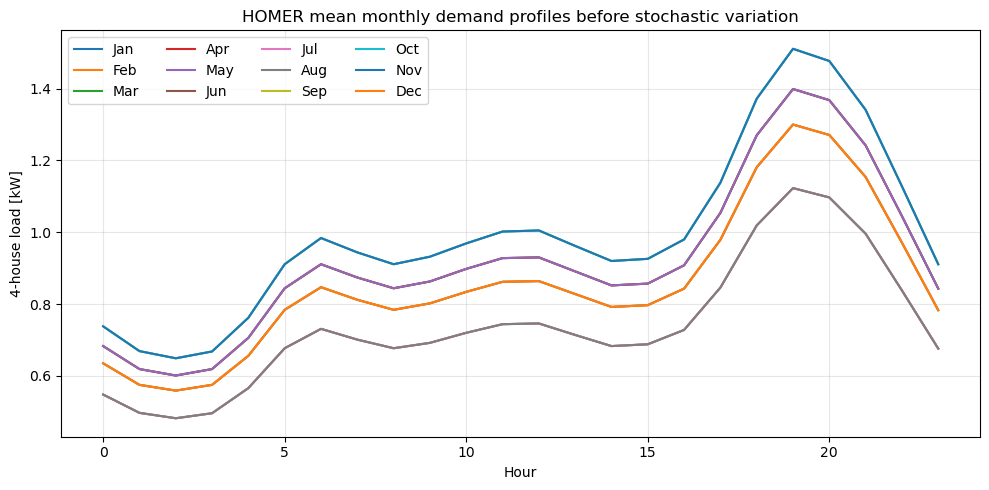

**Interpretation.** These are the mean monthly profiles from the HOMER input. The simulations use stochastic household realizations around these profiles.

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\figures\input_monthly_solar_resource.png


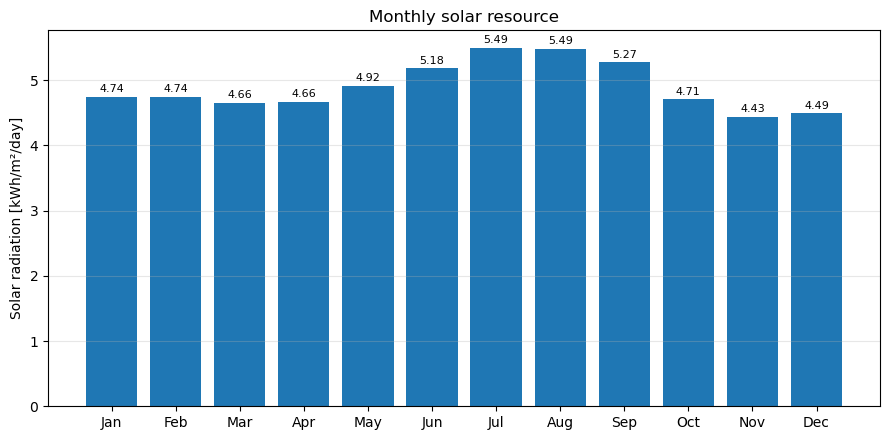

**Interpretation.** The monthly solar-resource pattern drives the reconstructed hourly PV series. The annual PV energy is calibrated to the accepted HOMER reference production.

Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\figures\stochastic_vs_deterministic_load_first_week.png


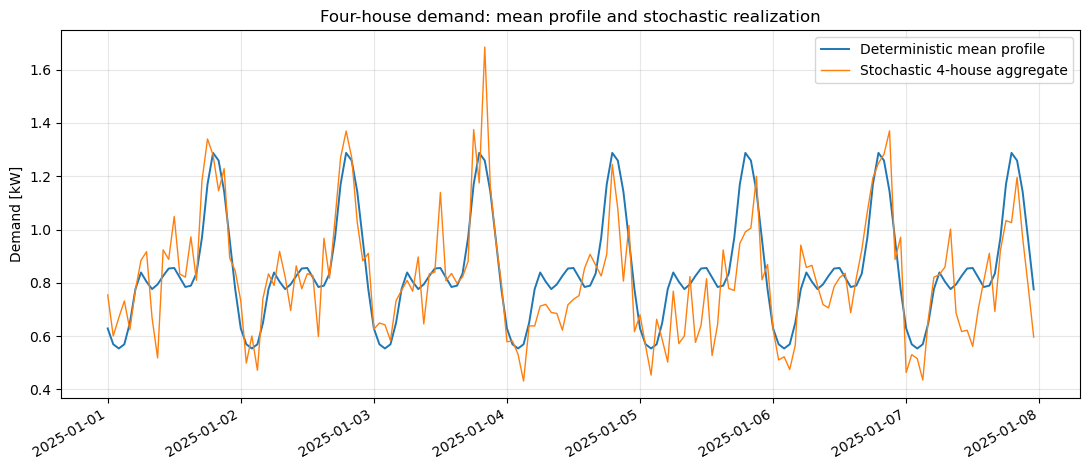

**Interpretation.** The stochastic series retains the underlying daily pattern while changing day-to-day magnitude and individual hourly values.

Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\figures\stochastic_individual_households_peak_day.png


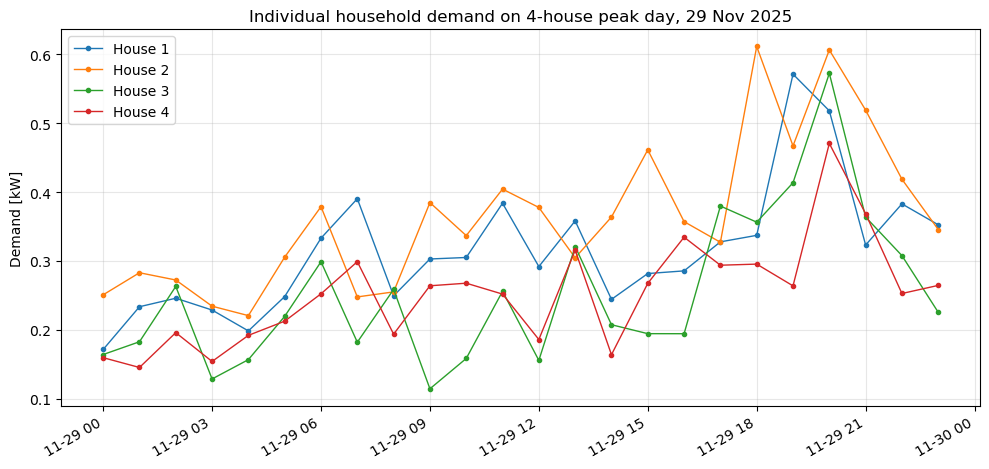

**Interpretation.** Each household uses an independent stochastic realization of the same underlying seasonal demand model.

Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\figures\pypsa_topology_4hh.png


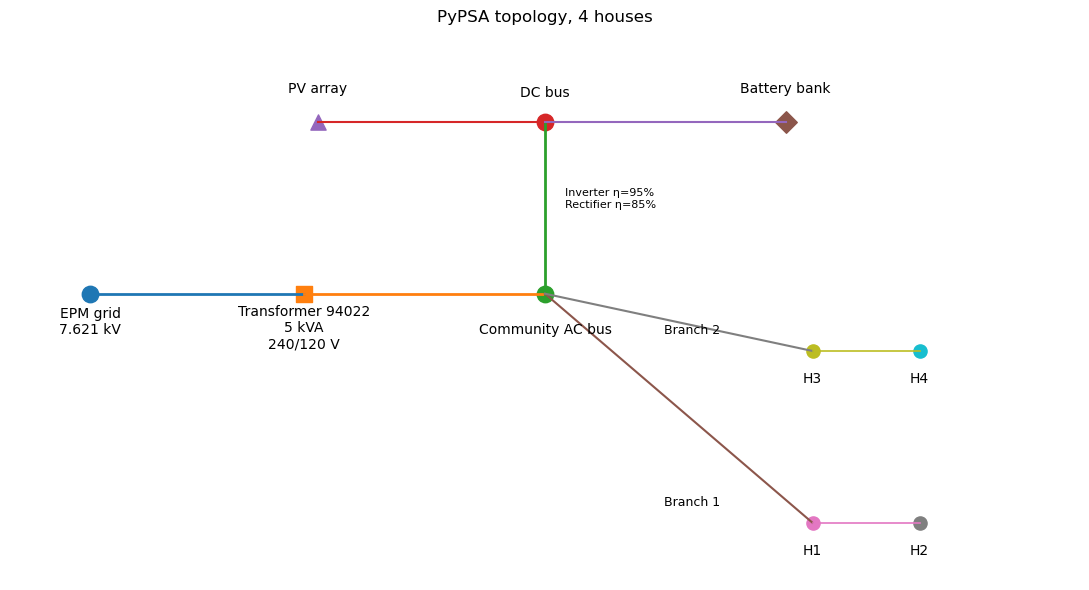

**Interpretation.** PyPSA represents the energy conversion chain and aggregate household demand. The two-house radial branch structure is shown for continuity with the later pandapower model.

### HOMER reference energy balance

,HOMER reference
AC primary load [kWh/yr],7592.00
PV production [kWh/yr],7326.30
PV penetration [%],96.50
Grid purchases [kWh/yr],4667.40
Grid sales [kWh/yr],4030.90
Net grid import [kWh/yr],636.50
Derived operational self-sufficiency [%],38.52
Derived net grid independence [%],91.62
HOMER renewable fraction [%],61.08
Battery energy in [kWh/yr],18.20


**Interpretation.** HOMER's 96.5% PV penetration means annual PV generation is 96.5% of annual load. The same simulation still purchased 4,667 kWh from the grid and sold 4,031 kWh back, so PV penetration, operational self-sufficiency and net grid independence are separate metrics.

Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\figures\homer_reference_energy_context.png


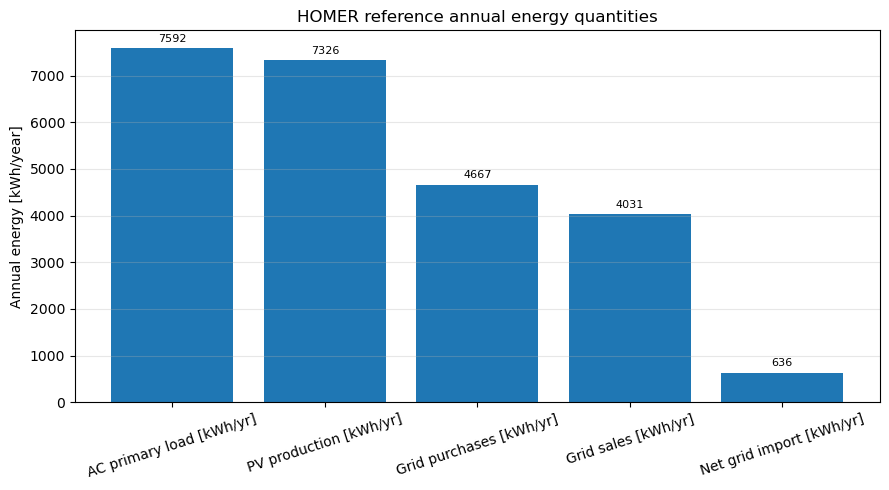

**Interpretation.** HOMER's 96.5% PV penetration is annual PV production divided by annual load. It does not mean that 96.5% of load was supplied locally at matching hours. The same simulation purchased 4,667 kWh from the grid and sold 4,031 kWh back.

C:\Users\Khuzaim\AppData\Local\Temp\ipykernel_19032\2460962056.py:6: FutureWarning:

The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.

Index(['GRID_MV', 'COMMUNITY_AC', 'DC_BUS'], dtype='object', name='name')
Index(['TRAFO_PCC'], dtype='object', name='name')
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 2/2 [00:00<00:00, 158.41it/s]
INFO:linopy.io: Writing time: 0.09s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 26280 primals, 70080 duals
Objective: 7.59e+04
Solver: highs
Runtime: 0.15s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the con

### Core benchmark cases, HOMER-calibrated PV

,case,houses,panel_count,bess_modules,pv_penetration_pct,self_sufficiency_pct,net_grid_independence_pct,net_grid_exchange_kwh,net_annual_exporter,grid_independent_hours_pct,grid_import_kwh,grid_export_kwh,battery_discharge_kwh,annual_grid_import_cost_usd,annual_grid_export_credit_usd,annual_net_grid_cost_usd,annualized_capex_usd,annualized_gross_cost_burden_usd,annualized_total_cost_usd
0,S0_GRID_ONLY,4,0,0,0.0,0.00,0.00,7592.00,False,0.00,7592.00,0.00,0.00,2201.68,0.00,2201.68,0.00,2201.68,2201.68
1,S1_PV_ONLY,4,12,0,96.5,42.86,91.68,632.02,False,38.78,4338.26,3706.24,0.00,1258.09,1019.22,238.88,563.02,1821.11,801.90
2,S2_REFERENCE_PV_BESS,4,12,4,96.5,84.98,89.46,800.33,False,85.02,1140.31,339.98,3366.26,330.69,93.50,237.19,936.75,1447.09,1353.60


**Interpretation.** These benchmark cases retain the HOMER-calibrated PV profile so the HOMER/PyPSA comparison remains apples-to-apples. The decision-facing household scaling and design analyses are run separately on the NASA GHI + Erbs physical profile.

Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\core_cases.csv
Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\figures\all_core_cases_self_sufficiency.png


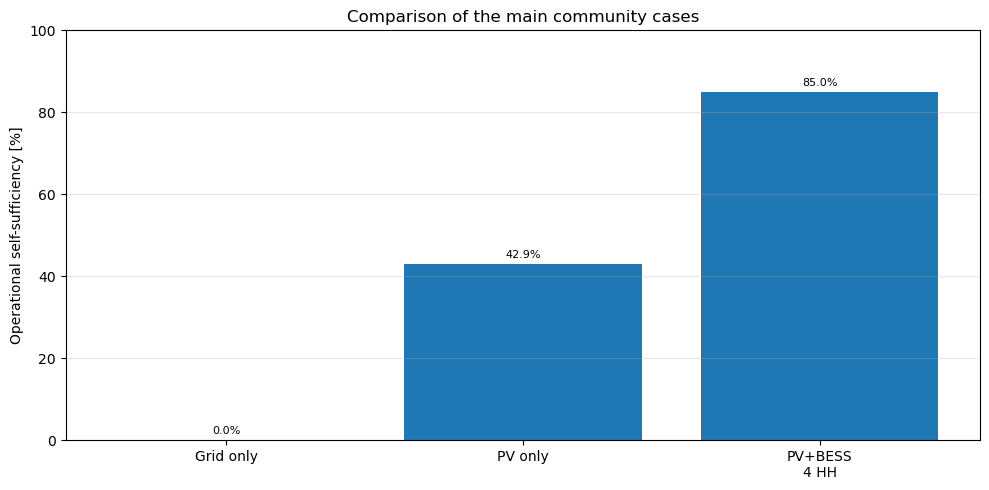

**Interpretation.** The benchmark chart compares the grid-only, PV-only and reference PV+BESS cases on the HOMER-calibrated PV basis. The decision-facing fixed-hardware household sweep is plotted separately on the NASA GHI + Erbs profile.

### HOMER and PyPSA metric alignment

,HOMER,PyPSA,Difference [percentage points]
PV penetration [%],96.50,96.50,-0.00
Operational self-sufficiency [%],38.52,84.98,46.46
Net grid independence [%],91.62,89.46,-2.16


**Interpretation.** Read each row horizontally. HOMER PV penetration is compared only with PyPSA PV penetration; HOMER gross-import self-sufficiency is compared only with PyPSA operational self-sufficiency. This is why 96.5% and approximately 84–85% are not contradictory values.

### HOMER and PyPSA reference energy flows

,HOMER,PyPSA
Load [kWh/yr],7592.00,7592.00
PV DC generation [kWh/yr],7326.30,7326.30
Grid imports [kWh/yr],4667.40,1140.31
Grid exports [kWh/yr],4030.90,339.98
Battery energy in [kWh/yr],18.20,3543.43
Battery energy out [kWh/yr],17.30,3366.26
Battery throughput [kWh/yr],17.74,3454.84


**Interpretation.** Both models use the same annual PV-energy reference, but PyPSA actively shifts PV through the battery to reduce gross grid imports. The battery-energy and grid-flow differences explain the much higher operational self-sufficiency of the PyPSA community strategy. Battery throughput is calculated on a HOMER-comparable basis.

Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\figures\homer_pypsa_metric_alignment.png


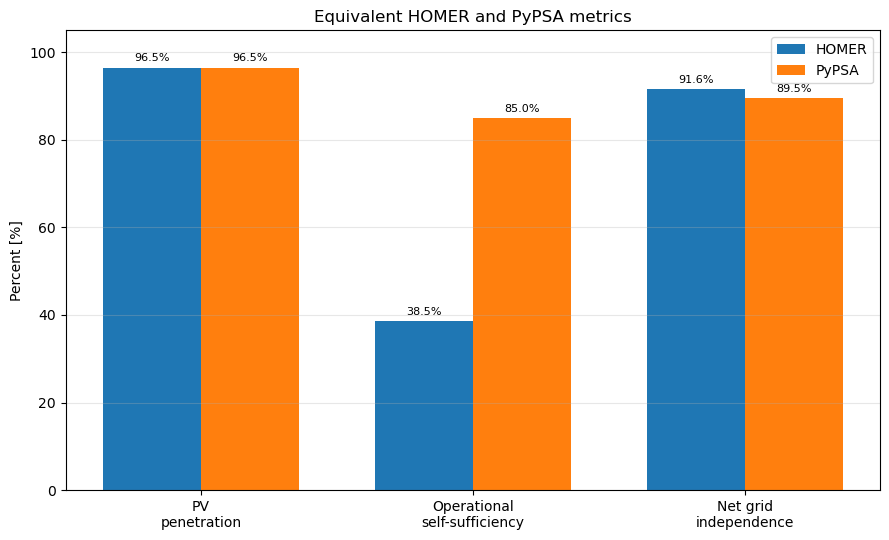

**Interpretation.** Compare bars only within the same metric. PV penetration describes annual energy availability, while operational self-sufficiency describes how much demand is served without gross grid imports. The approximately 96.5% PV-penetration value is therefore not the quantity being compared with the approximately 84–85% PyPSA self-sufficiency value.

Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\figures\gross_vs_net_grid_independence.png


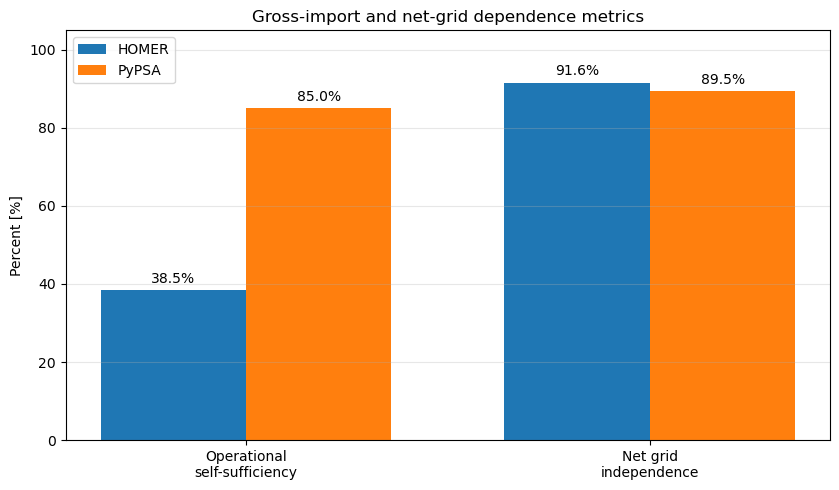

**Interpretation.** Operational self-sufficiency is based on gross grid imports and therefore measures physical dependence on the grid. Net grid independence subtracts exports from imports and shows how closely annual local generation balances annual consumption.

Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\figures\homer_pypsa_reference_energy_flows.png


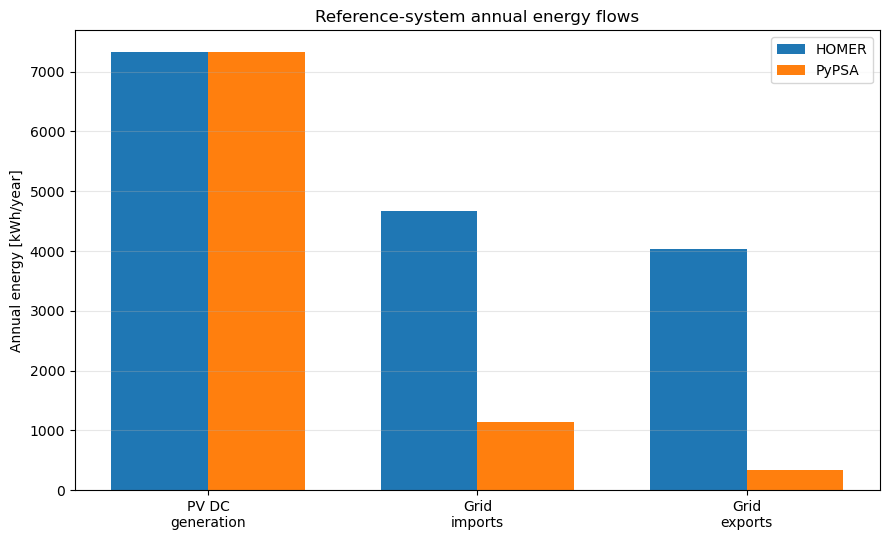

**Interpretation.** Annual PV energy is calibrated to the same reference value. The main difference is dispatch: PyPSA shifts far more local PV through storage, which reduces gross grid imports and exports.

Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\figures\homer_pypsa_battery_cycling.png


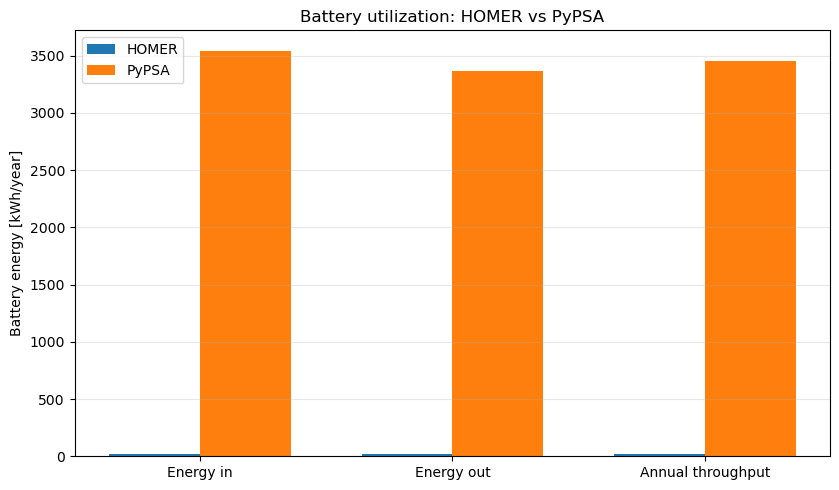

**Interpretation.** HOMER barely cycles the battery, whereas the PyPSA community strategy actively shifts daytime PV into later demand. Throughput uses the same comparison convention on both sides: approximately the average of annual energy charged and discharged.

**Interpretation.** HOMER is retained as the benchmark reference. From this point onward, the fixed-hardware household scaling, design sweeps, self-sufficiency search, outage studies and solved Monte Carlo use the corrected NASA GHI + Erbs physical PV profile.

C:\Users\Khuzaim\AppData\Local\Temp\ipykernel_19032\2460962056.py:6: FutureWarning:

The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.

Index(['GRID_MV', 'COMMUNITY_AC', 'DC_BUS'], dtype='object', name='name')
Index(['TRAFO_PCC', 'INVERTER'], dtype='object', name='name')
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 5/5 [00:00<00:00, 206.60it/s]
INFO:linopy.io: Writing time: 0.18s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 70080 primals, 175200 duals
Objective: 1.32e+04
Solver: highs
Runtime: 1.78s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-pric

### Fixed-hardware household sweep, NASA GHI + Erbs

,houses,load_kwh,pv_penetration_pct,self_sufficiency_pct,net_grid_independence_pct,net_grid_exchange_kwh,grid_independent_hours_pct,grid_import_kwh,grid_export_kwh,battery_discharge_kwh,peak_import_kw,peak_export_kw
0,4,7592.0,92.91,82.87,86.02,1061.63,82.04,1300.16,238.52,3418.75,2.17,2.53
1,5,9490.0,74.33,68.96,69.01,2940.54,66.45,2946.06,5.51,3036.94,2.51,1.59
2,6,11388.0,61.94,57.76,57.76,4810.39,53.21,4810.39,0.00,2473.93,2.94,0.00
3,7,13286.0,53.09,49.70,49.70,6682.87,43.15,6682.87,0.00,1963.52,3.45,0.00
4,8,15184.0,46.46,43.64,43.64,8558.32,34.87,8558.32,0.00,1512.56,4.18,0.00


**Interpretation.** The same 5.22 kWp PV array, four batteries and 5 kW inverter serve progressively more houses using the physical NASA GHI + Erbs resource profile. This is the decision-facing scaling study that supports the downstream grid analysis.

Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\fixed_hardware_house_sweep.csv
Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\figures\house_sweep_energy_share.png


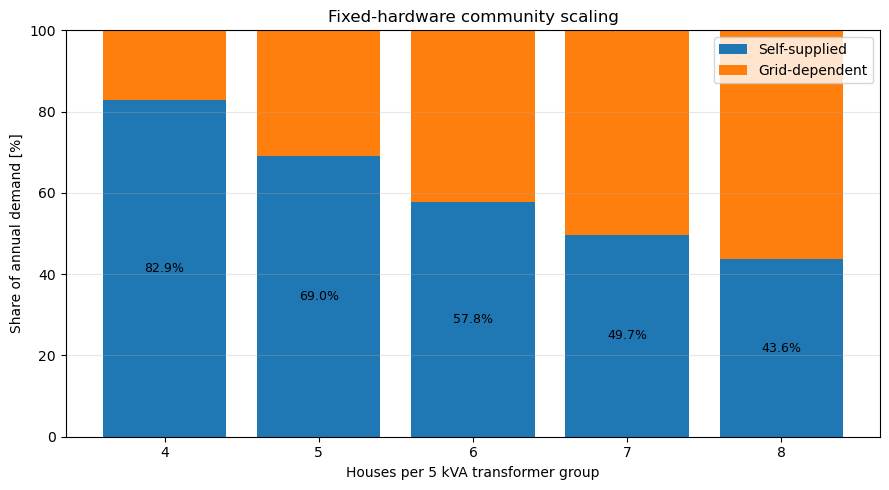

**Interpretation.** The same PV, battery bank and inverter are shared by progressively more houses. The green portion is the annual demand served without grid imports; the remaining portion is residual grid dependence.

C:\Users\Khuzaim\AppData\Local\Temp\ipykernel_19032\2460962056.py:6: FutureWarning:

The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.

Index(['GRID_MV', 'COMMUNITY_AC', 'DC_BUS'], dtype='object', name='name')
Index(['TRAFO_PCC', 'INVERTER'], dtype='object', name='name')
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 5/5 [00:00<00:00, 207.17it/s]
INFO:linopy.io: Writing time: 0.17s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 70080 primals, 175200 duals
Objective: 5.37e+04
Solver: highs
Runtime: 3.36s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-pric

### PV panel-count sweep, NASA GHI + Erbs

,panel_count,pv_kwp,pv_penetration_pct,self_sufficiency_pct,net_grid_independence_pct,net_grid_exchange_kwh,grid_independent_hours_pct,grid_import_kwh,grid_export_kwh,battery_discharge_kwh,capex_usd,annual_grid_import_cost_usd,capex_plus_grid_import_cost_usd,annual_grid_export_credit_usd,annual_net_grid_cost_usd,annualized_capex_usd,annualized_total_cost_usd
0,4,1.74,30.97,29.33,29.33,5365.53,12.51,5365.53,0.00,145.89,9400.08,1556.00,10956.09,0.00,1556.00,735.34,2299.13
1,6,2.61,46.46,43.62,43.62,4280.03,35.02,4280.03,0.00,773.62,10043.76,1241.21,11284.97,0.00,1241.21,785.69,2068.19
2,8,3.48,61.94,57.75,57.75,3207.43,53.62,3207.43,0.00,1659.28,10687.44,930.15,11617.59,0.00,930.15,836.04,1854.75
3,10,4.35,77.43,71.65,71.83,2138.72,69.79,2152.69,13.97,2622.83,11331.11,624.28,11955.39,3.84,620.44,886.40,1646.81
4,12,5.22,92.91,82.87,86.02,1061.63,82.04,1300.16,238.52,3418.75,11974.79,377.05,12351.84,65.59,311.45,936.75,1430.65


**Interpretation.** The four-house load and four-battery bank remain fixed. The corrected NASA GHI + Erbs physical PV profile is used for this decision-facing sweep. The practical PV design space is capped at 12 panels.

Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\pv_panel_sweep.csv
Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\figures\pv_sweep_capex_plus_grid_cost_vs_self_sufficiency.png


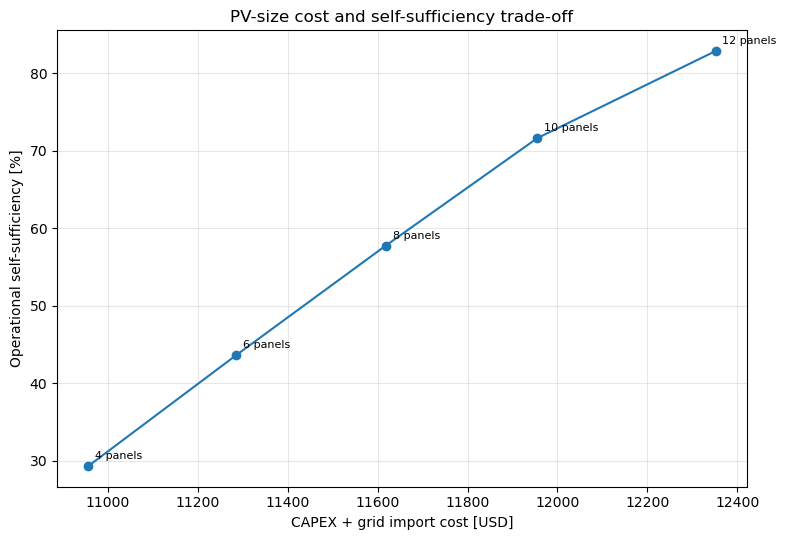

**Interpretation.** The x-axis is the installed CAPEX plus one year of gross grid-import cost. This keeps the continuing cost of grid dependence visible when comparing PV sizes.

C:\Users\Khuzaim\AppData\Local\Temp\ipykernel_19032\2460962056.py:6: FutureWarning:

The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.

Index(['GRID_MV', 'COMMUNITY_AC', 'DC_BUS'], dtype='object', name='name')
Index(['TRAFO_PCC', 'INVERTER'], dtype='object', name='name')
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 2/2 [00:00<00:00, 136.40it/s]
INFO:linopy.io: Writing time: 0.09s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 43800 primals, 113880 duals
Objective: 4.55e+04
Solver: highs
Runtime: 0.37s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-pric

### Battery-module sweep, NASA GHI + Erbs

,bess_modules,self_sufficiency_pct,net_grid_independence_pct,grid_independent_hours_pct,grid_import_kwh,battery_charge_kwh,battery_discharge_kwh,battery_throughput_kwh,capex_usd,annual_grid_import_cost_usd,capex_plus_grid_import_cost_usd,annual_grid_export_credit_usd,annual_net_grid_cost_usd,annualized_capex_usd,annualized_total_cost_usd
0,0,40.10,88.27,35.37,4547.97,0.00,0.00,0.00,7197.29,1318.91,8516.21,1005.75,313.16,563.02,876.18
1,1,59.20,87.26,54.65,3097.57,1607.10,1526.75,1566.92,8391.67,898.29,9289.96,585.90,312.40,656.45,1050.33
2,2,75.53,86.40,72.72,1857.84,2980.76,2831.72,2906.24,9586.04,538.77,10124.81,227.03,311.75,749.88,1212.75
3,3,82.09,86.06,80.84,1360.08,3532.29,3355.67,3443.98,10780.42,394.42,11174.84,82.94,311.48,843.32,1333.89
4,4,82.87,86.02,82.04,1300.16,3598.69,3418.75,3508.72,11974.79,377.05,12351.84,65.59,311.45,936.75,1430.65


**Interpretation.** PV and demand remain fixed and the corrected NASA GHI + Erbs physical PV profile is used. Storage is charged from local PV and used before the grid, so the change in self-sufficiency measures the direct value of each additional battery module.

Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\bess_module_sweep.csv
Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\figures\bess_sweep_capex_plus_grid_cost_vs_self_sufficiency.png


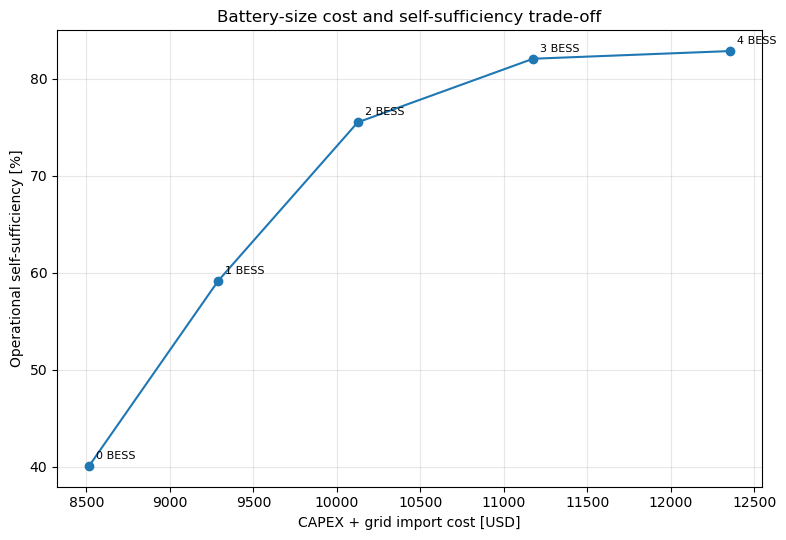

**Interpretation.** The x-axis is the installed CAPEX plus one year of gross grid-import cost. Additional storage is therefore assessed together with the grid purchases it avoids.

C:\Users\Khuzaim\AppData\Local\Temp\ipykernel_19032\2460962056.py:6: FutureWarning:

The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.

Index(['GRID_MV', 'COMMUNITY_AC', 'DC_BUS'], dtype='object', name='name')
Index(['TRAFO_PCC', 'INVERTER'], dtype='object', name='name')
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 2/2 [00:00<00:00, 157.69it/s]
INFO:linopy.io: Writing time: 0.1s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 43800 primals, 113880 duals
Objective: 5.50e+04
Solver: highs
Runtime: 0.26s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-price

### Unique self-sufficiency design steps, NASA GHI + Erbs

,configuration,lowest_target_pct,highest_target_pct,self_sufficiency_pct,net_grid_independence_pct,grid_import_kwh,grid_export_kwh,annual_grid_import_cost_usd,annual_grid_export_credit_usd,capex_usd,capex_plus_grid_import_cost_usd,delta_capex_plus_grid_import_cost_usd,annualized_gross_cost_burden_usd,delta_capex_from_previous_usd,grid_import_cost_saving_from_previous_usd_per_year,delta_self_sufficiency_pp,usd_capex_per_added_self_sufficiency_pp,delta_capex_vs_reference_usd
0,8P / 1B,50.0,50.0,52.99,58.00,3569.33,380.95,1035.11,104.76,7104.31,8139.42,NaN,1659.08,NaN,NaN,NaN,NaN,-4870.48
1,10P / 2B,60.0,60.0,68.89,71.97,2361.64,233.92,684.88,64.33,8942.37,9627.24,1487.82,1512.65,1838.05,350.23,15.91,115.55,-3032.42
2,12P / 2B,70.0,70.0,75.53,86.40,1857.84,825.56,538.77,227.03,9586.04,10124.81,497.57,1439.78,643.68,146.10,6.64,97.00,-2388.75
3,12P / 3B,80.0,80.0,82.09,86.06,1360.08,301.60,394.42,82.94,10780.42,11174.84,1050.03,1416.83,1194.37,144.35,6.56,182.17,-1194.37


**Interpretation.** Repeated targets that select exactly the same hardware are removed. The design search uses the corrected NASA GHI + Erbs physical PV profile. Each retained design minimizes the simple screening sum CAPEX + one year of gross grid-import cost while meeting its self-sufficiency target. Export credit is reported separately and is not subtracted from this screening cost.

Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\self_sufficiency_candidates.csv
Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\self_sufficiency_design_steps.csv


### Self-sufficiency targets not reached by the tested design space

,target_self_sufficiency_pct,feasible
4,90.0,False
5,95.0,False
6,100.0,False


**Interpretation.** These targets are not presented as design results because no tested PV/BESS combination reaches them.

Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\self_sufficiency_infeasible_targets.csv
Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\figures\self_sufficiency_pareto_frontier.png


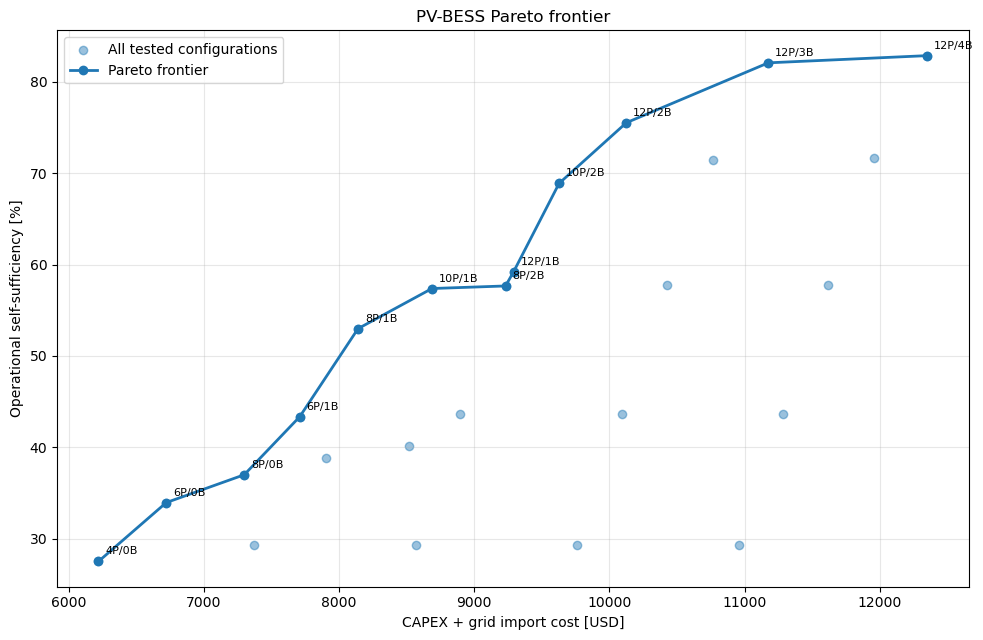

**Interpretation.** Every tested practical PV/BESS configuration up to 12 panels is shown. The line connects only non-dominated configurations for the screening metric CAPEX + annual gross grid-import cost versus operational self-sufficiency.

Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\figures\self_sufficiency_vs_grid_import_cost.png


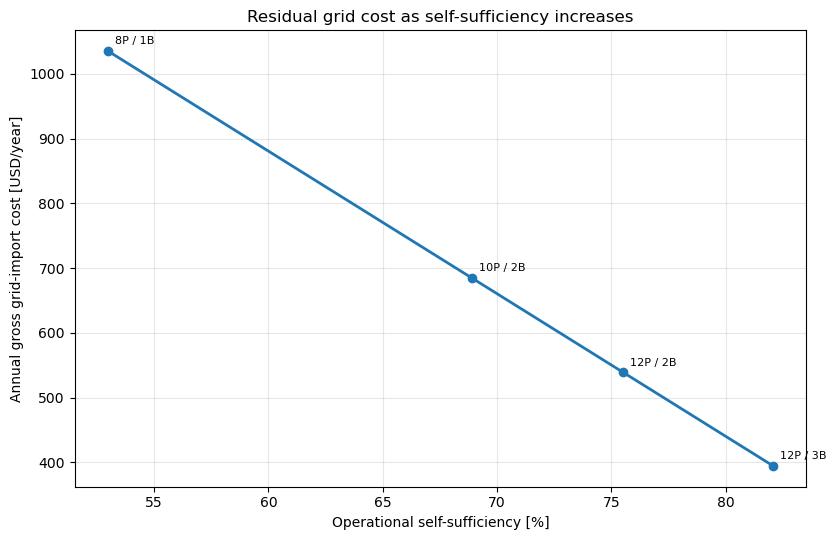

**Interpretation.** Higher self-sufficiency directly reduces the annual cost of imported electricity. Export revenue is intentionally shown separately in tables rather than netted into this plot, because the study objective is reduced grid dependence.

c:\Users\Khuzaim\miniforge3\Lib\site-packages\dateutil\parser\_parser.py:1207: UnknownTimezoneWarning:

tzname B identified but not understood.  Pass `tzinfos` argument in order to correctly return a timezone-aware datetime.  In a future version, this will raise an exception.

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\figures\self_sufficiency_incremental_combined_cost.png


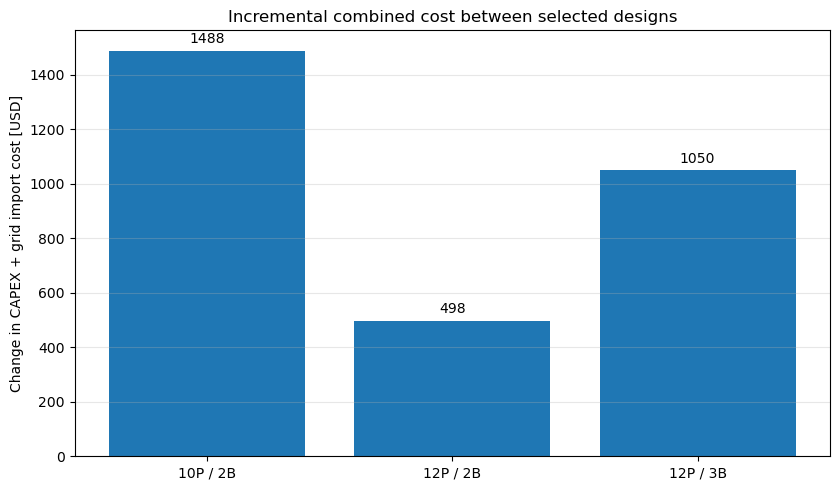

**Interpretation.** Each bar is the change in the simple screening sum of installed CAPEX plus one year of gross grid-import cost when moving to the next selected design.

C:\Users\Khuzaim\AppData\Local\Temp\ipykernel_19032\2460962056.py:6: FutureWarning:

The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.

Index(['GRID_MV', 'COMMUNITY_AC', 'DC_BUS'], dtype='object', name='name')
Index(['TRAFO_PCC', 'INVERTER'], dtype='object', name='name')
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.09s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 108 primals, 264 duals
Objective: 6.60e-01
Solver: highs
Runtime: 0.01s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Link-fix-p-lower, Link-fix-p-upper, StorageUnit-f

### Reference outage case, NASA GHI + Erbs

,outage_duration_h,outage_start_soc_pct,outage_energy_demand_kwh,outage_energy_served_kwh,outage_energy_not_served_kwh,outage_load_served_pct,minimum_actual_soc_pct,ending_actual_soc_pct
0,12,80.0,12.06,12.06,0.0,100.0,12.22,12.22


**Interpretation.** The grid is unavailable. The corrected NASA GHI + Erbs PV profile and stored local energy supply the community until their available energy is insufficient. This fixed-SOC run is a demonstration; the distributional study below is the decision-facing resilience result.

### Outage dispatch time series

,load_kw,pv_dc_kw,inverter_ac_kw,battery_dc_kw,load_shed_kw,served_load_kw,battery_actual_soc_pct
timestamp,,,,,,,
2025-09-15 18:00:00,1.285,-0.0,1.285,1.353,-0.0,1.285,72.781
2025-09-15 19:00:00,1.326,-0.0,1.326,1.396,-0.0,1.326,65.331
2025-09-15 20:00:00,1.437,-0.0,1.437,1.512,-0.0,1.437,57.259
2025-09-15 21:00:00,1.474,-0.0,1.474,1.552,-0.0,1.474,48.978
2025-09-15 22:00:00,1.059,-0.0,1.059,1.114,-0.0,1.059,43.030
2025-09-15 23:00:00,1.120,-0.0,1.120,1.179,-0.0,1.120,36.739
2025-09-16 00:00:00,0.682,-0.0,0.682,0.718,-0.0,0.682,32.908
2025-09-16 01:00:00,0.675,-0.0,0.675,0.710,-0.0,0.675,29.116
2025-09-16 02:00:00,0.561,-0.0,0.561,0.591,-0.0,0.561,25.962


**Interpretation.** Positive battery power denotes discharge. The hourly table shows how local PV and stored energy maintain supply through the outage.

Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\figures\outage_dispatch.png


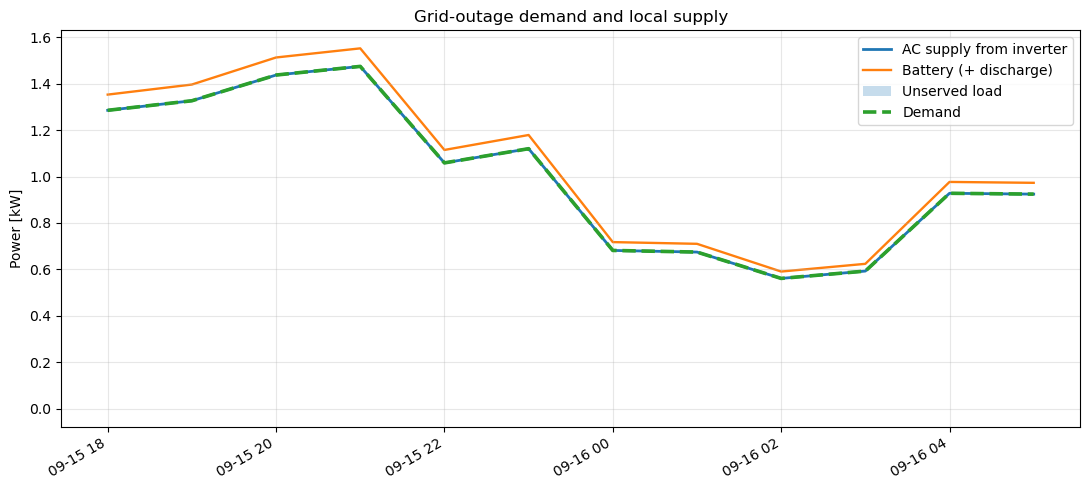

**Interpretation.** Demand is the dashed line and is drawn on top so it remains visible. When the inverter supplies the full load, the AC-supply curve lies directly underneath the demand curve. Any gap between demand and AC supply appears as unserved load.

Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\figures\outage_battery_soc.png


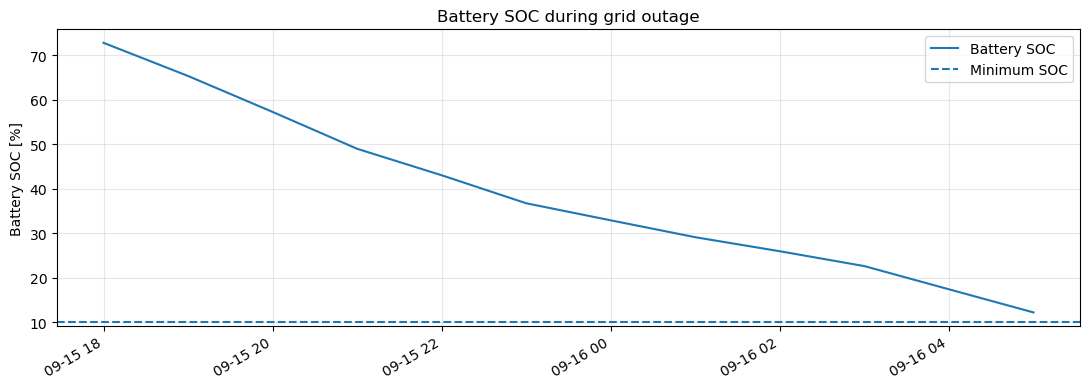

**Interpretation.** The SOC trajectory shows how much backup energy remains as the outage progresses.

C:\Users\Khuzaim\AppData\Local\Temp\ipykernel_19032\2460962056.py:6: FutureWarning:

The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.

Index(['GRID_MV', 'COMMUNITY_AC', 'DC_BUS'], dtype='object', name='name')
Index(['TRAFO_PCC', 'INVERTER'], dtype='object', name='name')
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.08s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 36 primals, 88 duals
Objective: 3.02e-01
Solver: highs
Runtime: 0.00s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Link-fix-p-lower, Link-fix-p-upper, StorageUnit-fix

### Outage-duration sweep, NASA GHI + Erbs

,outage_duration_h,outage_energy_demand_kwh,outage_energy_served_kwh,outage_energy_not_served_kwh,outage_load_served_pct,ending_actual_soc_pct
0,4,5.52,5.52,0.00,100.00,48.98
1,8,9.06,9.06,0.00,100.00,29.12
2,12,12.06,12.06,0.00,100.00,12.22
3,24,22.88,22.41,0.47,97.94,10.00


**Interpretation.** The same system, corrected NASA GHI + Erbs profile and fixed demonstration starting SOC are tested against longer outages. The first case below 100% served demand marks the duration at which local PV and storage are no longer sufficient.

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\outage_duration_sweep.csv
Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\figures\outage_duration_load_served.png


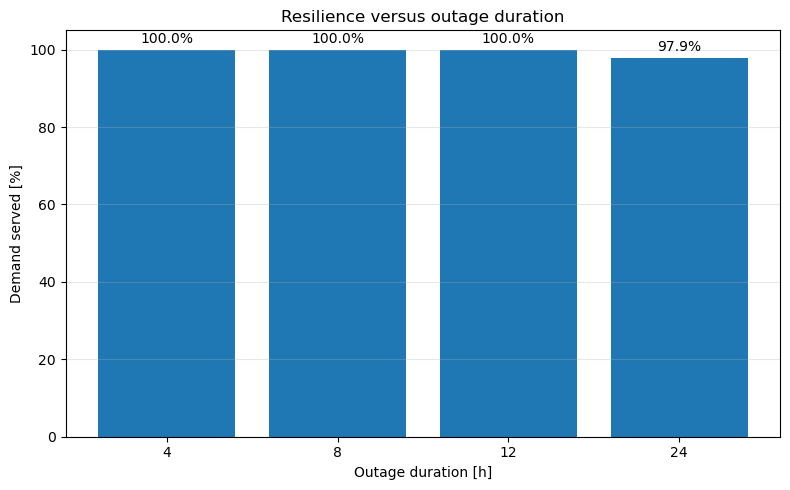

**Interpretation.** The first duration below 100% marks the point at which the available PV and battery energy can no longer cover the entire outage.

C:\Users\Khuzaim\AppData\Local\Temp\ipykernel_19032\2460962056.py:6: FutureWarning:

The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.

Index(['GRID_MV', 'COMMUNITY_AC', 'DC_BUS'], dtype='object', name='name')
Index(['TRAFO_PCC', 'INVERTER'], dtype='object', name='name')
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 5/5 [00:00<00:00, 176.88it/s]
INFO:linopy.io: Writing time: 0.17s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 70080 primals, 175200 duals
Objective: 1.32e+04
Solver: highs
Runtime: 1.89s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-pric

### Shared versus individual architecture

,architecture,panel_count,bess_modules,converter_kw,self_sufficiency_pct,grid_import_kwh,grid_export_kwh,capex_usd
0,Shared,12,4,5.0,82.87,1300.16,238.52,11974.79
1,Individual,12,4,5.0,82.28,1345.30,284.35,11974.79


**Interpretation.** Both options use the same total PV, battery energy and converter capacity and both prioritize local energy before grid imports. The household time series are synthetic stochastic profiles based on the HOMER variability settings, not measured annual household profiles.

Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\individual_vs_shared.csv
Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\figures\shared_vs_individual_self_sufficiency.png


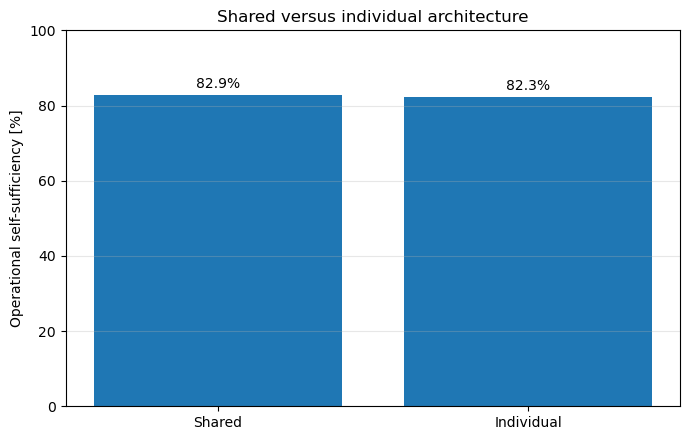

**Interpretation.** Both architectures use the same total PV, battery energy and converter capacity. Because separate measured household profiles are unavailable, this is a hardware-normalized architecture comparison.

Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\model_run_manifest.csv


### HOMER-benchmark reference diagnostics

,case,check,value,status,note
0,S2_REFERENCE_PV_BESS_HOMER_BENCHMARK,PV profile source,HOMER-calibrated benchmark,INFO,time-series input used for this solved case
1,S2_REFERENCE_PV_BESS_HOMER_BENCHMARK,maximum nodal balance residual,0.0,PASS,kW; sum of solved bus active-power residuals
2,S2_REFERENCE_PV_BESS_HOMER_BENCHMARK,annual load-energy normalization error,0.0,PASS,kWh
3,S2_REFERENCE_PV_BESS_HOMER_BENCHMARK,reference PV annual-energy difference,-0.0,PASS,kWh; may differ in constrained or alternative-...
4,S2_REFERENCE_PV_BESS_HOMER_BENCHMARK,simultaneous battery charge/discharge hours,0,PASS,tolerance 1e-06 kW
5,S2_REFERENCE_PV_BESS_HOMER_BENCHMARK,minimum usable battery SOC,-0.0,PASS,kWh above the modelled minimum SOC
6,S2_REFERENCE_PV_BESS_HOMER_BENCHMARK,maximum usable battery SOC,17.3,PASS,kWh; usable capacity 17.300 kWh
7,S2_REFERENCE_PV_BESS_HOMER_BENCHMARK,reconstructed annual battery charge,3543.429254,INFO,kWh
8,S2_REFERENCE_PV_BESS_HOMER_BENCHMARK,reconstructed annual battery discharge,3366.257791,INFO,kWh
9,S2_REFERENCE_PV_BESS_HOMER_BENCHMARK,clipped stochastic household-hours,0.09589,INFO,% of household-hours; clipping prevents negati...


**Interpretation.** These checks retain numerical traceability for the original HOMER-calibrated benchmark case.

...

C:\Users\Khuzaim\AppData\Local\Temp\ipykernel_19032\2460962056.py:6: FutureWarning:

The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.

Index(['GRID_MV', 'COMMUNITY_AC', 'DC_BUS'], dtype='object', name='name')
Index(['TRAFO_PCC', 'INVERTER'], dtype='object', name='name')
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.08s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 36 primals, 88 duals
Objective: 1.28e-01
Solver: highs
Runtime: 0.00s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Link-fix-p-lower, Link-fix-p-upper, StorageUnit-fix

### Distributional outage resilience, NASA GHI + Erbs

,outage_duration_h,sample_count,fully_served_share_pct,median_load_served_pct,p05_load_served_pct,minimum_load_served_pct,median_start_soc_pct,median_unserved_energy_kwh,p95_unserved_energy_kwh,maximum_unserved_energy_kwh,pv_profile_source
0,4,96,96.875,100.0,100.000,59.352,52.751,0.0,0.000,1.176,NASA POWER GHI + Erbs at hourly midpoint; sour...
1,8,96,90.625,100.0,83.615,66.155,52.751,0.0,1.130,2.496,NASA POWER GHI + Erbs at hourly midpoint; sour...
2,12,96,81.250,100.0,80.755,55.352,52.751,0.0,1.990,5.050,NASA POWER GHI + Erbs at hourly midpoint; sour...
3,24,96,59.375,100.0,77.026,71.109,52.751,0.0,5.844,6.176,NASA POWER GHI + Erbs at hourly midpoint; sour...


**Interpretation.** Each outage starts from the actual battery SOC immediately before that timestamp in the normal annual NASA GHI + Erbs dispatch. Starts use the explicit month × hour-of-day grid. Percentage load served may be non-monotonic with duration because a longer window can include the next solar-production period; absolute unserved energy is therefore reported alongside it.

Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\outage_distribution.csv
Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\outage_distribution_summary.csv
Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\pandapower_handoff_S2_REFERENCE_PV_BESS_HOMER_SHAPE.csv
Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\pandapower_metadata_S2_REFERENCE_PV_BESS_HOMER_SHAPE.csv
Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\lv_branches_S2_REFERENCE_PV_BESS_HOMER_SHAPE.csv
Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\pandapower_handoff_S2_REFERENCE_PV_BESS_NASA_GHI_ERBS.csv
Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\pandapower_metadata_S2_REFERENCE_PV_BESS_NASA_GHI_ERBS.csv
Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\lv_branches_S2_REFERENCE_PV_BESS_NASA_GHI_ERBS.csv
Saved: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\pandapower_handoff_S2_REFERENCE_PV_BESS.csv
Saved: d:\0. UoL\SEEDExchange\

In [38]:
# ============================================================
# 17. RUN ENABLED ANALYSES
# ============================================================

plot_input_profiles()
plot_stochastic_load_profiles()
plot_pypsa_topology(4)

# HOMER reference context
homer_context = homer_reference_table()

show_table(
    homer_context.round(2),
    "HOMER reference energy balance",
    "HOMER's 96.5% PV penetration means annual PV generation is 96.5% of annual load. "
    "The same simulation still purchased 4,667 kWh from the grid and sold 4,031 kWh back, "
    "so PV penetration, operational self-sufficiency and net grid independence are separate metrics."
)

plot_homer_reference_energy(
    homer_context
)

homer_context.to_csv(
    RESULTS_DIR / "homer_reference_context.csv"
)

# Core community cases
core_results = None
core_networks = {}
reference_kpi = None

if RUN_CORE_CASES:
    core_results, core_networks = run_core_cases()

    core_columns = [
        "case",
        "houses",
        "panel_count",
        "bess_modules",
        "pv_penetration_pct",
        "self_sufficiency_pct",
        "net_grid_independence_pct",
        "net_grid_exchange_kwh",
        "net_annual_exporter",
        "grid_independent_hours_pct",
        "grid_import_kwh",
        "grid_export_kwh",
        "battery_discharge_kwh",
        "annual_grid_import_cost_usd",
        "annual_grid_export_credit_usd",
        "annual_net_grid_cost_usd",
        "annualized_capex_usd",
        "annualized_gross_cost_burden_usd",
        "annualized_total_cost_usd",
    ]

    show_table(
        core_results[
            core_columns
        ].round(2),
        "Core benchmark cases, HOMER-calibrated PV",
        "These benchmark cases retain the HOMER-calibrated PV profile so the HOMER/PyPSA comparison remains apples-to-apples. "
        "The decision-facing household scaling and design analyses are run separately on the NASA GHI + Erbs physical profile."
    )

    save_results(
        core_results,
        "core_cases.csv"
    )

    plot_all_core_cases(
        core_results
    )

    reference_rows = (
        core_results[
            core_results["case"]
            == "S2_REFERENCE_PV_BESS"
        ]
    )

    if not reference_rows.empty:
        reference_kpi = (
            reference_rows
            .iloc[0]
            .to_dict()
        )

        metric_alignment = (
            build_metric_alignment_table(
                homer_context,
                reference_kpi
            )
        )

        energy_alignment = (
            build_energy_flow_alignment_table(
                homer_context,
                reference_kpi
            )
        )

        show_table(
            metric_alignment.round(2),
            "HOMER and PyPSA metric alignment",
            "Read each row horizontally. HOMER PV penetration is compared only with PyPSA PV penetration; "
            "HOMER gross-import self-sufficiency is compared only with PyPSA operational self-sufficiency. "
            "This is why 96.5% and approximately 84–85% are not contradictory values."
        )

        show_table(
            energy_alignment.round(2),
            "HOMER and PyPSA reference energy flows",
            "Both models use the same annual PV-energy reference, but PyPSA actively shifts PV through the battery to reduce gross grid imports. "
            "The battery-energy and grid-flow differences explain the much higher operational self-sufficiency of the PyPSA community strategy. Battery throughput is calculated on a HOMER-comparable basis."
        )

        metric_alignment.to_csv(
            RESULTS_DIR
            / "homer_pypsa_metric_alignment.csv"
        )

        energy_alignment.to_csv(
            RESULTS_DIR
            / "homer_pypsa_reference_energy_flows.csv"
        )

        plot_metric_alignment(
            metric_alignment
        )

        plot_grid_independence_comparison(
            metric_alignment
        )

        plot_reference_energy_flows(
            energy_alignment
        )

        plot_battery_cycling_comparison(
            energy_alignment
        )

# Physical decision/reporting time series
# ---------------------------------------
# HOMER remains the benchmark in the core comparison above. The
# decision-facing sweeps, design search, resilience study and solved
# Monte Carlo use the corrected NASA POWER GHI + Erbs PV profile.
(
    decision_pv_profile,
    decision_pv_path,
    decision_pv_diagnostics,
) = load_nasa_pv_profile_for_pypsa(
    TS.index
)

if decision_pv_profile is None:
    raise FileNotFoundError(
        "NASA GHI + Erbs PV profile is required for the decision-facing "
        "v18 analyses. Provide the raw 2025 NASA POWER hourly file or a "
        "corrected preprocessed NASA_GHI_ERBS_MIDPOINT export."
    )

decision_ts = TS.copy()
decision_ts.attrs = TS.attrs.copy()
decision_ts[
    PV_PROFILE_COLUMN
] = decision_pv_profile

decision_ts.attrs[
    "pv_profile_source"
] = (
    "NASA POWER GHI + Erbs at hourly midpoint; "
    f"source={decision_pv_path.name}"
)

decision_ts.attrs[
    "pv_profile_diagnostics"
] = decision_pv_diagnostics

explain(
    "HOMER is retained as the benchmark reference. From this point onward, "
    "the fixed-hardware household scaling, design sweeps, self-sufficiency search, "
    "outage studies and solved Monte Carlo use the corrected NASA GHI + Erbs physical PV profile."
)

# Fixed-hardware household scaling on the physical PV resource.
house_results, house_networks = (
    run_fixed_hardware_house_sweep(
        ts=decision_ts
    )
)

show_table(
    house_results[
        [
            "houses",
            "load_kwh",
            "pv_penetration_pct",
            "self_sufficiency_pct",
            "net_grid_independence_pct",
            "net_grid_exchange_kwh",
            "grid_independent_hours_pct",
            "grid_import_kwh",
            "grid_export_kwh",
            "battery_discharge_kwh",
            "peak_import_kw",
            "peak_export_kw",
        ]
    ].round(2),
    "Fixed-hardware household sweep, NASA GHI + Erbs",
    "The same 5.22 kWp PV array, four batteries and 5 kW inverter serve progressively more houses using the physical NASA GHI + Erbs resource profile. "
    "This is the decision-facing scaling study that supports the downstream grid analysis."
)

save_results(
    house_results,
    "fixed_hardware_house_sweep.csv",
)

plot_house_sweep(
    house_results
)

# PV-size study
if RUN_PV_SWEEP:
    pv_sweep_results = run_pv_sweep(
        ts=decision_ts
    )

    show_table(
        pv_sweep_results[
            [
                "panel_count",
                "pv_kwp",
                "pv_penetration_pct",
                "self_sufficiency_pct",
                "net_grid_independence_pct",
                "net_grid_exchange_kwh",
                "grid_independent_hours_pct",
                "grid_import_kwh",
                "grid_export_kwh",
                "battery_discharge_kwh",
                "capex_usd",
                "annual_grid_import_cost_usd",
                "capex_plus_grid_import_cost_usd",
                "annual_grid_export_credit_usd",
                "annual_net_grid_cost_usd",
                "annualized_capex_usd",
                "annualized_total_cost_usd",
            ]
        ].round(2),
        "PV panel-count sweep, NASA GHI + Erbs",
        "The four-house load and four-battery bank remain fixed. The corrected NASA GHI + Erbs physical PV profile is used for this decision-facing sweep. The practical PV design space is capped at 12 panels."
    )

    save_results(
        pv_sweep_results,
        "pv_panel_sweep.csv"
    )

    plot_pv_sweep_pareto(
        pv_sweep_results
    )

# Battery-size study
if RUN_BESS_SWEEP:
    bess_sweep_results = run_bess_sweep(
        ts=decision_ts
    )

    show_table(
        bess_sweep_results[
            [
                "bess_modules",
                "self_sufficiency_pct",
                "net_grid_independence_pct",
                "grid_independent_hours_pct",
                "grid_import_kwh",
                "battery_charge_kwh",
                "battery_discharge_kwh",
                "battery_throughput_kwh",
                "capex_usd",
                "annual_grid_import_cost_usd",
                "capex_plus_grid_import_cost_usd",
                "annual_grid_export_credit_usd",
                "annual_net_grid_cost_usd",
                "annualized_capex_usd",
                "annualized_total_cost_usd",
            ]
        ].round(2),
        "Battery-module sweep, NASA GHI + Erbs",
        "PV and demand remain fixed and the corrected NASA GHI + Erbs physical PV profile is used. Storage is charged from local PV and used before the grid, "
        "so the change in self-sufficiency measures the direct value of each additional battery module."
    )

    save_results(
        bess_sweep_results,
        "bess_module_sweep.csv"
    )

    plot_bess_sweep_tradeoff(
        bess_sweep_results
    )

# Design search
if RUN_SS_SEARCH:
    ss_candidates, ss_selected = (
        search_self_sufficiency(
            ts=decision_ts
        )
    )

    reference_rows = (
        ss_candidates[
            (ss_candidates["panel_count"] == 12)
            & (ss_candidates["bess_modules"] == 4)
        ]
    )

    if reference_rows.empty:
        raise ValueError(
            "12-panel / 4-battery reference not found in candidate set."
        )

    reference_capex_usd = float(
        reference_rows.iloc[0]["capex_usd"]
    )

    reference_ss_pct = float(
        reference_rows.iloc[0][
            "self_sufficiency_pct"
        ]
    )

    reference_combined_cost_usd = float(
        reference_rows.iloc[0][
            "capex_plus_grid_import_cost_usd"
        ]
    )

    (
        ss_design_steps,
        ss_infeasible_targets
    ) = summarize_self_sufficiency_steps(
        ss_selected,
        reference_capex_usd
    )

    step_columns = [
        "configuration",
        "lowest_target_pct",
        "highest_target_pct",
        "self_sufficiency_pct",
        "net_grid_independence_pct",
        "grid_import_kwh",
        "grid_export_kwh",
        "annual_grid_import_cost_usd",
        "annual_grid_export_credit_usd",
        "capex_usd",
        "capex_plus_grid_import_cost_usd",
        "delta_capex_plus_grid_import_cost_usd",
        "annualized_gross_cost_burden_usd",
        "delta_capex_from_previous_usd",
        "grid_import_cost_saving_from_previous_usd_per_year",
        "delta_self_sufficiency_pp",
        "usd_capex_per_added_self_sufficiency_pp",
        "delta_capex_vs_reference_usd",
    ]

    show_table(
        ss_design_steps[
            step_columns
        ].round(2),
        "Unique self-sufficiency design steps, NASA GHI + Erbs",
        "Repeated targets that select exactly the same hardware are removed. The design search uses the corrected NASA GHI + Erbs physical PV profile. "
        "Each retained design minimizes the simple screening sum CAPEX + one year of gross grid-import cost while meeting its self-sufficiency target. "
        "Export credit is reported separately and is not subtracted from this screening cost."
    )

    save_results(
        ss_candidates,
        "self_sufficiency_candidates.csv"
    )

    save_results(
        ss_design_steps,
        "self_sufficiency_design_steps.csv"
    )

    if not ss_infeasible_targets.empty:
        show_table(
            ss_infeasible_targets[
                [
                    "target_self_sufficiency_pct",
                    "feasible",
                ]
            ],
            "Self-sufficiency targets not reached by the tested design space",
            "These targets are not presented as design results because no tested PV/BESS combination reaches them."
        )

        save_results(
            ss_infeasible_targets,
            "self_sufficiency_infeasible_targets.csv"
        )

    plot_candidate_pareto(
        ss_candidates
    )

    plot_grid_import_cost_tradeoff(
        ss_design_steps
    )

    plot_incremental_design_steps(
        ss_design_steps
    )

# Outage study
if RUN_OUTAGE:
    (
        outage_net,
        outage_kpi,
        outage_dispatch,
        outage_status
    ) = run_outage_case(
        ts_source=decision_ts
    )

    show_table(
        pd.DataFrame(
            [outage_kpi]
        )[
            [
                "outage_duration_h",
                "outage_start_soc_pct",
                "outage_energy_demand_kwh",
                "outage_energy_served_kwh",
                "outage_energy_not_served_kwh",
                "outage_load_served_pct",
                "minimum_actual_soc_pct",
                "ending_actual_soc_pct",
            ]
        ].round(2),
        "Reference outage case, NASA GHI + Erbs",
        "The grid is unavailable. The corrected NASA GHI + Erbs PV profile and stored local energy supply the community until their available energy is insufficient. This fixed-SOC run is a demonstration; the distributional study below is the decision-facing resilience result."
    )

    show_table(
        outage_dispatch.round(3),
        "Outage dispatch time series",
        "Positive battery power denotes discharge. The hourly table shows how local PV and stored energy maintain supply through the outage."
    )

    pd.DataFrame(
        [outage_kpi]
    ).to_csv(
        RESULTS_DIR / "outage_reference_case.csv",
        index=False
    )

    outage_dispatch.to_csv(
        RESULTS_DIR / "outage_reference_dispatch.csv"
    )

    plot_outage_dispatch(
        outage_dispatch
    )

    plot_outage_soc(
        outage_dispatch
    )

if RUN_OUTAGE_DURATION_SWEEP:
    outage_duration_results = (
        run_outage_duration_sweep(
            ts_source=decision_ts
        )
    )

    show_table(
        outage_duration_results[
            [
                "outage_duration_h",
                "outage_energy_demand_kwh",
                "outage_energy_served_kwh",
                "outage_energy_not_served_kwh",
                "outage_load_served_pct",
                "ending_actual_soc_pct",
            ]
        ].round(2),
        "Outage-duration sweep, NASA GHI + Erbs",
        "The same system, corrected NASA GHI + Erbs profile and fixed demonstration starting SOC are tested against longer outages. "
        "The first case below 100% served demand marks the duration at which local PV and storage are no longer sufficient."
    )

    save_results(
        outage_duration_results,
        "outage_duration_sweep.csv"
    )

    plot_outage_duration_results(
        outage_duration_results
    )

# Shared versus individual with distinct stochastic household profiles.
if RUN_INDIVIDUAL_VS_SHARED:
    architecture_results = (
        run_individual_vs_shared(
            ts=decision_ts
        )
    )

    show_table(
        architecture_results[
            [
                "architecture",
                "panel_count",
                "bess_modules",
                "converter_kw",
                "self_sufficiency_pct",
                "grid_import_kwh",
                "grid_export_kwh",
                "capex_usd",
            ]
        ].round(2),
        "Shared versus individual architecture",
        "Both options use the same total PV, battery energy and converter capacity and both prioritize local energy before grid imports. "
        "The household time series are synthetic stochastic profiles based on the HOMER variability settings, not measured annual household profiles."
    )

    save_results(
        architecture_results,
        "individual_vs_shared.csv"
    )

    plot_architecture_comparison(
        architecture_results
    )


# v18 diagnostics and uncertainty
mc_reference_kpis = None
mc_reference_summary = None
pv_resource_comparison = None
nasa_erbs_network = None
nasa_erbs_ts = None
nasa_reference_kpi = None

manifest = model_run_manifest()
save_results(
    manifest,
    "model_run_manifest.csv",
)

# Benchmark diagnostics remain available for the HOMER core case.
reference_diagnostics = None

if (
    RUN_CORE_CASES
    and "S2_REFERENCE_PV_BESS" in core_networks
):
    reference_diagnostics = model_diagnostics(
        core_networks[
            "S2_REFERENCE_PV_BESS"
        ],
        TS,
        "S2_REFERENCE_PV_BESS_HOMER_BENCHMARK",
    )

    show_table(
        reference_diagnostics,
        "HOMER-benchmark reference diagnostics",
        "These checks retain numerical traceability for the original HOMER-calibrated benchmark case."
    )

    save_results(
        reference_diagnostics,
        "reference_model_diagnostics.csv",
    )

# Load-only Monte Carlo remains independent of the PV resource model.
if RUN_MONTE_CARLO_PEAK:
    (
        mc_peak_distribution,
        mc_peak_summary,
        mc_p95_snapshots,
    ) = run_monte_carlo_peak_screening()

    show_table(
        mc_peak_summary.round(4),
        "Monte Carlo annual coincident peak summary",
        "Each value is an annual maximum from one HOMER-style stochastic demand realization. "
        "This is a load-only uncertainty study and is independent of the PV profile."
    )

    save_results(
        mc_peak_distribution,
        "monte_carlo_peak_distribution.csv",
    )
    save_results(
        mc_peak_summary,
        "monte_carlo_peak_summary.csv",
    )
    save_results(
        mc_p95_snapshots,
        "monte_carlo_p95_load_snapshots.csv",
    )

# Solve the corrected physical PV reference before the solved MC and outage
# distribution so both are attached to the case actually reported.
if RUN_NASA_PV_SHAPE_SENSITIVITY:
    (
        pv_resource_comparison,
        nasa_erbs_network,
        nasa_erbs_ts,
    ) = run_nasa_pv_comparison(
        reference_kpi=reference_kpi,
        return_details=True,
    )

    if pv_resource_comparison.empty:
        raise RuntimeError(
            "NASA GHI + Erbs physical reference case was not produced."
        )

    nasa_row = (
        pv_resource_comparison[
            pv_resource_comparison["case"]
            == "NASA_GHI_ERBS"
        ]
    )

    if nasa_row.empty:
        raise RuntimeError(
            "NASA_GHI_ERBS row missing from PV resource comparison."
        )

    nasa_reference_kpi = (
        nasa_row.iloc[0].to_dict()
    )

    show_table(
        pv_resource_comparison.round(4),
        "HOMER benchmark versus NASA GHI + Erbs physical case",
        "HOMER remains the benchmark reference. NASA GHI + Erbs is the un-normalized physical resource case used for decision-facing analyses and the default grid-study handoff."
    )

    save_results(
        pv_resource_comparison,
        "pv_resource_comparison.csv",
    )

    # Diagnostics for the actual case feeding pandapower.
    handoff_case_diagnostics = model_diagnostics(
        nasa_erbs_network,
        nasa_erbs_ts,
        "S2_REFERENCE_PV_BESS_NASA_GHI_ERBS_DEFAULT_HANDOFF",
    )

    show_table(
        handoff_case_diagnostics,
        "NASA GHI + Erbs default-handoff diagnostics",
        "These checks apply directly to the physical case that supplies the default pandapower handoff. The PV resource source, POA/GHI ratio, Erbs closure, annual PV energy and peak PV power are recorded here."
    )

    save_results(
        handoff_case_diagnostics,
        "pandapower_handoff_case_diagnostics.csv",
    )

    save_results(
        handoff_case_diagnostics,
        "reference_model_diagnostics_NASA_GHI_ERBS.csv",
    )

    if reference_diagnostics is not None:
        combined_reference_diagnostics = pd.concat(
            [
                reference_diagnostics,
                handoff_case_diagnostics,
            ],
            ignore_index=True,
        )

        save_results(
            combined_reference_diagnostics,
            "model_diagnostics_all_reference_cases.csv",
        )

# Solved Monte Carlo now uses the same NASA GHI + Erbs PV profile as
# the physical reference case. The load-only peak MC above is unchanged.
if RUN_MONTE_CARLO_KPI:
    if nasa_reference_kpi is None:
        raise RuntimeError(
            "NASA GHI + Erbs reference KPI is required before solved Monte Carlo."
        )

    (
        mc_reference_kpis,
        mc_reference_summary,
    ) = run_monte_carlo_reference_kpis(
        reference_kpi=nasa_reference_kpi,
        pv_profile="nasa_erbs",
    )

    show_table(
        mc_reference_summary.round(4),
        "Monte Carlo KPI uncertainty, NASA GHI + Erbs",
        "Thirty complete annual PyPSA solves repeat the stochastic demand realization while keeping the corrected NASA GHI + Erbs PV resource and hardware fixed. "
        "The P50 and P5-P95 interval are therefore attached to the same physical PV case used for reporting and grid handoff."
    )

    save_results(
        mc_reference_kpis,
        "monte_carlo_reference_kpis.csv",
    )
    save_results(
        mc_reference_summary,
        "monte_carlo_reference_kpi_summary.csv",
    )

    mc_p95_export_snapshot = (
        select_monte_carlo_p95_export_snapshot(
            mc_reference_kpis,
            percentile=MC_PEAK_PERCENTILE,
            pv_profile="nasa_erbs",
        )
    )

    show_table(
        mc_p95_export_snapshot.round(4),
        "P95 planning reverse-flow snapshot, NASA GHI + Erbs",
        "The chronological handoff retains the reproducible reference realization. "
        "This separate planning snapshot selects the solved Monte Carlo realization whose annual maximum PCC export is closest to the P95 of the export-peak ensemble, preserving the actual household vector and dispatch state."
    )

    save_results(
        mc_p95_export_snapshot,
        "monte_carlo_p95_export_snapshot.csv",
    )

# Compare resource-model shift with the now properly nested NASA-based
# solved load-realization uncertainty band.
if (
    not pv_resource_comparison.empty
    and mc_reference_summary is not None
):
    mc_summary_by_metric = (
        mc_reference_summary
        .set_index("metric")
    )

    resource_by_case = (
        pv_resource_comparison
        .set_index("case")
    )

    comparison_rows = []

    for metric in [
        "self_sufficiency_pct",
        "peak_export_kw",
    ]:
        mc_row = mc_summary_by_metric.loc[
            metric
        ]

        homer_value = float(
            resource_by_case.loc[
                "HOMER_CALIBRATED_SHAPE",
                metric,
            ]
        )

        nasa_value = float(
            resource_by_case.loc[
                "NASA_GHI_ERBS",
                metric,
            ]
        )

        comparison_rows.append({
            "metric": metric,
            "homer_reference": homer_value,
            "nasa_ghi_erbs_reference": nasa_value,
            "resource_model_change":
                nasa_value - homer_value,
            "nasa_load_mc_p05":
                float(mc_row["p05"]),
            "nasa_load_mc_p50":
                float(mc_row["p50"]),
            "nasa_load_mc_p95":
                float(mc_row["p95"]),
            "nasa_load_mc_p05_p95_span":
                float(
                    mc_row["p95"]
                    - mc_row["p05"]
                ),
        })

    resource_vs_load_uncertainty = (
        pd.DataFrame(
            comparison_rows
        )
    )

    show_table(
        resource_vs_load_uncertainty.round(4),
        "PV-resource representation versus load-realization uncertainty",
        "The resource-model shift compares the HOMER benchmark with the NASA GHI + Erbs physical reference. "
        "The stochastic-demand P5-P95 band is now computed on that same NASA GHI + Erbs PV profile, so the load uncertainty is nested around the case being reported."
    )

    save_results(
        resource_vs_load_uncertainty,
        "pv_resource_vs_load_uncertainty.csv",
    )

# Distributional resilience is also attached to the physical NASA case.
if RUN_DISTRIBUTIONAL_OUTAGE:
    if (
        nasa_erbs_network is None
        or nasa_erbs_ts is None
    ):
        raise RuntimeError(
            "NASA GHI + Erbs annual reference is required for the distributional outage study."
        )

    (
        outage_distribution,
        outage_distribution_summary,
    ) = run_distributional_outage_study(
        nasa_erbs_network,
        ts_source=nasa_erbs_ts,
    )

    outage_distribution[
        "pv_profile_source"
    ] = (
        nasa_erbs_ts.attrs.get(
            "pv_profile_source",
            "NASA_GHI_ERBS",
        )
    )

    outage_distribution_summary[
        "pv_profile_source"
    ] = (
        nasa_erbs_ts.attrs.get(
            "pv_profile_source",
            "NASA_GHI_ERBS",
        )
    )

    show_table(
        outage_distribution_summary.round(3),
        "Distributional outage resilience, NASA GHI + Erbs",
        "Each outage starts from the actual battery SOC immediately before that timestamp in the normal annual NASA GHI + Erbs dispatch. "
        "Starts use the explicit month × hour-of-day grid. Percentage load served may be non-monotonic with duration because a longer window can include the next solar-production period; absolute unserved energy is therefore reported alongside it."
    )

    save_results(
        outage_distribution,
        "outage_distribution.csv",
    )
    save_results(
        outage_distribution_summary,
        "outage_distribution_summary.csv",
    )


# Pandapower handoffs
if (
    RUN_CORE_CASES
    and "S2_REFERENCE_PV_BESS"
    in core_networks
):
    export_pandapower_handoff(
        core_networks[
            "S2_REFERENCE_PV_BESS"
        ],
        "S2_REFERENCE_PV_BESS_HOMER_SHAPE",
        ts_source=TS,
        pv_profile_label=
            "HOMER_CALIBRATED_SHAPE",
        pv_profile_role=
            "benchmark annual-energy reference",
    )

    if (
        nasa_erbs_network is not None
        and nasa_erbs_ts is not None
    ):
        export_pandapower_handoff(
            nasa_erbs_network,
            "S2_REFERENCE_PV_BESS_NASA_GHI_ERBS",
            ts_source=nasa_erbs_ts,
            pv_profile_label=
                "NASA_GHI_ERBS",
            pv_profile_role=(
                "GHI-anchored weather-derived physical case"
            ),
        )

        export_pandapower_handoff(
            nasa_erbs_network,
            "S2_REFERENCE_PV_BESS",
            ts_source=nasa_erbs_ts,
            pv_profile_label=
                "NASA_GHI_ERBS",
            pv_profile_role=(
                "default physical grid-study handoff"
            ),
        )
    else:
        print(
            "Corrected NASA GHI + Erbs case was not available, so "
            "the generic pandapower handoff was not written. "
            "Check the raw NASA hourly input and v18 PV-resource diagnostics."
        )

print("Analysis complete.")
print("Results directory:", RESULTS_DIR.resolve())
print("Figures directory:", FIGURES_DIR.resolve())
